# OpenStreetMap road features for the road-accident benchmark: data preparation and analysis
**CS5284 Graph Machine Learning, Group 01. Contribution: OpenStreetMap (OSM) road features. State: Delaware (Maryland is supported, see Stage 1.2).**

## 0. Overview
The benchmark (Nippani et al., NeurIPS 2023 Datasets and Benchmarks, [arXiv 2311.00164](https://arxiv.org/abs/2311.00164)) describes each road with little more than
its length, direction and road type. This notebook adds richer road attributes from OpenStreetMap (speed limit, lanes, surface, signals, crossings,
nearby schools and shops, road shape), and is mainly about preparing that data carefully and transparently: where each feature comes from, how benchmark roads are matched to OSM,
what we assumed and why, how much of the network the features actually cover, and where they are missing.
A short analysis then checks that the features carry signal. No model is trained here; the model comparison is in `osm_baseline_comparison.ipynb`,
and the report's section "OpenStreetMap Road Features" (`Final_Report.ipynb`) summarises both notebooks.

| Stage | Kind of work | What it answers |
|---|---|---|
| 1 | Setup | Libraries, every threshold in one config cell, figure style, helpers |
| 2 | Load | OSM snapshot into road, junction and place tables; benchmark into node and road tables |
| 3 | Explore | What the raw accident data looks like (Figure 1) |
| 4 | Clean | Every cleaning decision on the benchmark, with the data it touched |
| 5 | Match (method) | How benchmark roads are matched to OSM roads |
| 6 | Build features (method) | How each feature group is computed |
| 7 | Run | Build or load the features; the feature catalogue; how the raw OSM tags were read |
| 8 | Check the match | How good the matches are (Figure 2) |
| 9 | Coverage | How much we matched and how much we could fill (funnel, Figure 3) |
| 10 | Fill gaps | Validated estimates for speed limit, lanes and surface (Figure 4) |
| 11 | Assumptions | Every assumption, its value, evidence and reference |
| 12 | Analyse | Do the features go with more or fewer accidents? (Figures 5 and 6) |
| 13 | Hand-off | The files the model notebook reads |
| 14 | Findings and limitations | Generated from this run |
| A, B | Appendix | Maps (Figure 7); accident rate against each feature's value (Figure 8) |

**Outputs** (Drive `data/` folder): `{STATE}_osm_matched_roads.parquet` and `{STATE}_osm_matching_meta.json` (all roads with matching diagnostics),
`{STATE}_osm_features.parquet` and `{STATE}_osm_features_meta.json` (the model-ready table read by the model notebook), and `osm_data_dictionary.csv`.

**Design rules that shape every result**
* A missing tag means *unknown*, never "no". Missing values are kept as missing and reported as coverage.
* Estimates never replace real values: gap-filled columns are separate and flagged.
* No feature is built, filled or selected using accident counts, so nothing about the labels leaks into a model.
* Raw values are saved unscaled; scaling is left to the model code, fitted on training years only.

**Run All works on a CPU runtime** (no GPU needed). Features are rebuilt only if their files are missing or `FORCE_REBUILD` is set.

## 1. Setup and configuration
### 1.1 Libraries and folders
Runs on Colab (mounts Drive) or on any machine with the same folder layout (set `CS5284_PROJECT_DIR`).
Needed in the project folder: `data/` with the benchmark zip (`DE.zip`) and the Geofabrik file `delaware-*.osm.pbf`
(only needed when the features have to be built). The benchmark is loaded with `read_benchmark` (Stage 2.2), the team's `utils.read_data` restricted to `STATES`.

In [1]:
import ast, gc, importlib, json, os, re, shutil, subprocess, sys, time, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60, "display.width", 200, "display.max_rows", 120)

def pip_install_if_missing(import_name, spec):
    """Install a package only if it cannot be imported (so re-running is fast)."""
    try:
        importlib.import_module(import_name)
    except ImportError:
        print(f"installing {spec} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", spec], check=True)

# osmnx 2.x is what this code was written for. Bounded, not exact, so Colab can pick a build for its Python.
pip_install_if_missing("osmnx", "osmnx>=2.0,<3")
pip_install_if_missing("statsmodels", "statsmodels")
pip_install_if_missing("pyarrow", "pyarrow")
pip_install_if_missing("psutil", "psutil")

try:                                    # Colab
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
    PROJECT_DIR = Path("/content/drive/MyDrive/cs5284_project")
    LOCAL_DATA_DIR = Path("/content/data")
except ImportError:                     # any other machine
    IN_COLAB = False
    PROJECT_DIR = Path(os.environ.get("CS5284_PROJECT_DIR", "./cs5284_project")).resolve()
    LOCAL_DATA_DIR = Path(os.environ.get("CS5284_LOCAL_DIR", str(PROJECT_DIR / "local_cache"))).resolve()

DATA_DIR = PROJECT_DIR / "data"
SCRIPT_DIR = PROJECT_DIR / "scripts"
FIGURE_DIR = None                            # figures are shown in the notebook only; set to a folder to also save PNGs
LOCAL_DATA_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SCRIPT_DIR.resolve()))
print("project:", PROJECT_DIR, "| colab:", IN_COLAB)

installing osmnx>=2.0,<3 ...
Mounted at /content/drive
project: /content/drive/MyDrive/cs5284_project | colab: True


### 1.2 Configuration: every threshold and switch in one place
Nothing below is hidden inside a function. Each value is a judgement call; the stage named in each comment shows what it does,
and Stage 11 lists them all as assumptions with their evidence. The values are saved into the metadata files, so a saved table always says which thresholds produced it.

In [2]:
# ---- What to run ---------------------------------------------------------------------------------------------------
STATES = ["DE"]                # add "MD" to run Maryland too (needs MD.zip and maryland-*.osm.pbf in data/)
FORCE_REBUILD = False          # True: rebuild the features even if saved. A file saved by another PIPELINE_VERSION is rebuilt anyway.
PIPELINE_VERSION = "3.1"       # 3.0: descriptive names; 3.1: order-independent surface and road type (A17)

# ---- Accident data (cleaning decisions; Stage 4 shows the evidence) --------------------------------------------------
USABLE_MONTHS = {"DE": ("2009-01", "2022-09")}   # DE: only 2022-10 is a partial month and is dropped (2009 runs at a lower but steady level). MD needs no cleaning.
# Temporal split of the benchmark paper (Table 7), kept for the robustness check and for the hand-off to the models.
# Headline trends use each state's FULL usable period. The paper's training years are repeated as a robustness check.
# No feature is selected, dropped or filled using accident counts, so using all years for description does not leak anything into a model.
# Both rows match the paper's Table 7 (checked against arXiv 2311.00164). DE ends 2022-09 because 2022-10 is a partial month.
SPLIT = {
    "DE": {"train": ("2009-01", "2012-12"), "val": ("2013-01", "2017-12"), "test": ("2018-01", "2022-09")},
    "MD": {"train": ("2015-01", "2017-12"), "val": ("2018-01", "2019-12"), "test": ("2020-01", "2022-12")},
}
HEADLINE_WINDOW = "full"       # headline trends use all usable months; "train" (the paper's training years) is the robustness check

# ---- Matching thresholds (Stage 5) ----------------------------------------------------------------------------------
NODE_SNAP_MAX_M = 20           # accept the nearest OSM node only if it is within this distance
NODE_ID_COORD_TOL_M = 25       # an ID match counts only if the two positions are within this distance
ROAD_NEAREST_MAX_M = 30        # nearest-road fallback: accept only if the road midpoint is within this distance
ROAD_LEN_RATIO_RANGE = (0.6, 1.6)  # nearest-road fallback: OSM length / dataset length must be in this range
MIDBLOCK_NODE_MAX_M = 15       # a tagged point removed by simplification is attached to the nearest road only within this distance

# ---- Feature building (Stage 6) -------------------------------------------------------------------------------------
PLACE_RADII_M = (100, 250, 500, 1000)   # count places within these distances of each road's midpoint
RARE_CATEGORY_MIN_ROADS = 50            # surface categories with fewer roads than this are folded into "other"

# ---- Gap-filling (Stage 10) -----------------------------------------------------------------------------------------
IMPUTE_FEATURES = {"road_character_maxspeed_mph": "speed", "road_character_lanes": "lanes", "road_character_surface": "surface"}
IMPUTE_FOLDS = 5               # masked cross-validation: hide 1/5 of the known values, fill them, compare, repeat
IMPUTE_MIN_GAIN = 0.05         # a filling method is kept only if its accuracy beats the state-wide typical value by at least this much
IMPUTE_MIN_ACCURACY = 0.60     # ... and is at least this accurate in absolute terms, both in validation and as the expected accuracy on the roads that are really missing
IMPUTE_NEIGHBOUR_EXTRA = 0.01  # neighbour-aware filling must beat the road-type-only method by this much to be used
SPEED_TOLERANCE_MPH = 5        # a speed-limit estimate counts as correct if it is within this many mph

# ---- Analysis (Stages 9 and 12) -------------------------------------------------------------------------------------
MIN_ACCIDENTS_FOR_VERDICT = 100   # a level needs at least this many accidents before it is judged
MIN_EFFECT_RATIO = 1.25           # ratios between 1/1.25 (0.8) and 1.25 count as "no meaningful difference"
MIN_ROADS_FOR_ROAD_TYPE = 100     # road types with fewer roads are pooled as "rare_type" in models
RANDOM_SEED = 0

### 1.3 Figure style
One quiet style for every figure: light background, thin grid, left-aligned titles, and a title that **states the finding**.
Colour follows the entity: blue is always Delaware, orange is always Maryland (a colour-blind-safe pair). Single-hue blue ramps show magnitude.

In [3]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch

STATE_COLORS = {"DE": "#2a78d6", "MD": "#eb6834"}
SURFACE, INK, INK_SECONDARY, INK_MUTED, GRID_COLOR = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8984", "#e4e3df"
BLUE_RAMP = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
SEQ_CMAP = LinearSegmentedColormap.from_list("blue_ramp", BLUE_RAMP)

def apply_chart_style():
    """Set the look shared by all figures."""
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "axes.edgecolor": GRID_COLOR, "axes.labelcolor": INK_SECONDARY, "text.color": INK,
        "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY,
        "axes.spines.top": False, "axes.spines.right": False,
        "grid.color": GRID_COLOR, "grid.linewidth": 0.8,
        "font.size": 10.5, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "figure.titlesize": 14, "figure.titleweight": "bold",
        "legend.frameon": False, "axes.axisbelow": True,
    })

def save_figure(fig, name, figure_dir=None):
    """Save a figure as a PNG in `figure_dir` (created if needed); does nothing if `figure_dir` is None."""
    figure_dir = FIGURE_DIR if figure_dir is None else figure_dir
    if figure_dir is None:
        return
    Path(figure_dir).mkdir(parents=True, exist_ok=True)
    fig.savefig(Path(figure_dir) / f"{name}.png", dpi=200, bbox_inches="tight")

### 1.4 Figure 0: the pipeline at a glance

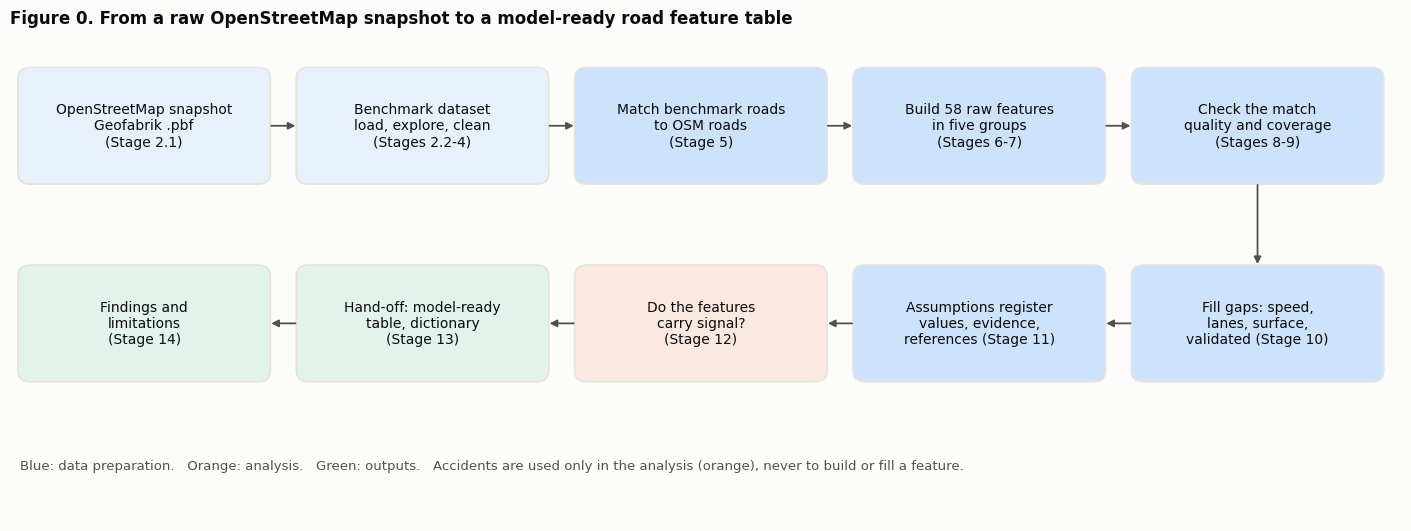

In [4]:
def draw_pipeline_overview():
    """Figure 0: the whole pipeline as boxes and arrows (no data needed)."""
    apply_chart_style()
    fig, ax = plt.subplots(figsize=(14, 5.2), layout="constrained")
    ax.set_xlim(0, 14); ax.set_ylim(0, 5.2); ax.axis("off")
    width, step = 2.5, 2.8   # five columns with a clear gap for the arrows
    top = [("OpenStreetMap snapshot\nGeofabrik .pbf\n(Stage 2.1)", "src"), ("Benchmark dataset\nload, explore, clean\n(Stages 2.2-4)", "src"),
           ("Match benchmark roads\nto OSM roads\n(Stage 5)", "ext"), ("Build 58 raw features\nin five groups\n(Stages 6-7)", "ext"),
           ("Check the match\nquality and coverage\n(Stages 8-9)", "ext")]
    bottom = [("Fill gaps: speed,\nlanes, surface,\nvalidated (Stage 10)", "ext"), ("Assumptions register\nvalues, evidence,\nreferences (Stage 11)", "ext"),
              ("Do the features\ncarry signal?\n(Stage 12)", "ana"), ("Hand-off: model-ready\ntable, dictionary\n(Stage 13)", "out"),
              ("Findings and\nlimitations\n(Stage 14)", "out")]
    fill = {"src": "#e8f0fb", "ext": "#cde2fb", "ana": "#fbe9e1", "out": "#e2f3ec"}
    arrow = dict(arrowstyle="-|>", color=INK_SECONDARY, lw=1.3, shrinkA=2, shrinkB=2)
    for k in range(5):
        x = 0.1 + k * step
        ax.add_patch(FancyBboxPatch((x, 3.6), width, 1.2, boxstyle="round,pad=0.02,rounding_size=0.12", fc=fill[top[k][1]], ec=GRID_COLOR, lw=1.2))
        ax.text(x + width / 2, 4.2, top[k][0], ha="center", va="center", fontsize=10, color=INK)
        x_b = 0.1 + (4 - k) * step   # second row runs right to left, starting under the last box of the first row
        ax.add_patch(FancyBboxPatch((x_b, 1.5), width, 1.2, boxstyle="round,pad=0.02,rounding_size=0.12", fc=fill[bottom[k][1]], ec=GRID_COLOR, lw=1.2))
        ax.text(x_b + width / 2, 2.1, bottom[k][0], ha="center", va="center", fontsize=10, color=INK)
        if k < 4:
            ax.annotate("", xy=(x + step, 4.2), xytext=(x + width, 4.2), arrowprops=arrow)
            ax.annotate("", xy=(x_b - (step - width), 2.1), xytext=(x_b, 2.1), arrowprops=arrow)
    ax.annotate("", xy=(0.1 + 4 * step + width / 2, 2.7), xytext=(0.1 + 4 * step + width / 2, 3.6), arrowprops=arrow)
    ax.text(0.1, 0.55, "Blue: data preparation.   Orange: analysis.   Green: outputs.   "
                       "Accidents are used only in the analysis (orange), never to build or fill a feature.",
            fontsize=9.5, color=INK_SECONDARY)
    ax.set_title("Figure 0. From a raw OpenStreetMap snapshot to a model-ready road feature table", loc="left")
    save_figure(fig, "fig0_pipeline_overview")
    plt.show()

draw_pipeline_overview()

### 1.5 Environment record
Versions are printed and saved into the metadata, so a result can be traced to the software that made it.

In [5]:
def environment_record():
    """Versions of the libraries that matter for reproducing the numbers."""
    import statsmodels, scipy, matplotlib as mpl
    record = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
              "statsmodels": statsmodels.__version__, "matplotlib": mpl.__version__}
    for name in ("osmnx", "geopandas", "shapely", "pyarrow"):
        try:
            record[name] = importlib.import_module(name).__version__
        except Exception:
            record[name] = "not installed"
    return record

ENVIRONMENT = environment_record()
print(json.dumps(ENVIRONMENT, indent=1))

{
 "python": "3.13.18",
 "numpy": "2.4.6",
 "pandas": "2.2.3",
 "scipy": "1.16.3",
 "statsmodels": "0.15.0",
 "matplotlib": "3.10.0",
 "osmnx": "2.1.1",
 "geopandas": "1.2.0",
 "shapely": "2.2.0",
 "pyarrow": "23.0.1"
}


### 1.6 Helper functions (collapse this section)
Small, general tools used throughout. The *methods* of the study (matching, feature building, gap-filling, analysis) are not here: each is defined in the stage that explains it.

| Group | Functions |
|---|---|
| OSM tag parsing | `as_text_list`, `parse_maxspeed_mph`, `parse_lanes`, `first_text`, `tag_is_set`, `yes_no_or_untagged`, `road_tag_values`, `node_tag_values` |
| Geometry and lookup | `straight_line_distance_m`, `nearest_osm_node`, `nearest_osm_road` |
| Statistics | `poisson_interval`, `weighted_trend` |
| Display | `show_markdown`, `format_percent`, `table_to_markdown`, `grouped_horizontal_bars`, `memory_report` |

In [6]:
import geopandas as gpd
import shapely
from scipy.spatial import cKDTree
from scipy.stats import chi2, norm
from shapely import STRtree
from IPython.display import Markdown, display

# ---------------------------------------------------------------- OSM tag parsing
def as_text_list(value):
    """Turn an OSM tag value into a list of lowercase strings.

    OSM tags can hold one value ("25 mph"), several joined by osmnx into a list (["25 mph", "30 mph"]),
    or a string that looks like a list. Missing values give an empty list.
    """
    if isinstance(value, (list, tuple, set, np.ndarray)):
        return [str(v).strip().lower() for v in value]
    if value is None or pd.isna(value):
        return []
    text = str(value).strip().lower()
    if text.startswith("["):
        try:
            return [str(v).strip().lower() for v in ast.literal_eval(text)]
        except (ValueError, SyntaxError):
            pass
    return [text]


def parse_maxspeed_mph(value):
    """Speed limit in mph. Takes the highest if several; unit-less numbers are read as mph; km/h is converted.
    Words such as "none" or "signals" give NaN.

    Note: the OSM wiki (Key:maxspeed) says a value without a unit is km/h. We read it as mph because US limits are posted in mph;
    Stage 7 measures how many tags this affects and whether their values look like mph limits (assumption A10 in Stage 11).
    """
    speeds = []
    for item in as_text_list(value):
        match = re.match(r"\s*(\d+(?:\.\d+)?)\s*(mph|km/h|kmh|kph)?", item)
        if match:
            number, unit = float(match.group(1)), match.group(2)
            speeds.append(number / 1.609344 if unit in ("km/h", "kmh", "kph") else number)
    return max(speeds) if speeds else np.nan


def parse_lanes(value):
    """Number of lanes. Takes the highest number if several are listed; missing gives NaN."""
    numbers = [float(n) for item in as_text_list(value) for n in re.findall(r"\d+(?:\.\d+)?", item)]
    return max(numbers) if numbers else np.nan


def first_text(value):
    """First value of a text tag, lowercase; missing gives NaN."""
    items = as_text_list(value)
    return items[0] if items else np.nan


def tag_is_set(value):
    """1.0 if the tag is present and not a "no"-type value (e.g. bridge=yes or bridge=viaduct), else 0.0."""
    items = as_text_list(value)
    return float(any(item not in ("no", "none", "false", "0", "") for item in items))


NO_VALUES = ("no", "none", "false", "0", "")  # tag values that mean "this is not present"


def yes_no_or_untagged(items):
    """From a list of tag values: 1.0 if any says the thing is present, 0.0 if all say no, NaN if untagged."""
    if not items:
        return np.nan
    return float(any(item not in NO_VALUES for item in items))


def road_tag_values(osm_roads, name):
    """One OSM road tag as a column; if no road has the tag at all, an empty column (with a notice)."""
    if name not in osm_roads.columns:
        print(f"notice: no OSM road has the tag '{name}'")
        return pd.Series(np.nan, index=range(len(osm_roads)), dtype=object)
    return osm_roads[name].reset_index(drop=True)


def node_tag_values(osm_nodes, name):
    """One OSM node tag as a column indexed by OSM node id; empty if no node has the tag."""
    if name not in osm_nodes.columns:
        print(f"notice: no OSM node has the tag '{name}'")
        return pd.Series(np.nan, index=osm_nodes.index, dtype=object)
    return osm_nodes[name]


def single_surface(value):
    """One surface for a road. A merged road whose OSM pieces have different surfaces is "mixed".

    Why: osmnx's simplification merges consecutive OSM pieces into one road and keeps their different tag values as a list
    built from a set, whose order can change between runs. Taking the first value (as v7 did) made the surface of such roads
    depend on the run. "mixed" is what OSM actually says about them, and it does not depend on order (assumption A17).
    """
    items = sorted(set(as_text_list(value)))
    if not items:
        return np.nan
    return items[0] if len(items) == 1 else "mixed"


def most_common_value(values):
    """One value per row for a tag that can hold a list (e.g. the OSM road's `highway`), independent of the list's order.

    Rows with one value keep it. Rows with several take the one most common in the state among single-valued rows
    (ties: alphabetical). Takes a Series of tag values; returns a Series of single values (NaN where untagged).
    """
    lists = values.map(lambda value: sorted(set(as_text_list(value))))
    counts = pd.Series([items[0] for items in lists if len(items) == 1], dtype=object).value_counts()
    return lists.map(lambda items: np.nan if not items else sorted(items, key=lambda item: (-counts.get(item, 0), item))[0])

In [7]:
# ---------------------------------------------------------------- geometry and nearest-object lookup
EARTH_RADIUS_M = 6371000.0


def straight_line_distance_m(lat1, lon1, lat2, lon2):
    """Distance in metres along the Earth's surface between two lat/lon points (haversine). Works on numbers or arrays."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * EARTH_RADIUS_M * np.arcsin(np.sqrt(a))


_SPATIAL_INDEX = {}  # spatial indexes are built once per table and reused


def nearest_osm_node(osm_nodes, x, y):
    """The OSM node closest to each point, found with a KD-tree on the node positions.

    Does what osmnx's nearest_nodes does, but needs only the node table, not the (very large) graph.
    Takes `osm_nodes` (positions in metres) and the points' x and y in the same metre coordinates.
    Returns (OSM node ids, distances in metres), one per point.
    """
    key = ("nodes", id(osm_nodes), len(osm_nodes))
    if key not in _SPATIAL_INDEX:
        _SPATIAL_INDEX[key] = cKDTree(np.column_stack([osm_nodes.geometry.x.to_numpy(), osm_nodes.geometry.y.to_numpy()]))
    distance, position = _SPATIAL_INDEX[key].query(np.column_stack([x, y]))
    return osm_nodes.index.to_numpy()[position], distance


def nearest_osm_road(osm_roads, x, y):
    """The OSM road closest to each point, found with a spatial index on the road shapes.

    Does what osmnx's nearest_edges does, but needs only the road table. The two directions of a two-way road
    have the same shape, so one of them is returned.
    Returns (position of the closest road in `osm_roads`, distance in metres), one per point.
    """
    key = ("roads", id(osm_roads), len(osm_roads))
    if key not in _SPATIAL_INDEX:
        _SPATIAL_INDEX[key] = STRtree(osm_roads.geometry.to_numpy())
    pairs, distance = _SPATIAL_INDEX[key].query_nearest(shapely.points(x, y), return_distance=True, all_matches=False)
    position = np.full(len(x), -1)
    nearest_distance = np.full(len(x), np.nan)
    position[pairs[0]] = pairs[1]  # row 0: the point, row 1: the closest road
    nearest_distance[pairs[0]] = distance
    return position, nearest_distance

In [8]:
# ---------------------------------------------------------------- statistics
def poisson_interval(k, exposure):
    """Exact 95% Poisson interval for a rate: k events over `exposure` (arrays or numbers). Returns (low, high)."""
    k = np.asarray(k, dtype=float)
    exposure = np.asarray(exposure, dtype=float)
    low = np.where(k > 0, chi2.ppf(0.025, 2 * np.maximum(k, 1)) / 2 / exposure, 0.0)
    high = chi2.ppf(0.975, 2 * k + 2) / 2 / exposure
    return low, high


def weighted_trend(positions, log_ratio, se_log):
    """Straight-line trend of log(rate ratio) against the level's position (0, 1, 2, ...), weighted by 1/se^2.

    Why: to say in words whether the rate rises or falls as a feature's value increases, without reading every bar.
    Returns (slope per step as a ratio, p-value). The slope is exp(b), so 1.2 means +20% per step.
    Needs at least 3 levels with a usable standard error; otherwise returns (nan, nan).
    """
    x = np.asarray(positions, dtype=float)
    y = np.asarray(log_ratio, dtype=float)
    se = np.asarray(se_log, dtype=float)
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(se) & (se > 0)
    if ok.sum() < 3:
        return np.nan, np.nan
    x, y, w = x[ok], y[ok], 1 / se[ok] ** 2
    x_bar = np.sum(w * x) / np.sum(w)                     # weighted mean position
    sxx = np.sum(w * (x - x_bar) ** 2)                    # weighted sum of squares of the positions
    if sxx <= 0:
        return np.nan, np.nan
    slope = np.sum(w * (x - x_bar) * (y - np.sum(w * y) / np.sum(w))) / sxx
    # residual-based standard error (does not assume the reported se are exactly right)
    intercept = np.sum(w * y) / np.sum(w) - slope * x_bar
    residual = y - intercept - slope * x
    dof = ok.sum() - 2                                    # degrees of freedom of the straight-line fit
    scale = max(np.sum(w * residual ** 2) / dof, 1.0)   # never smaller than the reported precision
    slope_se = np.sqrt(scale / sxx)
    return float(np.exp(slope)), float(2 * (1 - norm.cdf(abs(slope / slope_se))))

In [9]:
# ---------------------------------------------------------------- display
def show_markdown(text):
    """Show text as formatted Markdown in the notebook."""
    display(Markdown(text))


def format_percent(value, digits=1):
    """0.1234 -> '12.3%'. NaN -> 'n/a'."""
    return "n/a" if value is None or not np.isfinite(value) else f"{100 * value:.{digits}f}%"


def memory_report(label):
    """Print how much memory this notebook's process is using right now, to find which stage needs the most."""
    import resource

    import psutil
    now = psutil.Process().memory_info().rss / 1e9
    peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6  # Linux reports kB
    print(f"[memory] {label}: now {now:.1f} GB, highest so far {peak:.1f} GB")


def grouped_horizontal_bars(ax, table, states, xlabel, value_format="{:.1%}"):
    """Horizontal bars, one group per row of `table` and one bar per state, with the value at the end of each bar."""
    positions = np.arange(len(table))
    x_max = max(float(np.nanmax(table[list(states)].to_numpy())) * 1.2, 0.05)
    offsets = (-0.2, 0.2) if len(states) == 2 else (0.0,)
    for offset, state in zip(offsets, states):
        ax.barh(positions + offset, table[state].to_numpy(), height=0.34, color=STATE_COLORS[state], label=state)
        for y, value in zip(positions + offset, table[state].to_numpy()):
            ax.text(value + 0.012 * x_max, y, value_format.format(value), va="center", fontsize=9, color=INK_SECONDARY)
    ax.set_yticks(positions)
    ax.set_yticklabels(table.index)
    ax.invert_yaxis()
    ax.set_xlim(0, x_max)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
    ax.set_xlabel(xlabel)
    ax.xaxis.grid(True)


def table_to_markdown(table, float_format="{:,.3g}"):
    """A small DataFrame as a Markdown table (so wide text wraps nicely in the notebook)."""
    index_name = " / ".join(str(n) for n in table.index.names if n) if table.index.nlevels > 1 else str(table.index.name or "")
    columns = [index_name] + [str(c) for c in table.columns]
    lines = ["| " + " | ".join(columns) + " |", "|" + "---|" * len(columns)]
    for index, row in table.iterrows():
        cells = [" / ".join(str(part) for part in index) if isinstance(index, tuple) else str(index)]
        for value in row.tolist():
            if isinstance(value, (float, np.floating)):
                if not np.isfinite(value):
                    cells.append("")
                elif float(value).is_integer() and abs(value) >= 1000:   # counts: 116,196, not 1.16e+05
                    cells.append(f"{value:,.0f}")
                else:
                    cells.append(float_format.format(value))
            elif isinstance(value, (int, np.integer)) and not isinstance(value, bool):
                cells.append(f"{value:,}")
            else:
                cells.append(str(value).replace("|", "/").replace("\n", " "))
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)

**Self-test of the tag parsers.** The parsers decide what every speed limit and lane count means, so they are checked against hand-written cases before anything runs.
A failing assertion stops the notebook here rather than corrupting the features silently.

In [10]:
assert parse_maxspeed_mph("25 mph") == 25
assert parse_maxspeed_mph("35") == 35                                   # unit-less is read as mph (assumption A10, checked in Stage 7)
assert abs(parse_maxspeed_mph("80 km/h") - 49.7) < 0.1                  # km/h converted
assert parse_maxspeed_mph(["25 mph", "35 mph"]) == 35                   # several values: the highest
assert np.isnan(parse_maxspeed_mph("none")) and np.isnan(parse_maxspeed_mph("signals")) and np.isnan(parse_maxspeed_mph(np.nan))
assert parse_lanes("2") == 2 and parse_lanes(["2", "3"]) == 3 and np.isnan(parse_lanes(np.nan))
assert tag_is_set("yes") == 1.0 and tag_is_set("viaduct") == 1.0 and tag_is_set("no") == 0.0 and tag_is_set(np.nan) == 0.0
assert yes_no_or_untagged(["yes"]) == 1.0 and yes_no_or_untagged(["no"]) == 0.0 and np.isnan(yes_no_or_untagged([]))
assert first_text("Asphalt") == "asphalt" and isinstance(first_text(np.nan), float)
low, high = poisson_interval(10, 1.0)
assert 4.7 < low < 4.9 and 18 < high < 18.6                              # exact interval for 10 events
assert single_surface("Asphalt") == "asphalt" and single_surface(["concrete", "asphalt"]) == single_surface(["asphalt", "concrete"]) == "mixed"
assert np.isnan(single_surface(np.nan))
assert list(most_common_value(pd.Series(["primary", "primary", ["trunk", "primary"], ["primary", "trunk"], "trunk", np.nan]))[:5]) == ["primary"] * 4 + ["trunk"]
print("tag parsers and interval helper: all checks passed")

tag parsers and interval helper: all checks passed


## 2. Load the data
### 2.1 OpenStreetMap: from a dated snapshot to road, junction and place tables
> **What.** For each state we take a dated OpenStreetMap snapshot (a Geofabrik `.pbf` file) and cut it into three things:
> (1) the road ways of the 14 road types the benchmark uses, as `.osm` XML; (2) the places used by the nearby-places features
> (schools, bars, restaurants, bus stops, parking), as GeoJSON; (3) from the road XML, two flat tables built with osmnx (Boeing 2017): OSM *nodes* (junctions) and OSM *roads*
> (one row per directed road piece, with its tags and shape in metres).
>
> **Why.** The public Overpass API was at capacity when we started (HTTP 502), and a downloaded snapshot is reproducible: the same file gives the same features.
> osmnx cannot read `.pbf`, and the full file holds far more than roads, so `osmium` filters first. Only the two tables are kept; the graph object is dropped,
> because Maryland's graph needs about 10 GB while it is built and nothing later needs it. The build runs in a separate process so its memory is returned afterwards.
>
> **How to get the snapshot (once per state).** Open https://download.geofabrik.de/north-america/us.html, click the state, download the `.osm.pbf`
> (e.g. `delaware-261018.osm.pbf`, a snapshot of 18 Oct 2026, read from the file name), and put it unchanged in `MyDrive/cs5284_project/data/`.
> The notebook then makes `DE_osm_roads.zip` and `DE_osm_places.zip` next to it and never changes the `.pbf` or the benchmark zip.
>
> **Alternatives considered.** Overpass API (not reproducible, rate-limited); `pyrosm` (reads `.pbf` directly, but we need osmnx's simplification);
> keeping the whole graph (out of memory for Maryland on a standard Colab machine).
>
> **Limit.** The snapshot is from 2026 and the accidents from 2009-2022. Roads built, closed or re-tagged since then differ from what existed when the accidents happened (limitation L1).

In [11]:
STATE_NAMES = {"DE": "delaware", "MD": "maryland"}  # Geofabrik file names start with these

# The dataset's 14 road types; the road file keeps only ways with one of these `highway` values.
ROAD_HIGHWAY_VALUES = ["motorway", "motorway_link", "trunk", "trunk_link", "primary", "primary_link",
                       "secondary", "secondary_link", "tertiary", "tertiary_link", "unclassified",
                       "residential", "living_street", "road"]

# Places for the nearby_places "surroundings" group: `amenity` values, and bus stops (a `highway` value).
PLACE_AMENITY_VALUES = ["school", "bar", "pub", "restaurant", "fast_food", "parking"]
PLACE_HIGHWAY_VALUES = ["bus_stop"]


def run_osmium(arguments):
    """Run one osmium command line (installing osmium-tool first if Colab does not have it) and stop on failure."""
    if shutil.which("osmium") is None:
        print("installing osmium-tool ...")
        subprocess.run(["apt-get", "-qq", "install", "-y", "osmium-tool"], check=True)
    print("osmium", " ".join(str(a) for a in arguments))
    subprocess.run(["osmium", *[str(a) for a in arguments]], check=True)


def find_state_pbf(state, data_dir):
    """The Geofabrik .pbf for a state in the Drive data folder (e.g. delaware-261018.osm.pbf).

    If several dated files exist, the latest date is used.
    """
    candidates = sorted(data_dir.glob(f"{STATE_NAMES[state]}-*.osm.pbf"))
    if not candidates:
        raise FileNotFoundError(f"No {STATE_NAMES[state]}-*.osm.pbf in {data_dir}. Download it from Geofabrik first.")
    print("using", candidates[-1].name)
    return candidates[-1]


def prepare_osm_roads_zip(state, data_dir, local_dir, overwrite=False):
    """Make `{state}_osm_roads.zip` in the Drive data folder from the state's Geofabrik .pbf.

    Keeps only the dataset's road types (with the points they use and those points' tags) and writes them as .osm XML,
    which osmnx can read. If the zip already exists and overwrite is False, nothing happens. Returns the zip's path.
    """
    zip_path = data_dir / f"{state}_osm_roads.zip"
    if zip_path.exists() and not overwrite:
        print(f"{zip_path.name} already exists; skipping")
        return zip_path

    pbf = find_state_pbf(state, data_dir)
    filtered = local_dir / f"{state}_roads.osm.pbf"
    xml = local_dir / f"{state}_roads.osm"

    # Keep only ways tagged with one of the road types (osmium keeps the nodes they use by default).
    run_osmium(["tags-filter", pbf, "w/highway=" + ",".join(ROAD_HIGHWAY_VALUES), "-o", filtered, "--overwrite"])
    # Convert to XML, the format osmnx reads.
    run_osmium(["cat", filtered, "-o", xml, "--overwrite"])

    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
        archive.write(xml, arcname=xml.name)
    for path in (filtered, xml, zip_path):
        print(f"{path.name}: {path.stat().st_size / 1e6:.1f} MB")
    return zip_path


def prepare_osm_places_zip(state, data_dir, local_dir, overwrite=False):
    """Make `{state}_osm_places.zip` in the Drive data folder: schools, bars, restaurants, bus stops, parking.

    Places can be points or areas (a school is often an outline), so they are exported as GeoJSON and the centre of
    each is used later. If the zip already exists and overwrite is False, nothing happens. Returns the zip's path.
    """
    zip_path = data_dir / f"{state}_osm_places.zip"
    if zip_path.exists() and not overwrite:
        print(f"{zip_path.name} already exists; skipping")
        return zip_path

    pbf = find_state_pbf(state, data_dir)
    filtered = local_dir / f"{state}_places.osm.pbf"
    geojson = local_dir / f"{state}_places.geojsonseq"

    # Keep nodes, ways and relations (nwr) with any of the place tags.
    run_osmium(["tags-filter", pbf, "nwr/amenity=" + ",".join(PLACE_AMENITY_VALUES),
                "nwr/highway=" + ",".join(PLACE_HIGHWAY_VALUES), "-o", filtered, "--overwrite"])
    # One GeoJSON feature per line; areas become polygons.
    run_osmium(["export", filtered, "-f", "geojsonseq", "-o", geojson, "--overwrite"])

    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
        archive.write(geojson, arcname=geojson.name)
    for path in (filtered, geojson, zip_path):
        print(f"{path.name}: {path.stat().st_size / 1e6:.1f} MB")
    return zip_path


def load_osm_drive_network_from_zip(state, data_dir, local_dir):
    """Build the OSM road network for a state from the zip saved on Drive.

    Returns `osm_graph` (osmnx graph in metres), `osm_nodes` (one row per OSM node with its tags) and
    `osm_roads` (one row per directed OSM road, index = start node, end node, key).
    """
    import osmnx as ox
    print("osmnx version:", ox.__version__)

    # Unpack the XML into local storage, unless it is already there (utils.read_data may have done it).
    xml_path = local_dir / f"{state}_roads.osm"
    if not xml_path.exists():
        with zipfile.ZipFile(data_dir / f"{state}_osm_roads.zip") as archive:
            archive.extractall(local_dir)

    # Ask for the extra tags BEFORE building; osmnx drops tags it was not told to keep.
    # Keep only the tags our features use: fewer tags means a smaller graph in memory.
    ox.settings.useful_tags_way = ["highway", "maxspeed", "lanes", "surface", "bridge", "tunnel", "junction", "oneway",
                                   "lit", "sidewalk", "cycleway", "cycleway:left", "cycleway:right", "cycleway:both"]
    ox.settings.useful_tags_node = ["highway", "crossing", "traffic_calming"]

    # simplify=True merges road bends so a road runs between intersections.
    # retain_all=True keeps disconnected pieces of the network instead of only the largest one.
    osm_graph = ox.graph_from_xml(xml_path, simplify=True, retain_all=True)

    # Convert coordinates to metres so distances and thresholds are in metres.
    osm_graph = ox.project_graph(osm_graph)

    osm_nodes, osm_roads = ox.graph_to_gdfs(osm_graph)
    return osm_graph, osm_nodes, osm_roads


def build_osm_tables(state, data_dir, local_dir):
    """Build the OSM nodes and roads tables in a separate process and save them, so the big graph never stays in memory.

    The work runs in a child process; when it exits, all its memory goes back to the system.
    IMPORTANT: run this BEFORE loading the dataset (utils.read_data), so the child has the memory to itself.
    Saves `{state}_osm_nodes.pkl` and `{state}_osm_roads.pkl` in the local folder (skipped if both already exist).
    """
    import multiprocessing

    nodes_path = local_dir / f"{state}_osm_nodes.pkl"
    roads_path = local_dir / f"{state}_osm_roads.pkl"
    if nodes_path.exists() and roads_path.exists():
        print(f"{state} OSM tables already built; skipping")
        return

    prepare_osm_roads_zip(state, data_dir, local_dir)
    memory_report("before the OSM build starts")

    def build():
        osm_graph, osm_nodes, osm_roads = load_osm_drive_network_from_zip(state, data_dir, local_dir)
        osm_nodes.to_pickle(nodes_path)
        osm_roads.to_pickle(roads_path)

    process = multiprocessing.get_context("fork").Process(target=build)
    process.start()
    process.join()
    if process.exitcode != 0:
        raise RuntimeError(f"OSM build failed (exit code {process.exitcode}). -9 means it ran out of memory.")
    memory_report("after the OSM build")


def load_osm_tables(state, local_dir):
    """Read the OSM nodes and roads tables saved by `build_osm_tables`. Returns (osm_nodes, osm_roads)."""
    return pd.read_pickle(local_dir / f"{state}_osm_nodes.pkl"), pd.read_pickle(local_dir / f"{state}_osm_roads.pkl")


def saved_feature_columns(state, data_dir):
    """Column names of a state's saved feature file, or None if there is no file."""
    path = data_dir / f"{state}_osm_matched_roads.parquet"
    if not path.exists():
        return None
    import pyarrow.parquet as pq
    return pq.ParquetFile(path).schema.names


def saved_features_are_current(state, data_dir):
    """True if the state's saved feature file exists and was built by this PIPELINE_VERSION (an older file is rebuilt)."""
    meta_path = data_dir / f"{state}_osm_matching_meta.json"
    if not (data_dir / f"{state}_osm_matched_roads.parquet").exists() or not meta_path.exists():
        return False
    saved = json.loads(meta_path.read_text()).get("pipeline_version")
    if saved != PIPELINE_VERSION:
        print(f"{state}: saved features are version {saved}, this notebook is {PIPELINE_VERSION}: they will be rebuilt")
        return False
    return True

**Run: build the OSM tables.** This is deliberately **before** the benchmark is loaded (Stage 2.2) so the build has the machine's memory to itself.
A state whose features are already saved is skipped unless `FORCE_REBUILD` is set.

In [12]:
for state in STATES:
    if saved_features_are_current(state, DATA_DIR) and not FORCE_REBUILD:
        print(f"{state}: features already saved; no OSM build needed")
    else:
        build_osm_tables(state, DATA_DIR, LOCAL_DATA_DIR)

DE: saved features are version 3.0, this notebook is 3.1: they will be rebuilt
DE_osm_roads.zip already exists; skipping
[memory] before the OSM build starts: now 0.3 GB, highest so far 0.3 GB
osmnx version: 2.1.1
[memory] after the OSM build: now 0.3 GB, highest so far 0.3 GB


### 2.2 The benchmark: from sparse matrices to node and road tables
> **What.** `read_benchmark` unpacks the benchmark for each state in `STATES` (the team's `utils.read_data`, which always loads both states, restricted to the chosen ones). We turn its sparse matrices into two flat tables:
> one row per **node** (intersection) and one row per **directed road**, in the order of the adjacency matrix, because everything downstream
> (matching, the saved feature file, the GNN) relies on that order.
>
> **Why.** Matching needs coordinates per node and a length per road; the matrix form cannot be matched against OSM directly.
>
> **Alternative.** Matching on the sparse matrices directly (faster, but unreadable and impossible to check by eye).

In [13]:
def load_dataset_node_and_road_tables(info):
    """Turn the dataset's graph into two plain tables, one row per node and one per road.

    Takes `info`, the dict that `utils.read_data` returns for one state (e.g. data["DE"]).
    Returns:
        nodes: one row per intersection (node_id, lat, lon, node_idx).
        roads: one row per directed road, in the same order as `adj`
               (node_1_idx, node_2_idx, length_m, road_u, road_v, has_reverse, u_lt_v).
    The dataset's lat and lon columns are swapped; this function fixes that.
    """
    # The road network as a sparse matrix. coalesce() puts its entries in a fixed order.
    adj = info["adj"].coalesce()

    # Node files exist for every month; positions are the same in all of them, so take the first.
    nodes = pd.read_csv(next((info["filepath"] / "Nodes").glob("node_features_*.csv")))[["node_id", "lat", "lon"]]

    # The release has the two columns swapped: the column named lat holds longitudes and vice versa.
    nodes = nodes.rename(columns={"lat": "lon", "lon": "lat"})

    # Check the swap is fixed. DE and MD both lie between 37-41 N and 74-80 W.
    # A plain +/-90 check would not catch a swap, because -75 is also a valid latitude.
    assert nodes["lat"].between(37, 41).all() and nodes["lon"].between(-80, -74).all()

    # One row per matrix row, otherwise the node numbering cannot be trusted.
    assert len(nodes) == adj.shape[0]

    # The dataset refers to nodes by position (0, 1, 2, ...). Assumes the file rows are in that order.
    nodes["node_idx"] = np.arange(len(nodes))

    # Start and end node of every directed road, in the matrix's order. Keep this order.
    src, dst = adj.indices().numpy()
    roads = pd.DataFrame({"node_1_idx": src, "node_2_idx": dst})

    # Road lengths are stored in their own sparse matrix; turn it into a start / end / length table.
    length_matrix = info["edges"]["length"].coalesce()
    length_index = length_matrix.indices().numpy()
    length = pd.DataFrame({"node_1_idx": length_index[0], "node_2_idx": length_index[1], "length_m": length_matrix.values().numpy()})

    # Attach each road's length. how="left" keeps every road; the assert checks no rows were added or lost.
    n_before = len(roads)
    roads = roads.merge(length, how="left", on=["node_1_idx", "node_2_idx"])
    assert len(roads) == n_before, "length merge changed the number of roads"

    # Undirected road key: 17->18 and 18->17 both become (17, 18).
    roads["road_u"] = np.minimum(roads.node_1_idx, roads.node_2_idx)
    roads["road_v"] = np.maximum(roads.node_1_idx, roads.node_2_idx)

    # True if the opposite direction also exists, i.e. the road is two-way.
    pair = set(zip(roads.node_1_idx, roads.node_2_idx))
    roads["has_reverse"] = [(b, a) in pair for a, b in zip(roads.node_1_idx, roads.node_2_idx)]

    # True if the start node has the lower index. Crashes mostly sit on this direction.
    roads["u_lt_v"] = roads.node_1_idx < roads.node_2_idx
    return nodes, roads


EXPECTED_LENGTH_RATIO = (1.0, 1.3)  # a road is normally 0-30% longer than the straight line between its ends


def check_dataset_road_lengths(nodes, roads, verbose=True):
    """Check that the dataset's node order matches its road lengths.

    Roads refer to nodes by position. If the node file were in a different order, every coordinate we attach to a road
    would be wrong, and so would the OSM matching. A road's recorded length should be close to the straight-line distance
    between its ends. Returns the length / straight-line ratio for every road; raises an error if the median is outside
    EXPECTED_LENGTH_RATIO.
    """
    coverage = roads.length_m.notna().mean()
    assert coverage > 0.99, "too many roads without a length"

    lat, lon = nodes.lat.to_numpy(), nodes.lon.to_numpy()
    start, end = roads.node_1_idx.to_numpy(), roads.node_2_idx.to_numpy()
    straight = straight_line_distance_m(lat[start], lon[start], lat[end], lon[end])
    ratio = roads.length_m.to_numpy() / np.where(straight > 0, straight, np.nan)

    median = np.nanmedian(ratio)
    if verbose:
        print(f"roads with a length: {coverage:.4f}; median length / straight-line: {median:.3f} (expected {EXPECTED_LENGTH_RATIO})")
    if not (EXPECTED_LENGTH_RATIO[0] <= median <= EXPECTED_LENGTH_RATIO[1]):
        raise RuntimeError("Node order looks wrong: STOP and ask before continuing.")
    return ratio


def dataset_highway_class(info, roads):
    """The dataset's own road type for every road, as a text label.

    The dataset stores road type as 14 separate sparse matrices (one per type). We want one label per road so we can
    group results by road type. Returns a Series aligned with `roads` ("motorway", "residential", ...; "none" if no type
    was found). If a road has several types the last one found is used for this label, so the label is only a convenience for
    matching checks and gap-filling (assumption A8); roads with several types are EXCLUDED from the analysis (Stage 12), which uses `.attrs["multi_type"]`.
    The counts of roads with no type or several types are kept in the Series' `.attrs` (`n_no_type`, `n_several_types`).
    """
    n_nodes = info["adj"].shape[0]
    road_key = roads["node_1_idx"].to_numpy().astype(np.int64) * n_nodes + roads["node_2_idx"].to_numpy()
    order = np.argsort(road_key)
    sorted_keys = road_key[order]

    label = np.full(len(roads), "none", dtype=object)
    n_types = np.zeros(len(roads), dtype=int)
    for name, matrix in info["edges"].items():
        if name in ("oneway", "length"):
            continue  # not road types
        matrix = matrix.coalesce()
        index, value = matrix.indices().numpy(), matrix.values().numpy()
        keys = index[0].astype(np.int64)[value > 0] * n_nodes + index[1][value > 0]

        # Find each key among the roads (a key that is not a road is skipped).
        position = np.minimum(np.searchsorted(sorted_keys, keys), len(roads) - 1)
        found = sorted_keys[position] == keys
        rows = order[position[found]]
        label[rows] = str(name)
        n_types[rows] += 1

    result = pd.Series(label, index=roads.index, name="highway_class")
    result.attrs["n_no_type"] = int((n_types == 0).sum())
    result.attrs["n_several_types"] = int((n_types > 1).sum())
    result.attrs["multi_type"] = (n_types > 1)   # boolean array aligned with `roads`, used to leave these roads out of the trend analysis
    return result


def accident_totals_in_period(info, roads, first_month, last_month):
    """Total accidents on each directed road between two months (inclusive), e.g. "2015-01" to "2017-12".

    Every label-based number goes through this function, so the window is always explicit.
    Returns (an array aligned with `roads`, the length of the period in years).
    """
    accidents = info["accidents"]
    month_start = pd.to_datetime(accidents[["year", "month"]].assign(day=1))
    in_period = (month_start >= pd.Timestamp(first_month + "-01")) & (month_start <= pd.Timestamp(last_month + "-01"))

    totals = accidents[in_period].groupby(["node_1_idx", "node_2_idx"])["acc_count"].sum().rename("acc_total").reset_index()
    merged = roads[["node_1_idx", "node_2_idx"]].merge(totals, how="left", on=["node_1_idx", "node_2_idx"])
    assert len(merged) == len(roads), "accident merge changed the number of roads"

    n_months = (pd.Period(last_month, "M") - pd.Period(first_month, "M")).n + 1
    return merged["acc_total"].fillna(0).to_numpy(), n_months / 12

def monthly_accident_totals(info):
    """Total accidents per calendar month (index = first day of the month)."""
    accidents = info["accidents"]
    month_start = pd.to_datetime(accidents[["year", "month"]].assign(day=1))
    return accidents.groupby(month_start)["acc_count"].sum().sort_index()


def read_benchmark(drive_path, local_path, states):
    """Load the benchmark for the given states only: the team's `utils.read_data`, restricted to `states`.

    Why: `utils.read_data` always loads both Delaware and Maryland and unpacks every zip in the data folder, so it fails
    when one state's zip is absent (here MD.zip) and wastes time on the other state's OSM zips. This does the same steps,
    with the same file names and the same result for each state, but only for `states`. The team's utils.py is not changed.
    Returns {state: {"filepath", "adj", "edges", "edge_features_traffic", "accidents"}}.
    """
    import torch
    data = {}
    for state in states:
        zip_path = Path(drive_path) / f"{state}.zip"
        if not (Path(local_path) / state / "adj_matrix.pt").exists():
            if not zip_path.exists():
                raise FileNotFoundError(f"{zip_path} not found: put the benchmark zip for {state} in the Drive data folder")
            print(f"Extracting {zip_path.name} to {local_path}...")
            with zipfile.ZipFile(zip_path) as archive:
                archive.extractall(local_path)
        info = {"filepath": Path(local_path) / state}
        info["adj"] = torch.load(info["filepath"] / "adj_matrix.pt", map_location="cpu", weights_only=False).coalesce()
        info["edges"] = torch.load(info["filepath"] / "Edges" / "edge_features.pt", map_location="cpu", weights_only=False)
        info["edge_features_traffic"] = {int(path.stem.split("_")[-1]): torch.load(path, map_location="cpu", weights_only=False)
                                         for path in sorted((info["filepath"] / "Edges").glob("edge_features_traffic_*.pt"))}
        info["accidents"] = pd.read_csv(info["filepath"] / "accidents_monthly.csv")
        data[state] = info
        print(f"{state}: loaded from {info['filepath']}")
    return data

**Run: load the benchmark** (after the OSM tables are built, so memory is free). The node-order check stops the notebook if positions and road lengths disagree.

In [14]:
data = read_benchmark(DATA_DIR, LOCAL_DATA_DIR, STATES)

dataset_tables = {}
for state in STATES:
    info = data[state]
    nodes_raw, roads_raw = load_dataset_node_and_road_tables(info)
    length_ratio = check_dataset_road_lengths(nodes_raw, roads_raw)
    classes_raw = dataset_highway_class(info, roads_raw)
    dataset_tables[state] = {"nodes": nodes_raw, "roads": roads_raw, "highway_class": classes_raw,
                             "monthly": monthly_accident_totals(info), "length_ratio": length_ratio}
    print(f"{state}: {len(nodes_raw):,} nodes, {len(roads_raw):,} directed roads, {len(info['accidents']):,} accident rows")

Extracting DE.zip to /content/data...


/usr/local/lib/python3.13/dist-packages/torch/_utils.py:358: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  result = torch.sparse_coo_tensor(


DE: loaded from /content/data/DE
roads with a length: 1.0000; median length / straight-line: 1.000 (expected (1.0, 1.3))
DE: 49,023 nodes, 116,196 directed roads, 374,987 accident rows


## 3. Explore the raw accident data
Three views that the rest of the work depends on: the monthly series (is there a gap or a partial month?), how unevenly accidents fall on roads
(why counts per road are hard to predict), and the accident rate per kilometre by road type (why road type is always a control).
The grey band in the first panel marks the month that Stage 4 drops; the other two panels use the usable months only.

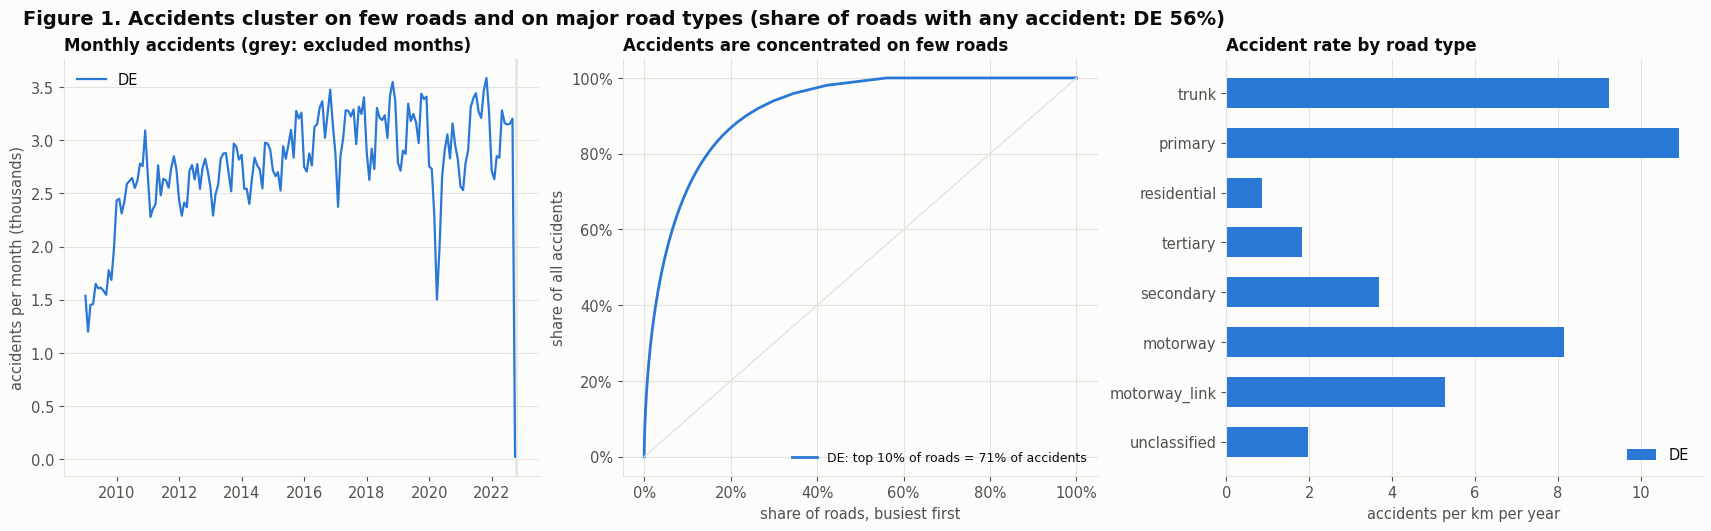

**DE**: top 1% of roads carry 24.0% of accidents, top 10% carry 70.6%; 55.9% of physical roads have any accident in 2009-01 to 2022-09.

In [15]:
def physical_roads_basic(roads, highway_class, totals):
    """One row per physical road (both directions merged): length, accidents, road type."""
    frame = pd.DataFrame({"road_u": roads["road_u"].to_numpy(), "road_v": roads["road_v"].to_numpy(),
                          "length_m": roads["length_m"].to_numpy(), "accidents": totals, "road_type": highway_class.to_numpy()})
    return frame.groupby(["road_u", "road_v"]).agg(length_m=("length_m", "mean"), accidents=("accidents", "sum"), road_type=("road_type", "first"))


def concentration_curve(accidents):
    """Share of accidents on the busiest x% of roads. Returns (x shares of roads, y shares of accidents), both increasing from 0 to 1."""
    sorted_counts = np.sort(np.asarray(accidents, dtype=float))[::-1]
    cumulative = np.concatenate([[0], np.cumsum(sorted_counts)]) / max(sorted_counts.sum(), 1)
    return np.linspace(0, 1, len(cumulative)), cumulative


def dataset_overview_tables(state, info, tables):
    """Numbers behind the exploration figure for one state (usable window only)."""
    first, last = USABLE_MONTHS.get(state, (tables["monthly"].index.min().strftime("%Y-%m"), tables["monthly"].index.max().strftime("%Y-%m")))
    totals, years = accident_totals_in_period(info, tables["roads"], first, last)
    physical = physical_roads_basic(tables["roads"], tables["highway_class"], totals)
    x, y = concentration_curve(physical["accidents"].to_numpy())
    share_top10 = float(np.interp(0.10, x, y))
    share_top1 = float(np.interp(0.01, x, y))
    by_type = physical.groupby("road_type").agg(roads=("accidents", "size"), km=("length_m", lambda s: s.sum() / 1000), accidents=("accidents", "sum"))
    by_type["km_share"] = by_type["km"] / by_type["km"].sum()
    by_type["accident_share"] = by_type["accidents"] / by_type["accidents"].sum()
    by_type["rate_per_km_year"] = by_type["accidents"] / (by_type["km"] * years)
    return {"first": first, "last": last, "years": years, "physical": physical, "curve": (x, y), "share_top10": share_top10,
            "share_top1": share_top1, "share_with_accident": float((physical["accidents"] > 0).mean()), "by_type": by_type.sort_values("accidents", ascending=False)}


def plot_dataset_overview(overview, tables_by_state):
    """Figure 1: monthly series, concentration of accidents, and rate by road type."""
    apply_chart_style()
    states = list(overview)
    fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), layout="constrained")
    ax_time, ax_conc, ax_type = axes
    for state in states:
        monthly = tables_by_state[state]["monthly"]
        ax_time.plot(monthly.index, monthly.to_numpy() / 1000, color=STATE_COLORS[state], lw=1.6, label=state)
        first, last = (pd.Timestamp(m + "-01") for m in (overview[state]["first"], overview[state]["last"]))
        for gap in (monthly.index[monthly.index < first], monthly.index[monthly.index > last]):
            if len(gap):
                ax_time.axvspan(gap.min(), gap.max() + pd.offsets.MonthEnd(0), color=GRID_COLOR, alpha=0.8, lw=0)
    ax_time.set_ylabel("accidents per month (thousands)")
    ax_time.set_title("Monthly accidents (grey: excluded months)")
    ax_time.legend(loc="upper left")
    ax_time.yaxis.grid(True)

    for state in states:
        x, y = overview[state]["curve"]
        ax_conc.plot(x, y, color=STATE_COLORS[state], lw=2, label=f"{state}: top 10% of roads = {overview[state]['share_top10']:.0%} of accidents")
    ax_conc.plot([0, 1], [0, 1], color=GRID_COLOR, lw=1)
    ax_conc.set_xlabel("share of roads, busiest first")
    ax_conc.set_ylabel("share of all accidents")
    ax_conc.set_title("Accidents are concentrated on few roads")
    ax_conc.legend(loc="lower right", fontsize=9)
    ax_conc.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax_conc.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax_conc.grid(True)

    rate = pd.DataFrame({s: overview[s]["by_type"]["rate_per_km_year"] for s in states})
    keep = overview[states[0]]["by_type"]["accidents"].index[:8]
    rate = rate.reindex([t for t in keep if t in rate.index])
    positions = np.arange(len(rate))
    offsets = (-0.2, 0.2) if len(states) == 2 else (0.0,)
    for offset, state in zip(offsets, states):
        ax_type.barh(positions + offset, rate[state].fillna(0).to_numpy(), height=0.34 if len(states) == 2 else 0.6, color=STATE_COLORS[state], label=state)
    ax_type.set_yticks(positions); ax_type.set_yticklabels(rate.index); ax_type.invert_yaxis()
    ax_type.set_xlabel("accidents per km per year")
    ax_type.set_title("Accident rate by road type")
    ax_type.legend(loc="lower right")
    ax_type.xaxis.grid(True)
    any_accident = ", ".join("{} {:.0%}".format(s, overview[s]["share_with_accident"]) for s in states)
    fig.suptitle("Figure 1. Accidents cluster on few roads and on major road types (share of roads with any accident: " + any_accident + ")",
                 x=0.01, ha="left")
    save_figure(fig, "fig1_dataset_overview")
    plt.show()


overview = {state: dataset_overview_tables(state, data[state], dataset_tables[state]) for state in STATES}
plot_dataset_overview(overview, dataset_tables)
for state in STATES:
    show_markdown(f"**{state}**: top 1% of roads carry {format_percent(overview[state]['share_top1'])} of accidents, top 10% carry {format_percent(overview[state]['share_top10'])}; "
       f"{format_percent(overview[state]['share_with_accident'])} of physical roads have any accident in {overview[state]['first']} to {overview[state]['last']}.")

## 4. Clean the benchmark data
Each row of the cleaning log is one decision. **Type** says whether it *changes* the data, only *checks* it, or sets a *rule*;
**data affected** says how much of the data it touched. The functions measure the evidence first; nothing here changes a feature.

* **Partial months.** A month whose accident total is less than half the median of the surrounding year was probably only partly recorded.
  The detector *checks* the configured exclusion (`USABLE_MONTHS`); a genuine drop such as the spring 2020 lockdown can also be flagged, and that is real data we keep.
* **Direction merge.** The dataset puts each accident on *one* direction of a two-way road; we measure how one-sided that is.
* **Coordinate swap and node order.** Measured from the node file and from road lengths against straight-line distances.

How the raw OSM tags (speed limits, lanes) were read is reported where they are read, in Stage 7.

In [16]:
def detect_partial_months(monthly, window_months=12, threshold=0.5):
    """Months whose total is below `threshold` times the median of the other months within `window_months` either side."""
    flagged = []
    for month, value in monthly.items():
        near = monthly.drop(month)
        near = near[(near.index >= month - pd.DateOffset(months=window_months)) & (near.index <= month + pd.DateOffset(months=window_months))]
        if len(near) >= 3 and value < threshold * near.median():
            flagged.append(month)
    return flagged


def configured_excluded_months(monthly, state):
    """Months present in the data but outside USABLE_MONTHS[state] (all months are usable if the state has no entry)."""
    if state not in USABLE_MONTHS:
        return []
    first, last = (pd.Timestamp(m + "-01") for m in USABLE_MONTHS[state])
    return [m for m in monthly.index if m < first or m > last]


def direction_evidence(roads, totals):
    """How one-sided the accident records are on two-way roads.

    Returns a dict with: the share of two-way roads with accidents whose accidents sit on only one of the two directions,
    and the share of two-way-road accidents recorded on the direction going from the lower to the higher node index.
    """
    two_way = roads["has_reverse"].to_numpy()
    frame = pd.DataFrame({"u": roads["road_u"].to_numpy()[two_way], "v": roads["road_v"].to_numpy()[two_way],
                          "acc": totals[two_way], "lower_to_higher": roads["u_lt_v"].to_numpy()[two_way]})
    per_road = frame.groupby(["u", "v"]).agg(total=("acc", "sum"), sides=("acc", lambda s: int((s > 0).sum())))
    with_accidents = per_road[per_road["total"] > 0]
    return {"one_sided_share": float((with_accidents["sides"] == 1).mean()) if len(with_accidents) else np.nan,
            "lower_to_higher_share": float(frame.loc[frame["lower_to_higher"], "acc"].sum() / max(frame["acc"].sum(), 1)),
            "two_way_roads_with_accidents": int(len(with_accidents))}


def coordinate_swap_evidence(info):
    """Share of nodes whose raw `lat` column holds a longitude (-80 to -74) and raw `lon` holds a latitude (37 to 41)."""
    raw = pd.read_csv(next((info["filepath"] / "Nodes").glob("node_features_*.csv")))[["lat", "lon"]]
    return float((raw["lat"].between(-80, -74) & raw["lon"].between(37, 41)).mean())


def excluded_month_rows(info, excluded):
    """How many accident rows, and accidents, fall in the excluded months. Returns (rows, accidents)."""
    accidents = info["accidents"]
    month_start = pd.to_datetime(accidents[["year", "month"]].assign(day=1))
    in_excluded = month_start.isin(excluded)
    return int(in_excluded.sum()), float(accidents.loc[in_excluded, "acc_count"].sum())


def build_cleaning_log(state, info, nodes, roads, length_ratio, highway_class, monthly, flagged):
    """One row per cleaning or checking decision on the benchmark: its type, what we did, why, the measured evidence,
    how much data it touched, and its effect.

    Type is "change" (alters the data or what the analysis uses), "check" (verifies only; the run stops if it fails) or "rule" (a convention).
    Returns a DataFrame indexed by the decision.
    """
    excluded = configured_excluded_months(monthly, state)
    full_first, full_last = USABLE_MONTHS.get(state, (monthly.index.min().strftime("%Y-%m"), monthly.index.max().strftime("%Y-%m")))
    totals_all, _ = accident_totals_in_period(info, roads, monthly.index.min().strftime("%Y-%m"), monthly.index.max().strftime("%Y-%m"))
    direction = direction_evidence(roads, totals_all)
    accidents = info["accidents"]
    bad_counts = int((accidents["acc_count"] <= 0).sum() + accidents["acc_count"].isna().sum())
    excluded_rows, excluded_accidents = excluded_month_rows(info, excluded)
    physical_roads = roads.groupby(["road_u", "road_v"]).ngroups
    multi = np.asarray(highway_class.attrs.get("multi_type", np.zeros(len(roads), dtype=bool)))
    multi_accident_share = totals_all[multi].sum() / max(totals_all.sum(), 1)

    def format_months(months):
        return ", ".join(m.strftime("%Y-%m") for m in months) if len(months) <= 6 else f"{len(months)} months ({months[0]:%Y-%m} to {months[-1]:%Y-%m})"

    rows = [
        ("change", "Swap latitude and longitude columns", "The release names the columns the wrong way round; positions were unusable otherwise.",
         f"{format_percent(coordinate_swap_evidence(info))} of nodes have a longitude in the `lat` column. After the swap all nodes fall inside 37-41 N, 74-80 W (asserted).",
         f"all {len(nodes):,} nodes", "All coordinates, matching and place counts depend on it."),
        ("check", "Validate node order", "Roads refer to nodes by row position; a shuffled node file would silently ruin every match.",
         f"Median recorded length / straight-line distance = {np.nanmedian(length_ratio):.3f} (expected {EXPECTED_LENGTH_RATIO[0]}-{EXPECTED_LENGTH_RATIO[1]}); "
         f"{format_percent(roads['length_m'].notna().mean(), 2)} of roads have a length.", "none (check only)", "The run stops if the check fails."),
        ("change", "Drop partial accident months", "Months with a fraction of the usual records would look like a real fall in risk.",
         f"Detector flags: {format_months(flagged) if flagged else 'none'}. Configured exclusions: {format_months(excluded) if excluded else 'none'}. "
         f"Usable window {full_first} to {full_last}.",
         f"{excluded_rows:,} accident rows ({excluded_accidents:,.0f} accidents) in {len(excluded)} month(s)" if excluded else "none",
         "A flagged month inside the window is a real drop (for example spring 2020), not a gap, and is kept."),
        ("change", "Merge the two directions of a two-way road", "Accidents are recorded on one direction only, so the other direction always shows zero.",
         f"Of {direction['two_way_roads_with_accidents']:,} two-way roads with accidents, {format_percent(direction['one_sided_share'])} have accidents on only one direction. "
         f"{format_percent(direction['lower_to_higher_share'])} of two-way-road accidents are on the lower-to-higher-index direction.",
         f"{len(roads):,} directed roads become {physical_roads:,} physical roads (analysis only)",
         "Directed roads are merged into physical roads for all analysis; OSM features are the same in both directions."),
        ("change", "Leave roads with more than one type out of the analysis", "The dataset stores road type as 14 matrices; some roads appear in more than one, and the comparisons need one type per road.",
         f"{highway_class.attrs.get('n_several_types', 0):,} roads have more than one type, {highway_class.attrs.get('n_no_type', 0):,} have none.",
         f"{int(multi.sum()):,} directed roads, {format_percent(multi_accident_share)} of accidents (analysis only)",
         "They stay in the feature table and the benchmark's own type columns are untouched. Matching checks and gap-filling use the last type found as a label (assumption A8)."),
        ("check", "Accident counts are positive", "Zero, negative or missing counts would corrupt rates.",
         f"{bad_counts:,} rows with count <= 0 or missing out of {len(accidents):,}.", f"{bad_counts:,} rows", "None expected; any would be dropped."),
        ("rule", "Missing stays missing", "A road without a speed-limit tag is unknown, not 'no speed limit'.",
         "Tag-based features are NaN when the tag is absent or the road is unmatched. For node flags (signals, stop signs, crossings) 0 means 'not mapped there', which is weaker than 'absent'.",
         "every untagged or unmatched road (measured in Stage 9)", "The analysis uses known values only (Stage 12)."),
        ("rule", "How OSM tags are read", "OSM tags are free text: '25 mph', '35', '80 km/h', 'none', or a list.",
         "Unit-less speeds are read as mph, km/h is converted, the highest value is kept when several are listed, words give missing; a road with several surfaces is 'mixed' (self-test in Stage 1.6).",
         "counted in Stage 7 (OSM tag cleaning)", "Defines what every speed-limit and lane value means."),
    ]
    columns = ["type", "decision", "why", "evidence", "data affected", "effect / note"]
    return pd.DataFrame(rows, columns=columns).set_index("decision")

In [17]:
cleaning_logs = {}
for state in STATES:
    tables = dataset_tables[state]
    tables["flagged"] = detect_partial_months(tables["monthly"])
    cleaning_logs[state] = build_cleaning_log(state, data[state], tables["nodes"], tables["roads"], tables["length_ratio"],
                                              tables["highway_class"], tables["monthly"], tables["flagged"])
    show_markdown(f"#### Cleaning log: {state}\n\n" + table_to_markdown(cleaning_logs[state]))

#### Cleaning log: DE

| decision | type | why | evidence | data affected | effect / note |
|---|---|---|---|---|---|
| Swap latitude and longitude columns | change | The release names the columns the wrong way round; positions were unusable otherwise. | 100.0% of nodes have a longitude in the `lat` column. After the swap all nodes fall inside 37-41 N, 74-80 W (asserted). | all 49,023 nodes | All coordinates, matching and place counts depend on it. |
| Validate node order | check | Roads refer to nodes by row position; a shuffled node file would silently ruin every match. | Median recorded length / straight-line distance = 1.000 (expected 1.0-1.3); 100.00% of roads have a length. | none (check only) | The run stops if the check fails. |
| Drop partial accident months | change | Months with a fraction of the usual records would look like a real fall in risk. | Detector flags: 2022-10. Configured exclusions: 2022-10. Usable window 2009-01 to 2022-09. | 23 accident rows (23 accidents) in 1 month(s) | A flagged month inside the window is a real drop (for example spring 2020), not a gap, and is kept. |
| Merge the two directions of a two-way road | change | Accidents are recorded on one direction only, so the other direction always shows zero. | Of 26,093 two-way roads with accidents, 100.0% have accidents on only one direction. 96.4% of two-way-road accidents are on the lower-to-higher-index direction. | 116,196 directed roads become 65,252 physical roads (analysis only) | Directed roads are merged into physical roads for all analysis; OSM features are the same in both directions. |
| Leave roads with more than one type out of the analysis | change | The dataset stores road type as 14 matrices; some roads appear in more than one, and the comparisons need one type per road. | 2,625 roads have more than one type, 0 have none. | 2,625 directed roads, 4.1% of accidents (analysis only) | They stay in the feature table and the benchmark's own type columns are untouched. Matching checks and gap-filling use the last type found as a label (assumption A8). |
| Accident counts are positive | check | Zero, negative or missing counts would corrupt rates. | 0 rows with count <= 0 or missing out of 374,987. | 0 rows | None expected; any would be dropped. |
| Missing stays missing | rule | A road without a speed-limit tag is unknown, not 'no speed limit'. | Tag-based features are NaN when the tag is absent or the road is unmatched. For node flags (signals, stop signs, crossings) 0 means 'not mapped there', which is weaker than 'absent'. | every untagged or unmatched road (measured in Stage 9) | The analysis uses known values only (Stage 12). |
| How OSM tags are read | rule | OSM tags are free text: '25 mph', '35', '80 km/h', 'none', or a list. | Unit-less speeds are read as mph, km/h is converted, the highest value is kept when several are listed, words give missing; a road with several surfaces is 'mixed' (self-test in Stage 1.6). | counted in Stage 7 (OSM tag cleaning) | Defines what every speed-limit and lane value means. |

## 5. Match benchmark roads to OpenStreetMap (method)
> **What.** Two steps. **Nodes:** the dataset stores each intersection's raw OSM id, so we try that first and accept it only if the two positions agree
> within `NODE_ID_COORD_TOL_M` (25 m); otherwise we take the nearest OSM node within `NODE_SNAP_MAX_M` (20 m). **Roads:** each benchmark road keeps the first of three tiers that works:
> *exact* (an OSM road runs between the two matched end nodes in the same direction; for parallel roads the closest in length wins), *reverse* (only the opposite direction exists),
> *nearest* (the OSM road nearest the road's midpoint, if within `ROAD_NEAREST_MAX_M` (30 m) **and** its length is within `ROAD_LEN_RATIO_RANGE` (0.6-1.6) times the benchmark length).
> Everything else is *unmatched*; the row is kept with empty OSM columns.
>
> **Why.** OSM tags belong to OSM roads. The benchmark was built from an older OSM extract, so some ids are gone and some roads were redrawn; the tiers recover as many as can be trusted without guessing.
> The length-ratio condition on the nearest tier stops a short side street from being matched to the long main road beside it.
> The distance tolerances follow the buffer principle for matching line features (Goodchild and Hunter 1997) and sit well above the typical positional error of OSM roads,
> about 6 m against Ordnance Survey data (Haklay 2010). No published value exists for the length ratio, so it is checked empirically in Stage 8.
>
> **Evidence.** Stage 8 reports match shares, the length ratio per tier, how often the benchmark's road type agrees with the OSM `highway` tag (a check the matcher never sees),
> and how the match rate would change under stricter or looser thresholds.
>
> **Alternatives considered.** Full map-matching of shapes (the benchmark has only end points, not geometry); a looser nearest tier (more matches, more wrong ones; see the sensitivity table).
>
> **Limit.** A match is a best guess. Tier shares say how many roads matched, not how many matched *correctly*; the road-type agreement in Stage 8 is the closest check we have.

In [18]:
def compare_dataset_and_osm_sizes(nodes, roads, osm_nodes, osm_roads):
    """Compare how many nodes and roads the dataset and OpenStreetMap have (ratios near 1 mean similar networks).

    Returns a dict with the four counts and the OSM / dataset ratios.
    """
    sizes = {"dataset_nodes": len(nodes), "osm_nodes": len(osm_nodes), "dataset_roads": len(roads), "osm_roads": len(osm_roads)}
    sizes["node_ratio"] = sizes["osm_nodes"] / sizes["dataset_nodes"]
    sizes["road_ratio"] = sizes["osm_roads"] / sizes["dataset_roads"]
    return sizes


def match_dataset_nodes_to_osm_nodes(nodes, osm_graph, osm_nodes):
    """Find, for every dataset node, the OSM node it corresponds to.

    Takes dataset `nodes`, `osm_graph` (no longer used; may be None) and `osm_nodes`.
    Returns a copy of `nodes` with extra columns:
        id_in_osm: the dataset's node_id exists in OSM.
        id_dist_m: distance between the dataset position and that OSM node (NaN if not in OSM).
        nearest_osm_id, nearest_dist_m: the closest OSM node by position, and how far it is.
        node_match: "id", "snap" (nearest node) or "none".
        osm_id: the matched OSM node id, or -1 when node_match is "none".
    """
    nodes = nodes.copy()

    # Dataset positions in the same metre-based coordinates as the OSM graph.
    points = gpd.GeoSeries(gpd.points_from_xy(nodes.lon, nodes.lat), crs=4326).to_crs(osm_nodes.crs)
    x, y = points.x.to_numpy(), points.y.to_numpy()

    # Nearest OSM node to every dataset node, by position, and the distance to it in metres.
    nearest_id, nearest_dist = nearest_osm_node(osm_nodes, x, y)
    nodes["nearest_osm_id"] = nearest_id
    nodes["nearest_dist_m"] = nearest_dist

    # Does the dataset's own OSM id exist in the OSM file?
    nodes["id_in_osm"] = nodes["node_id"].isin(osm_nodes.index)

    # For those, how far apart are the dataset position and the OSM node with that id? (NaN for ids not in OSM)
    osm_x = osm_nodes.geometry.x.reindex(nodes["node_id"]).to_numpy()
    osm_y = osm_nodes.geometry.y.reindex(nodes["node_id"]).to_numpy()
    nodes["id_dist_m"] = np.hypot(x - osm_x, y - osm_y)

    # Decision: trust the id if the positions agree, else the nearest node if it is close enough.
    id_ok = nodes["id_in_osm"] & (nodes["id_dist_m"] <= NODE_ID_COORD_TOL_M)
    snap_ok = ~id_ok & (nodes["nearest_dist_m"] <= NODE_SNAP_MAX_M)
    nodes["node_match"] = np.select([id_ok, snap_ok], ["id", "snap"], "none")
    nodes["osm_id"] = np.where(id_ok, nodes["node_id"], np.where(snap_ok, nodes["nearest_osm_id"], -1))
    return nodes


def match_dataset_roads_to_osm_roads(nodes, roads, osm_graph, osm_roads):
    """Find, for every dataset road, the OSM road it corresponds to (tiers: exact, reverse, nearest, unmatched).

    Takes `nodes` (with `osm_id` from `match_dataset_nodes_to_osm_nodes`), dataset `roads`, and `osm_roads`.
    Returns a copy of `roads` (same row order) with extra columns:
        osm_u, osm_v: OSM ids of the road's start and end nodes (-1 if the node had no match).
        match_type: "exact", "reverse", "nearest" or "unmatched".
        match_dist_m: 0 for exact and reverse; distance to the OSM road for nearest.
        osm_row: position of the matched road in `osm_roads` (-1 if unmatched). Use it to copy tags.
        osm_length_m: the matched OSM road's length.   len_ratio: osm_length_m / the dataset's length_m.
        osm_highway: the matched OSM road's own `highway` tag (for checking the match; NaN if unmatched).
        cand_dist_m, cand_len_ratio: for roads that reached the nearest tier, the distance and length ratio of the
            nearest candidate even when it was REJECTED. Lets us ask how many more roads a looser threshold would match.
    """
    roads = roads.copy()
    assert (roads.index == np.arange(len(roads))).all(), "roads must keep a default 0..N-1 index"
    n_roads = len(roads)

    # OSM ids of each road's two end nodes (-1 where the node was not matched).
    osm_id = nodes["osm_id"].to_numpy()
    roads["osm_u"] = osm_id[roads["node_1_idx"].to_numpy()]
    roads["osm_v"] = osm_id[roads["node_2_idx"].to_numpy()]

    # The OSM roads as a flat table, remembering each road's position in `osm_roads`.
    osm_table = pd.DataFrame({
        "u": osm_roads.index.get_level_values("u"),
        "v": osm_roads.index.get_level_values("v"),
        "osm_length_m": osm_roads["length"].to_numpy(),
        "osm_row": np.arange(len(osm_roads)),
    })

    # Results, one entry per dataset road.
    match_type = np.full(n_roads, "unmatched", dtype=object)
    osm_row = np.full(n_roads, -1)
    osm_length = np.full(n_roads, np.nan)
    match_dist = np.full(n_roads, np.nan)
    cand_dist = np.full(n_roads, np.nan)
    cand_ratio = np.full(n_roads, np.nan)

    def match_by_node_pair(todo, start_col, end_col):
        """OSM roads running from `start_col` to `end_col`; for parallel roads keep the closest length."""
        pairs = todo[[start_col, end_col, "length_m"]].reset_index(names="road")
        candidates = pairs.merge(osm_table, left_on=[start_col, end_col], right_on=["u", "v"])
        candidates["length_error"] = (candidates["osm_length_m"] - candidates["length_m"]).abs()
        best = candidates.sort_values("length_error").drop_duplicates("road")
        return best["road"].to_numpy(), best["osm_row"].to_numpy(), best["osm_length_m"].to_numpy()

    # Tier 1, exact: same direction as the dataset road.
    rows, found, lengths = match_by_node_pair(roads, "osm_u", "osm_v")
    match_type[rows], osm_row[rows], osm_length[rows], match_dist[rows] = "exact", found, lengths, 0.0

    # Tier 2, reverse: only for roads not yet matched; look for the OSM road running the other way.
    todo = roads[match_type == "unmatched"]
    rows, found, lengths = match_by_node_pair(todo, "osm_v", "osm_u")
    match_type[rows], osm_row[rows], osm_length[rows], match_dist[rows] = "reverse", found, lengths, 0.0

    # Tier 3, nearest: use the road's midpoint, in the same metre coordinates as the OSM graph.
    points = gpd.GeoSeries(gpd.points_from_xy(nodes.lon, nodes.lat), crs=4326).to_crs(osm_roads.crs)
    x, y = points.x.to_numpy(), points.y.to_numpy()
    start, end = roads["node_1_idx"].to_numpy(), roads["node_2_idx"].to_numpy()
    mid_x, mid_y = (x[start] + x[end]) / 2, (y[start] + y[end]) / 2

    left = np.flatnonzero(match_type == "unmatched")
    found, nearest_dist = nearest_osm_road(osm_roads, mid_x[left], mid_y[left])  # position of the closest road in osm_roads
    found_length = osm_roads["length"].to_numpy()[found]
    ratio = found_length / roads["length_m"].to_numpy()[left]
    cand_dist[left], cand_ratio[left] = nearest_dist, ratio                       # kept even for rejected candidates
    accept = (found >= 0) & (nearest_dist <= ROAD_NEAREST_MAX_M) & \
             (ratio >= ROAD_LEN_RATIO_RANGE[0]) & (ratio <= ROAD_LEN_RATIO_RANGE[1])
    rows = left[accept]
    match_type[rows], osm_row[rows] = "nearest", found[accept]
    osm_length[rows], match_dist[rows] = found_length[accept], nearest_dist[accept]

    roads["match_type"] = match_type
    roads["match_dist_m"] = match_dist
    roads["osm_row"] = osm_row
    roads["osm_length_m"] = osm_length
    roads["len_ratio"] = osm_length / np.where(roads["length_m"] > 0, roads["length_m"], np.nan)
    roads["cand_dist_m"] = cand_dist
    roads["cand_len_ratio"] = cand_ratio

    osm_highway = most_common_value(road_tag_values(osm_roads, "highway")).to_numpy(dtype=object)   # independent of list order (A17)
    roads["osm_highway"] = np.where(osm_row >= 0, osm_highway[np.maximum(osm_row, 0)], None)
    return roads


def matching_diagnostics(nodes, roads, sizes):
    """Everything worth keeping about the matching, as plain numbers (saved in the metadata so it survives reloading)."""
    def quantiles(series):
        q = series.dropna().quantile([0.05, 0.5, 0.95])
        return {"p05": float(q.iloc[0]), "p50": float(q.iloc[1]), "p95": float(q.iloc[2])} if len(series.dropna()) else {}

    by_tier = {}
    for tier, group in roads.groupby("match_type"):
        entry = {"roads": int(len(group))}
        if tier != "unmatched":
            entry.update({"len_ratio": quantiles(group["len_ratio"]),
                          "share_ratio_0.8_1.25": float(group["len_ratio"].between(0.8, 1.25).mean())})
        by_tier[tier] = entry
    return {
        "osm_sizes": {k: (float(v) if isinstance(v, float) else int(v)) for k, v in sizes.items()},
        "node_match_share": nodes["node_match"].value_counts(normalize=True).round(4).to_dict(),
        "dataset_node_id_found_in_osm": float(nodes["id_in_osm"].mean()),
        "id_found_but_position_differs": int((nodes["id_in_osm"] & (nodes["node_match"] != "id")).sum()),
        "nearest_node_distance_m": quantiles(nodes["nearest_dist_m"]),
        "road_match_share": roads["match_type"].value_counts(normalize=True).round(4).to_dict(),
        "road_match_by_tier": by_tier,
    }

## 6. Build the road features (method)
Five groups. All raw values are saved **unscaled, with missing kept as missing**. Stage 7 prints the catalogue (source tag, unit, meaning of empty or 0, fill rate) after the run.

| Group | What it measures | Needs a matched OSM road? |
|---|---|---|
| `road_character` | speed limit, lanes, surface, bridge, tunnel, from the OSM road's own tags | yes |
| `intersection_control` | signals, stop and give-way signs, crossings at each end; roundabout; mid-block counts | yes |
| `cycle_pedestrian_lighting` | cycleway, sidewalk and lighting tags (yes / tagged no / not tagged) | yes |
| `nearby_places` | schools, bars, food, parking, bus stops, crossings, signals within 100-1,000 m, and the distance to the nearest | no, position only |
| `road_shape` | curviness: length divided by the straight-line distance between the road's ends | no, benchmark geometry |

> **road_character.** Parse the OSM road's `maxspeed`, `lanes`, `surface`, `bridge`, `tunnel` once per OSM road and copy to matched benchmark roads. These describe the road and are not in the benchmark.
>
> **intersection_control.** Read the signal / stop / give-way / crossing tags at the OSM road's start and end nodes, because crashes cluster at intersections.
> osmnx's simplification deletes nodes that are not junctions, and with them their tags, so a signal or crossing between junctions ("mid-block") disappears.
> To recover them, every tagged point is read from the XML, and those that simplification removed are counted on the road they lie on (nearest road within `MIDBLOCK_NODE_MAX_M`, 15 m).
> Stage 8 shows how many were lost and recovered. **Alternative:** `simplify=False` (keeps every node, but multiplies the graph size and breaks the road-to-road correspondence).
>
> **cycle_pedestrian_lighting.** Three states per feature: 1 yes, 0 tagged "no", NaN not tagged. Only the plain `sidewalk` tag is read, not `sidewalk:left/right`.
>
> **nearby_places.** The road's midpoint is the reference; count places inside four radii and find the nearest. Places mean pedestrians, turning traffic and parking near the road,
> and every road gets a value. **Alternative:** road-to-place network distance (more faithful, far slower).
>
> **road_shape.** Road length divided by the straight-line distance between its ends, from the benchmark's own coordinates (no OSM tags). Bends reduce sight lines.
>
> **Left out on purpose:** node degree, road length and road type. The baseline already has them, and a graph model sees the network structure itself.

**road_character**

In [19]:
from shapely.geometry import shape

# The five feature groups; every feature column starts with one of these prefixes.
FEATURE_GROUP_PREFIXES = ("road_character", "intersection_control", "cycle_pedestrian_lighting", "nearby_places", "road_shape")


def feature_group_of_column(column):
    """The feature group a column belongs to (its prefix), or None for identifiers and diagnostics."""
    return next((group for group in FEATURE_GROUP_PREFIXES if column.startswith(group + "_")), None)


TAGGED_NODE_KINDS = ["signal", "stop", "give_way", "crossing", "traffic_calming"]


# Which place type each OSM tag value belongs to.
PLACE_TYPE_OF_TAG = {"school": "school", "bar": "bar_pub", "pub": "bar_pub", "restaurant": "food",
                     "fast_food": "food", "parking": "parking", "bus_stop": "bus_stop"}



def build_road_character_features(roads, osm_roads):
    """road_character features: what kind of road it is, from the OSM road's own tags.

    Why: speed limit, lanes and surface describe the road and are not in the dataset
    (the dataset only has road type, one-way and length).

    How: each tag is parsed once per OSM road, then copied to the dataset roads through `osm_row`.
    Matched roads get the value (NaN if the tag is missing in OSM); unmatched roads get NaN.

    Takes: `roads` (after matching) and `osm_roads`.

    Returns: a DataFrame with the same rows as `roads` and these columns:
        road_character_maxspeed_mph: speed limit in mph (highest if OSM lists several).
        road_character_lanes: number of lanes (highest if OSM lists several).
        road_character_surface: surface type; categories with fewer than RARE_CATEGORY_MIN_ROADS roads become "other".
        road_character_bridge, road_character_tunnel: 1 if the road is on a bridge / in a tunnel, 0 otherwise.
    """
    matched = (roads["osm_row"] >= 0).to_numpy()
    safe_rows = np.where(matched, roads["osm_row"].to_numpy(), 0)  # row 0 stands in for unmatched roads

    def copy_to_dataset_roads(osm_values):
        return np.where(matched, np.asarray(osm_values, dtype=object)[safe_rows], np.nan)

    features = pd.DataFrame(index=roads.index)
    features["road_character_maxspeed_mph"] = copy_to_dataset_roads(road_tag_values(osm_roads, "maxspeed").map(parse_maxspeed_mph))
    features["road_character_lanes"] = copy_to_dataset_roads(road_tag_values(osm_roads, "lanes").map(parse_lanes))
    features["road_character_surface"] = copy_to_dataset_roads(road_tag_values(osm_roads, "surface").map(single_surface))   # several surfaces: "mixed" (A17)
    features["road_character_bridge"] = copy_to_dataset_roads(road_tag_values(osm_roads, "bridge").map(tag_is_set))
    features["road_character_tunnel"] = copy_to_dataset_roads(road_tag_values(osm_roads, "tunnel").map(tag_is_set))
    numeric = ["road_character_maxspeed_mph", "road_character_lanes", "road_character_bridge", "road_character_tunnel"]
    features[numeric] = features[numeric].astype(float)

    # Fold rare surface types into "other" (keeping missing values as missing).
    counts = features["road_character_surface"].value_counts()
    rare = counts[counts < RARE_CATEGORY_MIN_ROADS].index
    features["road_character_surface"] = features["road_character_surface"].where(~features["road_character_surface"].isin(rare), "other")
    return features

**intersection_control** (end nodes, roundabouts, and mid-block points recovered from the XML)

In [20]:
def build_intersection_control_features(nodes, roads, osm_roads, osm_nodes, osm_graph):
    """intersection_control features: what controls traffic at each end of the road, and how busy the junctions are.

    Why: crashes cluster at intersections, and signals, stop signs and crossings change the risk there.

    How: for every matched road we find the OSM road's two end nodes, work out which one is the
    dataset road's start (the one closer to the dataset start node), and read the node tags there.
    Matched roads get 1 or 0 (tag present or not); unmatched roads get NaN.

    Takes: `nodes`, `roads` (after matching), and `osm_roads`, `osm_nodes`, `osm_graph`.

    Returns: a DataFrame with the same rows as `roads` and these columns:
        intersection_control_{signal,stop,give_way,crossing}_{start,end}: 1 if that node carries the tag.
        intersection_control_roundabout: 1 if the OSM road is part of a roundabout.

    Limitation: osmnx's simplification removes nodes that are not intersections or dead ends, and
    with them their tags. A signal or crossing in the middle of a block is therefore missing here;
    only tags on intersection and dead-end nodes are seen.
    """
    matched = (roads["osm_row"] >= 0).to_numpy()
    safe_rows = np.where(matched, roads["osm_row"].to_numpy(), 0)  # row 0 stands in for unmatched roads

    # The two OSM nodes at the ends of each matched OSM road (-1 where unmatched).
    osm_u = osm_roads.index.get_level_values("u").to_numpy()[safe_rows]
    osm_v = osm_roads.index.get_level_values("v").to_numpy()[safe_rows]
    osm_u, osm_v = np.where(matched, osm_u, -1), np.where(matched, osm_v, -1)

    # Which OSM end is the dataset road's start? The one nearer to the dataset start node.
    points = gpd.GeoSeries(gpd.points_from_xy(nodes.lon, nodes.lat), crs=4326).to_crs(osm_nodes.crs)
    x, y = points.x.to_numpy(), points.y.to_numpy()
    start_node = roads["node_1_idx"].to_numpy()
    osm_x, osm_y = osm_nodes.geometry.x, osm_nodes.geometry.y
    dist_to_u = np.hypot(x[start_node] - osm_x.reindex(osm_u).to_numpy(), y[start_node] - osm_y.reindex(osm_u).to_numpy())
    dist_to_v = np.hypot(x[start_node] - osm_x.reindex(osm_v).to_numpy(), y[start_node] - osm_y.reindex(osm_v).to_numpy())
    u_is_start = dist_to_u <= dist_to_v
    start_osm = np.where(u_is_start, osm_u, osm_v)
    end_osm = np.where(u_is_start, osm_v, osm_u)

    # Node tags. OSM stores the kind of control in the node's `highway` tag.
    node_highway = node_tag_values(osm_nodes, "highway").map(as_text_list)
    node_flags = {
        "signal": node_highway.map(lambda items: "traffic_signals" in items),
        "stop": node_highway.map(lambda items: "stop" in items),
        "give_way": node_highway.map(lambda items: "give_way" in items),
        "crossing": node_highway.map(lambda items: "crossing" in items) | node_tag_values(osm_nodes, "crossing").notna(),
    }

    features = pd.DataFrame(index=roads.index)
    for name, flag in node_flags.items():
        for end, ids in (("start", start_osm), ("end", end_osm)):
            value = flag.astype(float).reindex(ids).to_numpy()  # NaN for id -1
            features[f"intersection_control_{name}_{end}"] = np.where(matched, value, np.nan)

    # Roundabout: a property of the OSM road, parsed once per OSM road then copied across.
    on_roundabout = road_tag_values(osm_roads, "junction").map(
        lambda v: float(any(item in ("roundabout", "circular") for item in as_text_list(v)))).to_numpy()
    features["intersection_control_roundabout"] = np.where(matched, on_roundabout[safe_rows], np.nan)
    return features


def read_tagged_nodes_from_xml(xml_path):
    """List every point in the OSM XML file that carries a traffic-control tag.

    Why: the simplified osmnx network lost most signals, stops and crossings that sit mid-block.
    The XML file still has them, so we read them from there.

    Takes: path to the road XML (e.g. /content/data/DE_roads.osm).
    Returns: a DataFrame with one row per tagged point: osm_id, lat, lon, and one True/False column
    per kind in TAGGED_NODE_KINDS (signal = traffic_signals, stop, give_way, crossing, traffic_calming).
    """
    import xml.etree.ElementTree as ET

    rows = []
    for _, element in ET.iterparse(xml_path, events=("end",)):
        if element.tag == "node":
            tags = {tag.get("k"): tag.get("v") for tag in element.findall("tag")}
            highway = tags.get("highway")
            kinds = {
                "signal": highway == "traffic_signals",
                "stop": highway == "stop",
                "give_way": highway == "give_way",
                "crossing": highway == "crossing" or "crossing" in tags,
                "traffic_calming": "traffic_calming" in tags,
            }
            if any(kinds.values()):
                rows.append({"osm_id": int(element.get("id")), "lat": float(element.get("lat")),
                             "lon": float(element.get("lon")), **kinds})
        if element.tag in ("node", "way"):
            element.clear()  # free memory; the file is large

    tagged_nodes = pd.DataFrame(rows)
    print(f"tagged points in the file: {len(tagged_nodes):,}")
    print(tagged_nodes[TAGGED_NODE_KINDS].sum().to_string())
    return tagged_nodes


def count_lost_tagged_nodes_per_road(tagged_nodes, osm_graph, osm_nodes, osm_roads):
    """For tagged points that simplification removed, count how many sit on each OSM road.

    Why: a removed point lay in the middle of one road, so it belongs to that road.
    Points that survived (at intersections) are already covered by the start/end flags, so skip them.

    How: find the nearest OSM road to each removed point; keep it if within MIDBLOCK_NODE_MAX_M.
    The two directions of a two-way road share a count, so roads are keyed by their (smaller, larger) node ids.

    Takes: `tagged_nodes` from `read_tagged_nodes_from_xml`, `osm_graph`, `osm_nodes`, `osm_roads`.
    Returns: a table indexed by (road_u, road_v) with one count column per kind.
    Prints how many points were removed, how many were attached, and how far they were from a road.
    """
    lost = tagged_nodes[~tagged_nodes["osm_id"].isin(osm_nodes.index)].copy()

    # Nearest OSM road to each removed point, in metre coordinates.
    points = gpd.GeoSeries(gpd.points_from_xy(lost.lon, lost.lat), crs=4326).to_crs(osm_roads.crs)
    position, distance = nearest_osm_road(osm_roads, points.x.to_numpy(), points.y.to_numpy())
    start = osm_roads.index.get_level_values("u").to_numpy()[position]
    end = osm_roads.index.get_level_values("v").to_numpy()[position]
    lost["road_u"], lost["road_v"] = np.minimum(start, end), np.maximum(start, end)
    lost["distance_m"] = distance

    near = lost[lost["distance_m"] <= MIDBLOCK_NODE_MAX_M]
    print(f"tagged points removed by simplification: {len(lost):,}")
    print(f"attached to a road within {MIDBLOCK_NODE_MAX_M} m: {len(near):,}")
    print("distance to the nearest road (m):")
    print(lost["distance_m"].describe(percentiles=[.5, .9, .99]).round(2).to_string())
    print("\nattached, by kind:")
    print(near[TAGGED_NODE_KINDS].sum().to_string())
    return near.groupby(["road_u", "road_v"])[TAGGED_NODE_KINDS].sum()


def build_midblock_control_counts(roads, osm_roads, midblock_counts):
    """intersection_control features: how many signals / stops / give-way signs / crossings / traffic-calming points lie mid-block.

    Takes: `roads` (after matching), `osm_roads`, and the table from `count_lost_tagged_nodes_per_road`.
    Returns: a DataFrame with the same rows as `roads` and columns intersection_control_{kind}_midblock (a count; 0 if none,
    NaN for unmatched roads). Both directions of a two-way road get the same count.
    """
    matched = (roads["osm_row"] >= 0).to_numpy()
    safe_rows = np.where(matched, roads["osm_row"].to_numpy(), 0)  # row 0 stands in for unmatched roads

    # The matched OSM road's (smaller, larger) end-node ids, which is the key used in midblock_counts.
    osm_u = osm_roads.index.get_level_values("u").to_numpy()[safe_rows]
    osm_v = osm_roads.index.get_level_values("v").to_numpy()[safe_rows]
    keys = pd.MultiIndex.from_arrays([np.minimum(osm_u, osm_v), np.maximum(osm_u, osm_v)])

    features = pd.DataFrame(index=roads.index)
    for kind in TAGGED_NODE_KINDS:
        counts = midblock_counts[kind].reindex(keys).fillna(0).to_numpy()
        features[f"intersection_control_{kind}_midblock"] = np.where(matched, counts, np.nan)
    return features


def midblock_recovery_stats(tagged_nodes, osm_nodes, midblock_counts):
    """How many traffic-control points the simplified OSM network lost, and how many we recovered onto roads.

    Takes the full list of tagged points (`read_tagged_nodes_from_xml`), the OSM node table and the mid-block counts.
    Returns a table with one row per kind: tagged points in the file, still present as nodes (end flags see them),
    removed by simplification, and attached to a road within MIDBLOCK_NODE_MAX_M (summed counts).
    """
    kept = tagged_nodes["osm_id"].isin(osm_nodes.index)
    table = pd.DataFrame({
        "in_file": tagged_nodes[TAGGED_NODE_KINDS].sum(),
        "kept_as_nodes": tagged_nodes.loc[kept, TAGGED_NODE_KINDS].sum(),
        "removed_by_simplification": tagged_nodes.loc[~kept, TAGGED_NODE_KINDS].sum(),
        "recovered_mid_block": midblock_counts[TAGGED_NODE_KINDS].sum(),
    })
    table["share_removed"] = table["removed_by_simplification"] / table["in_file"].replace(0, np.nan)
    table["share_of_removed_recovered"] = table["recovered_mid_block"] / table["removed_by_simplification"].replace(0, np.nan)
    return table

**cycle_pedestrian_lighting**

In [21]:
def build_cycle_pedestrian_lighting_features(roads, osm_roads):
    """cycle_pedestrian_lighting features: infrastructure for cyclists and pedestrians, and street lighting.

    Why: the brief expects these tags to be rare on a drive network; we measure how rare.

    How: like road_character, each OSM road is parsed once and the result copied to the dataset roads through
    `osm_row`. Each feature has three states: 1 = tagged and present, 0 = tagged "no",
    NaN = not tagged at all (or the road was unmatched). So the fill rate is the share that is not NaN.

    Takes: `roads` (after matching) and `osm_roads`.

    Returns: a DataFrame with the same rows as `roads` and these columns:
        cycle_pedestrian_lighting_cycleway_any: any of cycleway, cycleway:left, cycleway:right, cycleway:both says yes.
        cycle_pedestrian_lighting_sidewalk_any: the `sidewalk` tag says yes (includes "separate", a sidewalk mapped as its own way).
        cycle_pedestrian_lighting_lit: the `lit` tag says yes.

    Limitation: only the plain `sidewalk` tag was requested from OSM, not sidewalk:left / sidewalk:right.
    """
    matched = (roads["osm_row"] >= 0).to_numpy()
    safe_rows = np.where(matched, roads["osm_row"].to_numpy(), 0)  # row 0 stands in for unmatched roads

    def copy_to_dataset_roads(osm_values):
        return np.where(matched, np.asarray(osm_values, dtype=float)[safe_rows], np.nan)

    def tag_lists(name):
        return road_tag_values(osm_roads, name).map(as_text_list)

    # Cycleway can be tagged under four keys; pool the values of all four for each OSM road.
    cycleway_keys = ["cycleway", "cycleway:left", "cycleway:right", "cycleway:both"]
    pooled = [sum(values, []) for values in zip(*[tag_lists(key) for key in cycleway_keys])]

    features = pd.DataFrame(index=roads.index)
    features["cycle_pedestrian_lighting_cycleway_any"] = copy_to_dataset_roads([yes_no_or_untagged(items) for items in pooled])
    features["cycle_pedestrian_lighting_sidewalk_any"] = copy_to_dataset_roads(tag_lists("sidewalk").map(yes_no_or_untagged))
    features["cycle_pedestrian_lighting_lit"] = copy_to_dataset_roads(tag_lists("lit").map(yes_no_or_untagged))
    return features

**nearby_places**

In [22]:
def read_osm_places(state, data_dir, local_dir):
    """Read the schools, bars, restaurants, bus stops and parking from `{state}_osm_places.zip`.

    Why: these are the raw material for the nearby_places "surroundings" features.

    Takes: state code, the Drive data folder, the Colab local folder.
    Returns: a DataFrame with one row per place: lat, lon, and place_type (school, bar_pub, food, parking, bus_stop).
    Areas (a school outline, a parking lot) are reduced to their centre. Prints how many of each type.
    """
    geojson = local_dir / f"{state}_places.geojsonseq"
    if not geojson.exists():
        with zipfile.ZipFile(data_dir / f"{state}_osm_places.zip") as archive:
            archive.extractall(local_dir)

    rows = []
    with open(geojson) as file:
        for line in file:
            line = line.strip().lstrip("\x1e")  # GeoJSON sequences may start each record with a separator character
            if not line:
                continue
            feature = json.loads(line)
            tags = feature.get("properties", {})
            place_type = PLACE_TYPE_OF_TAG.get(tags.get("amenity")) or PLACE_TYPE_OF_TAG.get(tags.get("highway"))
            if place_type is None or feature.get("geometry") is None:
                continue
            centre = shape(feature["geometry"]).centroid
            rows.append({"lat": centre.y, "lon": centre.x, "place_type": place_type})

    places = pd.DataFrame(rows)
    print(f"places read: {len(places):,}")
    print(places["place_type"].value_counts().to_string())
    return places


def build_nearby_places_features(places, tagged_nodes, nodes, roads, metric_crs):
    """nearby_places features: how many places of each type are near a road, and how far the nearest is.

    Why: schools, bars, bus stops and so on mean pedestrians, traffic and turning cars near the road.
    These need no road tags, and every road gets a value (also unmatched ones), because they use only
    the road's position.

    How: each road is represented by the midpoint of its two end nodes. For each place type we count the
    places within PLACE_RADII_M of that midpoint, and find the distance to the nearest one.
    Crossings and traffic signals come from `tagged_nodes` (the full list, including the ones simplification removed).

    Takes: `places` from `read_osm_places`, `tagged_nodes` from `read_tagged_nodes_from_xml`, `nodes`, `roads`,
    and `metric_crs` (the metre-based coordinate system of the OSM graph, e.g. osm_roads.crs).

    Returns: a DataFrame with the same rows as `roads` and these columns for each place type
    (school, bar_pub, food, parking, bus_stop, crossing, signal):
        nearby_places_{type}_{100,250,500,1000}m: how many within each distance in PLACE_RADII_M.
        nearby_places_{type}_nearest_m: distance to the nearest one in metres (NaN if there are none at all).
    """
    def to_metres(lon, lat):
        points = gpd.GeoSeries(gpd.points_from_xy(lon, lat), crs=4326).to_crs(metric_crs)
        return np.column_stack([points.x.to_numpy(), points.y.to_numpy()])

    # Road midpoints, in metres.
    start, end = roads["node_1_idx"].to_numpy(), roads["node_2_idx"].to_numpy()
    node_xy = to_metres(nodes["lon"].to_numpy(), nodes["lat"].to_numpy())
    midpoints = (node_xy[start] + node_xy[end]) / 2

    # Locations of each kind of place.
    locations = {kind: places.loc[places["place_type"] == kind, ["lon", "lat"]] for kind in places["place_type"].unique()}
    locations["crossing"] = tagged_nodes.loc[tagged_nodes["crossing"], ["lon", "lat"]]
    locations["signal"] = tagged_nodes.loc[tagged_nodes["signal"], ["lon", "lat"]]

    features = pd.DataFrame(index=roads.index)
    for kind, lonlat in locations.items():
        if len(lonlat) == 0:
            continue
        tree = cKDTree(to_metres(lonlat["lon"].to_numpy(), lonlat["lat"].to_numpy()))
        for radius in PLACE_RADII_M:
            features[f"nearby_places_{kind}_{radius}m"] = tree.query_ball_point(midpoints, r=radius, return_length=True)
        features[f"nearby_places_{kind}_nearest_m"] = tree.query(midpoints)[0]
    return features

**road_shape**

In [23]:
def build_road_shape_features(nodes, roads):
    """road_shape feature: how curvy each road is. No OSM tags are needed.

    Why: bends reduce sight lines, the benchmark does not carry this, and every road gets a value (unlike most OSM tags).

    Takes: `nodes` and `roads` (from `load_dataset_node_and_road_tables`).

    Returns: a DataFrame with the same rows as `roads` and one column:
        road_shape_sinuosity: recorded road length / straight-line distance between its ends (1 = straight; NaN if the ends coincide).
    """
    start, end = roads["node_1_idx"].to_numpy(), roads["node_2_idx"].to_numpy()
    lat, lon = nodes["lat"].to_numpy(), nodes["lon"].to_numpy()
    straight = straight_line_distance_m(lat[start], lon[start], lat[end], lon[end])
    features = pd.DataFrame(index=roads.index)
    features["road_shape_sinuosity"] = roads["length_m"].to_numpy() / np.where(straight > 0, straight, np.nan)
    return features

**OSM tag cleaning evidence.** How the raw `maxspeed` and `lanes` tags were read: how many were tagged, parsed, converted or unusable.
For unit-less speed limits it also shows their values, because the OSM wiki defines unit-less values as km/h while we read them as mph (assumption A10).
Counts are on OSM road pieces (directed), before matching.

In [24]:
US_MPH_PATTERN_VALUES = (15, 25, 35, 45, 55, 65, 75)   # common posted US limits ending in 5; metric limits rarely end in 5


def osm_tag_cleaning_evidence(osm_roads):
    """How the raw speed-limit and lane tags were read, counted on the OSM road pieces.

    Why: the parsers turn free text into numbers; this records how many values each rule touched, and tests the unit-less = mph rule.
    Takes: `osm_roads`. Returns a dict (JSON-safe) with counts for maxspeed and lanes, the most common unit-less speed values,
    and the share of unit-less and of explicit-mph values that end in 5 (the US mph pattern).
    """
    def unit_of(item):
        number = re.match(r"\s*(\d+(?:\.\d+)?)\s*(mph|km/h|kmh|kph)?\s*$", item)
        if number is None:
            return "words", None
        return ("km/h" if number.group(2) in ("km/h", "kmh", "kph") else number.group(2) or "none"), float(number.group(1))

    speed_items = road_tag_values(osm_roads, "maxspeed").map(as_text_list)
    tagged = speed_items[speed_items.map(len) > 0]
    units = tagged.map(lambda items: [unit_of(item) for item in items])
    has_unit = lambda unit: units.map(lambda pairs: any(u == unit for u, _ in pairs))
    unitless_values = pd.Series([value for pairs in units for u, value in pairs if u == "none"], dtype=float)
    mph_values = pd.Series([value for pairs in units for u, value in pairs if u == "mph"], dtype=float)
    ends_in_5 = lambda values: float((values % 10 == 5).mean()) if len(values) else float("nan")
    speed = {"osm_roads": int(len(speed_items)), "tagged": int(len(tagged)),
             "with_mph": int(has_unit("mph").sum()), "with_kmh_converted": int(has_unit("km/h").sum()),
             "unitless_read_as_mph": int(has_unit("none").sum()), "words_only_set_missing": int(units.map(lambda pairs: all(u == "words" for u, _ in pairs)).sum()),
             "several_values_highest_kept": int((tagged.map(len) > 1).sum()),
             "unitless_top_values": {f"{k:g}": int(n) for k, n in unitless_values.value_counts().head(8).items()},
             "unitless_share_ending_in_5": ends_in_5(unitless_values), "explicit_mph_share_ending_in_5": ends_in_5(mph_values)}

    several = lambda name: int(road_tag_values(osm_roads, name).map(lambda v: len(set(as_text_list(v))) > 1).sum())
    speed["surface_tagged"] = int(road_tag_values(osm_roads, "surface").map(lambda v: len(as_text_list(v)) > 0).sum())
    speed["surface_several_values_mixed"] = several("surface")
    speed["highway_several_values"] = several("highway")
    lane_items = road_tag_values(osm_roads, "lanes").map(as_text_list)
    lanes_tagged = lane_items[lane_items.map(len) > 0]
    parsed = lanes_tagged.map(parse_lanes)
    lanes = {"tagged": int(len(lanes_tagged)), "parsed": int(parsed.notna().sum()), "unusable_set_missing": int(parsed.isna().sum()),
             "several_values_highest_kept": int((lanes_tagged.map(len) > 1).sum())}
    return {"maxspeed": speed, "lanes": lanes}


def tag_cleaning_table(evidence):
    """The tag-cleaning counts as a small table for display."""
    speed, lanes = evidence["maxspeed"], evidence["lanes"]
    rows = [("maxspeed", "OSM road pieces with the tag", speed["tagged"], speed["tagged"] / max(speed["osm_roads"], 1)),
            ("maxspeed", "with 'mph' (kept)", speed["with_mph"], speed["with_mph"] / max(speed["tagged"], 1)),
            ("maxspeed", "without a unit (read as mph, A10)", speed["unitless_read_as_mph"], speed["unitless_read_as_mph"] / max(speed["tagged"], 1)),
            ("maxspeed", "in km/h (converted to mph)", speed["with_kmh_converted"], speed["with_kmh_converted"] / max(speed["tagged"], 1)),
            ("maxspeed", "words only, e.g. 'none' (set to missing)", speed["words_only_set_missing"], speed["words_only_set_missing"] / max(speed["tagged"], 1)),
            ("maxspeed", "several values (highest kept)", speed["several_values_highest_kept"], speed["several_values_highest_kept"] / max(speed["tagged"], 1)),
            ("lanes", "OSM road pieces with the tag", lanes["tagged"], float("nan")),
            ("lanes", "parsed to a number", lanes["parsed"], lanes["parsed"] / max(lanes["tagged"], 1)),
            ("lanes", "unusable (set to missing)", lanes["unusable_set_missing"], lanes["unusable_set_missing"] / max(lanes["tagged"], 1)),
            ("lanes", "several values (highest kept)", lanes["several_values_highest_kept"], lanes["several_values_highest_kept"] / max(lanes["tagged"], 1)),
            ("surface", "OSM road pieces with the tag", speed.get("surface_tagged", 0), float("nan")),
            ("surface", "several different surfaces (set to 'mixed', A17)", speed.get("surface_several_values_mixed", 0),
             speed.get("surface_several_values_mixed", 0) / max(speed.get("surface_tagged", 0), 1)),
            ("highway", "several road types (most common in the state kept, A17)", speed.get("highway_several_values", 0), float("nan"))]
    return pd.DataFrame(rows, columns=["tag", "rule", "OSM road pieces", "share of tagged"]).set_index(["tag", "rule"])

## 7. Run: build or load the features
`get_state_features` loads the saved feature table if it exists, otherwise builds it (slow) and saves it.
Besides the 58 raw feature columns, the saved file carries **diagnostic columns** (the matched OSM road's own `highway` tag, and the distance and length ratio of
*rejected* nearest-road candidates), and the metadata carries the matching, recovery and tag-cleaning diagnostics, so Stages 8 and 9 work from the saved file alone.

In [25]:
# Columns copied from `roads` to identify each road and say how well it was matched.
ROAD_ID_COLUMNS = ["node_1_idx", "node_2_idx", "road_u", "road_v", "has_reverse", "u_lt_v",
                   "length_m", "match_type", "match_dist_m", "len_ratio"]
DIAGNOSTIC_COLUMNS = ["osm_highway", "cand_dist_m", "cand_len_ratio"]   # added in pipeline 2.0; absent from older files
FEATURE_COLUMN_PATTERN = re.compile("(" + "|".join(FEATURE_GROUP_PREFIXES) + ")_")   # a feature column starts with a group prefix
# PIPELINE_VERSION is set in the config (Stage 1.2)


def configured_thresholds():
    """The thresholds currently set in the config cell, for the metadata."""
    return {"NODE_SNAP_MAX_M": NODE_SNAP_MAX_M, "NODE_ID_COORD_TOL_M": NODE_ID_COORD_TOL_M,
            "ROAD_NEAREST_MAX_M": ROAD_NEAREST_MAX_M, "ROAD_LEN_RATIO_RANGE": ROAD_LEN_RATIO_RANGE,
            "MIDBLOCK_NODE_MAX_M": MIDBLOCK_NODE_MAX_M, "PLACE_RADII_M": PLACE_RADII_M,
            "RARE_CATEGORY_MIN_ROADS": RARE_CATEGORY_MIN_ROADS}


def save_road_features(state, nodes, roads, road_features, data_dir, diagnostics):
    """Save the feature table and a metadata file to the Drive data folder.

    The table has one row per directed road, in the same order as `adj.coalesce().indices()`, with the road identifiers
    in ROAD_ID_COLUMNS and DIAGNOSTIC_COLUMNS, then every feature column (road_character_ ... road_shape_). Values are raw: missing stays NaN,
    nothing is imputed or scaled. The metadata records the OSM snapshot date, versions, thresholds, matching and recovery
    diagnostics, which columns belong to which group, and the fill rate of every column.
    Returns the paths of the parquet file and the metadata file.
    """
    assert len(road_features) == len(roads) and (road_features.index == roads.index).all(), "features not aligned with roads"
    feature_columns = [c for c in road_features.columns if FEATURE_COLUMN_PATTERN.match(c)]
    table = pd.concat([roads[ROAD_ID_COLUMNS + DIAGNOSTIC_COLUMNS].reset_index(drop=True),
                       road_features[feature_columns].reset_index(drop=True)], axis=1)
    assert not table.columns.duplicated().any(), "duplicate column names"

    parquet_path = data_dir / f"{state}_osm_matched_roads.parquet"
    table.to_parquet(parquet_path, index=False)

    # OSM snapshot date from the Geofabrik file name (e.g. delaware-261018.osm.pbf -> 2026-10-18).
    pbf = find_state_pbf(state, data_dir)
    date = re.search(r"-(\d{2})(\d{2})(\d{2})\.osm\.pbf$", pbf.name)
    snapshot = f"20{date.group(1)}-{date.group(2)}-{date.group(3)}" if date else None

    metadata = {
        "state": state, "pipeline_version": PIPELINE_VERSION, "rows": len(table),
        "row_order": "same as adj.coalesce().indices() of the dataset",
        "osm_source_file": pbf.name, "osm_snapshot_date": snapshot,
        "environment": ENVIRONMENT, "thresholds": configured_thresholds(),
        "node_match_share": nodes["node_match"].value_counts(normalize=True).round(4).to_dict(),
        "road_match_share": roads["match_type"].value_counts(normalize=True).round(4).to_dict(),
        "diagnostics": diagnostics,
        "groups": {group: [c for c in feature_columns if c.startswith(group + "_")]
                   for group in FEATURE_GROUP_PREFIXES if any(c.startswith(group + "_") for c in feature_columns)},
        "fill_rate": table[feature_columns].notna().mean().round(4).to_dict(),
        "notes": [
            "Values are raw; missing is NaN. Unmatched roads have NaN for every OSM-tag feature (road_character, intersection_control, cycle_pedestrian_lighting) but not for nearby_places and road_shape.",
            "OSM is a snapshot from the date above; accident labels span about 2009-2022.",
            "Both directions of a two-way road share the OSM-derived values.",
        ],
    }
    meta_path = data_dir / f"{state}_osm_matching_meta.json"
    with open(meta_path, "w") as file:
        json.dump(metadata, file, indent=2, default=str)
    print(f"saved {len(table):,} rows x {len(feature_columns)} features (plus identifiers and diagnostics) to {parquet_path.name} and {meta_path.name}")
    return parquet_path, meta_path


def build_state_features(state, data, data_dir, local_dir, save=True):
    """Run the whole feature pipeline for one state and save the result.

    Steps: dataset tables -> length check -> OSM tables -> node matching -> road matching -> features road_character, intersection_control (end flags
    and mid-block counts), cycle_pedestrian_lighting, nearby_places, road_shape -> diagnostics -> save. For a large state, build the OSM tables first (Stage 2.1).
    Returns a dict with `nodes`, `roads` (after matching), `road_features`, `highway_class` and `diagnostics`.
    """
    memory_report(f"{state} start")
    info = data[state]

    print(f"\n===== {state}: dataset tables")
    nodes, roads = load_dataset_node_and_road_tables(info)
    check_dataset_road_lengths(nodes, roads)

    print(f"\n===== {state}: OSM tables")
    prepare_osm_roads_zip(state, data_dir, local_dir)
    prepare_osm_places_zip(state, data_dir, local_dir)
    build_osm_tables(state, data_dir, local_dir)  # skipped if the tables are already built
    osm_nodes, osm_roads = load_osm_tables(state, local_dir)
    osm_graph = None  # not kept: lookups use the tables
    tag_cleaning = osm_tag_cleaning_evidence(osm_roads)
    sizes = compare_dataset_and_osm_sizes(nodes, roads, osm_nodes, osm_roads)
    print({k: round(v, 3) if isinstance(v, float) else v for k, v in sizes.items()})

    print(f"\n===== {state}: matching")
    nodes = match_dataset_nodes_to_osm_nodes(nodes, osm_graph, osm_nodes)
    roads = match_dataset_roads_to_osm_roads(nodes, roads, osm_graph, osm_roads)
    highway_class = dataset_highway_class(info, roads)
    diagnostics = matching_diagnostics(nodes, roads, sizes)
    diagnostics["tag_cleaning"] = tag_cleaning
    print("node match:", diagnostics["node_match_share"], "| road match:", diagnostics["road_match_share"])
    memory_report("after matching")

    print(f"\n===== {state}: features")
    road_character = build_road_character_features(roads, osm_roads)
    intersection_control = build_intersection_control_features(nodes, roads, osm_roads, osm_nodes, osm_graph)
    tagged_nodes = read_tagged_nodes_from_xml(local_dir / f"{state}_roads.osm")
    midblock_counts = count_lost_tagged_nodes_per_road(tagged_nodes, osm_graph, osm_nodes, osm_roads)
    intersection_control_midblock = build_midblock_control_counts(roads, osm_roads, midblock_counts)
    diagnostics["midblock_recovery"] = midblock_recovery_stats(tagged_nodes, osm_nodes, midblock_counts).round(4).to_dict(orient="index")
    cycle_pedestrian_lighting = build_cycle_pedestrian_lighting_features(roads, osm_roads)

    # The OSM network is the biggest object in memory and nothing below needs it, so free it before the place counts.
    metric_crs = osm_roads.crs
    del osm_nodes, osm_roads
    gc.collect()
    memory_report("after freeing the OSM network")

    road_shape = build_road_shape_features(nodes, roads)
    places = read_osm_places(state, data_dir, local_dir)
    nearby_places = build_nearby_places_features(places, tagged_nodes, nodes, roads, metric_crs)
    road_features = pd.concat([roads[["node_1_idx", "node_2_idx"]], road_character, intersection_control, intersection_control_midblock, cycle_pedestrian_lighting, nearby_places, road_shape], axis=1)
    memory_report("after all features")

    if save:
        print(f"\n===== {state}: save")
        save_road_features(state, nodes, roads, road_features, data_dir, diagnostics)
    return {"nodes": nodes, "roads": roads, "road_features": road_features, "highway_class": highway_class,
            "diagnostics": diagnostics, "has_new_diagnostics": True, "built_now": True}


def load_saved_state_features(state, data, data_dir):
    """Read a state's saved feature table back from Drive, instead of rebuilding it.

    Returns a dict like `build_state_features`'s: `roads`, `road_features`, `highway_class`, `diagnostics` (from the
    metadata file, empty if absent) and `has_new_diagnostics` (False for files saved by the older notebook).
    `roads` has the identifier and match columns; `osm_row` is only a placeholder (-1 = unmatched, 0 = matched)
    because the real position in the OSM table is not saved. `nodes` is not included (the analysis does not use it).
    """
    table = pd.read_parquet(data_dir / f"{state}_osm_matched_roads.parquet")
    has_new = all(c in table.columns for c in DIAGNOSTIC_COLUMNS)
    keep = ROAD_ID_COLUMNS + [c for c in DIAGNOSTIC_COLUMNS if c in table.columns]
    roads = table[keep].copy()
    for column in DIAGNOSTIC_COLUMNS:
        if column not in roads.columns:
            roads[column] = np.nan
    roads["osm_row"] = np.where(roads["match_type"] == "unmatched", -1, 0)
    feature_columns = [c for c in table.columns if FEATURE_COLUMN_PATTERN.match(c)]
    road_features = table[["node_1_idx", "node_2_idx"] + feature_columns].copy()
    highway_class = dataset_highway_class(data[state], roads)

    diagnostics, meta_path = {}, data_dir / f"{state}_osm_matching_meta.json"
    if meta_path.exists():
        with open(meta_path) as file:
            diagnostics = json.load(file).get("diagnostics", {})
    print(f"loaded {len(table):,} saved rows for {state}" + ("" if has_new else "  (older file: diagnostic columns missing; set FORCE_REBUILD = True to add them)"))
    return {"roads": roads, "road_features": road_features, "highway_class": highway_class,
            "diagnostics": diagnostics, "has_new_diagnostics": has_new, "built_now": False}


def get_state_features(state, data, data_dir, local_dir, force=False):
    """The saved features if they exist on Drive (and `force` is False), otherwise build them (slow) and save them."""
    if saved_features_are_current(state, data_dir) and not force:
        return load_saved_state_features(state, data, data_dir)
    return build_state_features(state, data, data_dir, local_dir)

In [26]:
results = {state: get_state_features(state, data, DATA_DIR, LOCAL_DATA_DIR, force=FORCE_REBUILD) for state in STATES}

# The saved row order must equal the dataset's adjacency order, otherwise every feature belongs to the wrong road.
for state in STATES:
    saved, expected = results[state]["roads"], dataset_tables[state]["roads"]
    assert len(saved) == len(expected), f"{state}: saved features have {len(saved):,} rows, dataset has {len(expected):,} roads"
    assert (saved["node_1_idx"].to_numpy() == expected["node_1_idx"].to_numpy()).all() and \
           (saved["node_2_idx"].to_numpy() == expected["node_2_idx"].to_numpy()).all(), f"{state}: saved row order differs from the dataset"
    n_features = sum(bool(FEATURE_COLUMN_PATTERN.match(c)) for c in results[state]["road_features"].columns)
    print(f"{state}: {len(saved):,} directed roads x {n_features} features; row order matches the dataset")

DE: saved features are version 3.0, this notebook is 3.1: they will be rebuilt
[memory] DE start: now 0.7 GB, highest so far 0.7 GB

===== DE: dataset tables
roads with a length: 1.0000; median length / straight-line: 1.000 (expected (1.0, 1.3))

===== DE: OSM tables
DE_osm_roads.zip already exists; skipping
DE_osm_places.zip already exists; skipping
DE OSM tables already built; skipping
{'dataset_nodes': 49023, 'osm_nodes': 53248, 'dataset_roads': 116196, 'osm_roads': 128286, 'node_ratio': 1.086, 'road_ratio': 1.104}

===== DE: matching
node match: {'id': 0.8792, 'none': 0.0898, 'snap': 0.031} | road match: {'exact': 0.8508, 'unmatched': 0.1043, 'nearest': 0.0399, 'reverse': 0.005}
[memory] after matching: now 0.9 GB, highest so far 0.8 GB

===== DE: features
tagged points in the file: 12,170
signal             2099
stop               2177
give_way            196
crossing           6842
traffic_calming     860
tagged points removed by simplification: 10,510
attached to a road within 1

### 7.1 Feature catalogue: what each feature is, where it comes from, and how much of the network has it
One row per feature family. **What empty or 0 means** matters: for tags, empty means *unknown*; for node flags, 0 means *not mapped there*, which is weaker than *absent*.
The full column-by-column dictionary is in Stage 13 and in `osm_data_dictionary.csv`.

In [27]:
# One row per feature family: (group, feature, OSM source, how it is computed, unit, needs a matched road, what empty or 0 means, a representative column).
FEATURE_CATALOGUE = [
    ("road_character", "speed limit", "`maxspeed` tag on the matched OSM road", "parsed to mph; km/h converted; unit-less read as mph (A10); highest kept if several",
     "mph", "yes", "empty = not tagged or unmatched (unknown)", "road_character_maxspeed_mph"),
    ("road_character", "lanes", "`lanes` tag on the matched OSM road", "number parsed; highest kept if several", "lanes", "yes", "empty = not tagged or unmatched", "road_character_lanes"),
    ("road_character", "surface", "`surface` tag on the matched OSM road", "one value; a road whose pieces have different surfaces is 'mixed' (A17); types on fewer than %d roads become 'other'" % RARE_CATEGORY_MIN_ROADS,
     "category", "yes", "empty = not tagged or unmatched", "road_character_surface"),
    ("road_character", "bridge, tunnel", "`bridge`, `tunnel` tags on the matched OSM road", "1 if the tag has any value other than 'no'", "0/1", "yes",
     "0 = not tagged as bridge/tunnel; empty = unmatched", "road_character_bridge"),
    ("intersection_control", "control at the road's ends", "node tags `highway=traffic_signals / stop / give_way / crossing` or `crossing=*` at the OSM road's end nodes",
     "read at the end nearer the benchmark road's start, and at the other end", "0/1", "yes", "0 = not mapped there (not necessarily absent); empty = unmatched", "intersection_control_signal_start"),
    ("intersection_control", "roundabout", "`junction=roundabout` or `circular` on the matched OSM road", "1 if part of a roundabout", "0/1", "yes",
     "0 = not tagged; empty = unmatched", "intersection_control_roundabout"),
    ("intersection_control", "mid-block control points", "the same node tags, plus `traffic_calming=*`, on points that simplification removed",
     "points within %d m attached to the nearest road and counted" % MIDBLOCK_NODE_MAX_M, "count", "yes", "0 = none mapped; empty = unmatched", "intersection_control_signal_midblock"),
    ("cycle_pedestrian_lighting", "cycleway", "`cycleway`, `cycleway:left`, `:right`, `:both` on the matched OSM road", "1 if any says a cycle lane exists, 0 if tagged no",
     "0/1", "yes", "empty = not tagged (unknown) or unmatched", "cycle_pedestrian_lighting_cycleway_any"),
    ("cycle_pedestrian_lighting", "sidewalk", "`sidewalk` on the matched OSM road", "1 if it says a sidewalk exists (includes 'separate'), 0 if tagged no",
     "0/1", "yes", "empty = not tagged or unmatched", "cycle_pedestrian_lighting_sidewalk_any"),
    ("cycle_pedestrian_lighting", "street lighting", "`lit` on the matched OSM road", "1 if lit, 0 if tagged no", "0/1", "yes", "empty = not tagged or unmatched",
     "cycle_pedestrian_lighting_lit"),
    ("nearby_places", "schools, bars and pubs, food, parking", "`amenity=school`, `bar`, `pub`, `restaurant`, `fast_food`, `parking` in the state extract (areas reduced to their centre)",
     "counted within 100, 250, 500, 1,000 m of the road's midpoint, plus the distance to the nearest", "count, m", "no (position only)",
     "0 = none mapped within the radius", "nearby_places_school_250m"),
    ("nearby_places", "bus stops", "`highway=bus_stop` in the state extract", "as above", "count, m", "no", "0 = none mapped within the radius", "nearby_places_bus_stop_250m"),
    ("nearby_places", "crossings, signals", "every tagged crossing and signal point in the road XML (including those simplification removed)", "as above",
     "count, m", "no", "0 = none mapped within the radius", "nearby_places_signal_250m"),
    ("road_shape", "curviness", "no OSM tag: the benchmark's own road length and node coordinates", "length / straight-line distance between the ends (1 = straight)",
     "ratio", "no", "empty only if the two ends coincide", "road_shape_sinuosity"),
]


def feature_catalogue(results):
    """The catalogue as a table, with the share of directed roads that have a value in each state."""
    columns = ["group", "feature", "OSM source", "how it is computed", "unit", "needs a matched road", "what empty or 0 means"]
    table = pd.DataFrame([row[:7] for row in FEATURE_CATALOGUE], columns=columns)
    for state, result in results.items():
        features = result["road_features"]
        table[f"roads with a value ({state})"] = [features[row[7]].notna().mean() if row[7] in features.columns else np.nan for row in FEATURE_CATALOGUE]
    return table.set_index(["group", "feature"])


catalogue = feature_catalogue(results)
show_markdown(table_to_markdown(catalogue.round(3)))

| group / feature | OSM source | how it is computed | unit | needs a matched road | what empty or 0 means | roads with a value (DE) |
|---|---|---|---|---|---|---|
| road_character / speed limit | `maxspeed` tag on the matched OSM road | parsed to mph; km/h converted; unit-less read as mph (A10); highest kept if several | mph | yes | empty = not tagged or unmatched (unknown) | 0.139 |
| road_character / lanes | `lanes` tag on the matched OSM road | number parsed; highest kept if several | lanes | yes | empty = not tagged or unmatched | 0.126 |
| road_character / surface | `surface` tag on the matched OSM road | one value; a road whose pieces have different surfaces is 'mixed' (A17); types on fewer than 50 roads become 'other' | category | yes | empty = not tagged or unmatched | 0.173 |
| road_character / bridge, tunnel | `bridge`, `tunnel` tags on the matched OSM road | 1 if the tag has any value other than 'no' | 0/1 | yes | 0 = not tagged as bridge/tunnel; empty = unmatched | 0.896 |
| intersection_control / control at the road's ends | node tags `highway=traffic_signals / stop / give_way / crossing` or `crossing=*` at the OSM road's end nodes | read at the end nearer the benchmark road's start, and at the other end | 0/1 | yes | 0 = not mapped there (not necessarily absent); empty = unmatched | 0.896 |
| intersection_control / roundabout | `junction=roundabout` or `circular` on the matched OSM road | 1 if part of a roundabout | 0/1 | yes | 0 = not tagged; empty = unmatched | 0.896 |
| intersection_control / mid-block control points | the same node tags, plus `traffic_calming=*`, on points that simplification removed | points within 15 m attached to the nearest road and counted | count | yes | 0 = none mapped; empty = unmatched | 0.896 |
| cycle_pedestrian_lighting / cycleway | `cycleway`, `cycleway:left`, `:right`, `:both` on the matched OSM road | 1 if any says a cycle lane exists, 0 if tagged no | 0/1 | yes | empty = not tagged (unknown) or unmatched | 0.024 |
| cycle_pedestrian_lighting / sidewalk | `sidewalk` on the matched OSM road | 1 if it says a sidewalk exists (includes 'separate'), 0 if tagged no | 0/1 | yes | empty = not tagged or unmatched | 0.015 |
| cycle_pedestrian_lighting / street lighting | `lit` on the matched OSM road | 1 if lit, 0 if tagged no | 0/1 | yes | empty = not tagged or unmatched | 0.006 |
| nearby_places / schools, bars and pubs, food, parking | `amenity=school`, `bar`, `pub`, `restaurant`, `fast_food`, `parking` in the state extract (areas reduced to their centre) | counted within 100, 250, 500, 1,000 m of the road's midpoint, plus the distance to the nearest | count, m | no (position only) | 0 = none mapped within the radius | 1 |
| nearby_places / bus stops | `highway=bus_stop` in the state extract | as above | count, m | no | 0 = none mapped within the radius | 1 |
| nearby_places / crossings, signals | every tagged crossing and signal point in the road XML (including those simplification removed) | as above | count, m | no | 0 = none mapped within the radius | 1 |
| road_shape / curviness | no OSM tag: the benchmark's own road length and node coordinates | length / straight-line distance between the ends (1 = straight) | ratio | no | empty only if the two ends coincide | 0.994 |

### 7.2 How the raw OSM tags were read
The parsing rules from Stage 1.6, counted. The last lines test assumption A10 (unit-less speed limits read as mph): US posted limits usually end in 5 (25, 35, 45, 55 mph),
metric limits rarely do. If unit-less values end in 5 about as often as values tagged explicitly in mph, they behave like mph.

In [28]:
for state in STATES:
    evidence = results[state]["diagnostics"].get("tag_cleaning")
    if not evidence:
        show_markdown(f"**{state}**: tag-cleaning counts are not in the saved metadata (built before this was recorded); set `FORCE_REBUILD = True` to add them.")
        continue
    speed = evidence["maxspeed"]
    show_markdown(f"#### {state}\n\n" + table_to_markdown(tag_cleaning_table(evidence).round(3)))
    if speed["unitless_read_as_mph"] == 0:
        show_markdown(f"**Assumption A10 does not apply in {state}:** all {speed['tagged']:,} tagged speed limits carry an explicit unit, so reading unit-less values as mph changes no value.")
    else:
        show_markdown(f"Unit-less speed values (most common, value: OSM road pieces): {speed['unitless_top_values']}. "
                      f"Share ending in 5: unit-less {format_percent(speed['unitless_share_ending_in_5'])}, explicit mph {format_percent(speed['explicit_mph_share_ending_in_5'])}.")

#### DE

| tag / rule | OSM road pieces | share of tagged |
|---|---|---|
| maxspeed / OSM road pieces with the tag | 19,504 | 0.152 |
| maxspeed / with 'mph' (kept) | 19,504 | 1 |
| maxspeed / without a unit (read as mph, A10) | 0 | 0 |
| maxspeed / in km/h (converted to mph) | 0 | 0 |
| maxspeed / words only, e.g. 'none' (set to missing) | 0 | 0 |
| maxspeed / several values (highest kept) | 290 | 0.015 |
| lanes / OSM road pieces with the tag | 18,456 |  |
| lanes / parsed to a number | 18,456 | 1 |
| lanes / unusable (set to missing) | 0 | 0 |
| lanes / several values (highest kept) | 1,834 | 0.099 |
| surface / OSM road pieces with the tag | 25,005 |  |
| surface / several different surfaces (set to 'mixed', A17) | 251 | 0.01 |
| highway / several road types (most common in the state kept, A17) | 163 |  |

**Assumption A10 does not apply in DE:** all 19,504 tagged speed limits carry an explicit unit, so reading unit-less values as mph changes no value.

## 8. Check the match: how good are the matches?
Four checks that need only the saved table and its metadata:
1. **Length agreement.** For a correct match the OSM road length should be close to the benchmark length (ratio near 1), more so for *exact* than for *nearest*.
2. **Road-type agreement.** The benchmark's road type should agree with the matched OSM road's `highway` tag. This is an *independent* check: the matcher never looks at it.
3. **Threshold sensitivity.** How the match rate would move with stricter or looser nearest-road thresholds. A flat table means the thresholds are not what limits the match rate.
4. **Lost tagged points.** How many signals, stop signs and crossings the OSM simplification removed, and how many were recovered onto roads.

How *many* roads matched, and how much each feature covers, is Stage 9.

In [29]:
MATCH_TIERS = ["exact", "reverse", "nearest", "unmatched"]


def road_match_shares(results):
    """Share of dataset roads at each tier, one column per state."""
    return pd.DataFrame({s: results[s]["roads"]["match_type"].value_counts(normalize=True) for s in results}).reindex(MATCH_TIERS).fillna(0)


def length_ratio_by_tier(roads):
    """For each matched tier: number of roads, the 5th/50th/95th percentile of OSM length / dataset length, and the share within 0.8 to 1.25."""
    rows = {}
    for tier in MATCH_TIERS[:3]:
        ratio = roads.loc[roads["match_type"] == tier, "len_ratio"].dropna()
        if len(ratio):
            rows[tier] = {"roads": len(ratio), "p05": ratio.quantile(.05), "median": ratio.median(), "p95": ratio.quantile(.95),
                          "share_0.8_to_1.25": ratio.between(0.8, 1.25).mean()}
    return pd.DataFrame(rows).T


def base_road_type(series):
    """Road type with the '_link' suffix removed (a slip road counts as its parent type)."""
    return series.astype(object).where(series.notna(), None).map(lambda v: v.replace("_link", "") if isinstance(v, str) else v)


def road_type_agreement(result):
    """Per matched tier: how often the dataset's road type equals the matched OSM road's `highway` tag.

    Returns (table by tier, the most common disagreements in the nearest tier) or (None, None) if the saved file has no `osm_highway` column.
    """
    roads = result["roads"]
    if not result.get("has_new_diagnostics", False):
        return None, None
    frame = pd.DataFrame({"tier": roads["match_type"].to_numpy(), "dataset": base_road_type(result["highway_class"]).to_numpy(),
                          "osm": base_road_type(roads["osm_highway"]).to_numpy()})
    frame = frame[frame["tier"].isin(MATCH_TIERS[:3]) & frame["osm"].notna() & (frame["dataset"] != "none")]
    frame["agree"] = frame["dataset"] == frame["osm"]
    by_tier = frame.groupby("tier").agg(roads_checked=("agree", "size"), agree=("agree", "mean")).reindex(MATCH_TIERS[:3])
    wrong = frame[(frame["tier"] == "nearest") & ~frame["agree"]].groupby(["dataset", "osm"]).size().sort_values(ascending=False).head(6)
    return by_tier, wrong.rename("roads").reset_index()


def threshold_sensitivity(roads, distances=(10, 20, 30, 50, 75), ratio_ranges=((0.8, 1.25), (0.7, 1.4), (0.6, 1.6), (0.5, 2.0))):
    """Overall match rate if the nearest-road tier used another distance limit (rows) and length-ratio range (columns).

    Uses the stored nearest candidate of every road that reached the nearest tier, so no OSM files are needed.
    Returns a table of match rates, or None if the saved file lacks the candidate columns.
    """
    if roads["cand_dist_m"].notna().sum() == 0:
        return None
    base = int(roads["match_type"].isin(["exact", "reverse"]).sum())
    reached = roads[roads["match_type"].isin(["nearest", "unmatched"]) & roads["cand_dist_m"].notna()]
    table = pd.DataFrame({f"{lo:g}-{hi:g}": {d: (base + int(((reached["cand_dist_m"] <= d) & reached["cand_len_ratio"].between(lo, hi)).sum())) / len(roads)
                                                for d in distances} for lo, hi in ratio_ranges})
    table.index.name = "max distance (m)"
    table.columns.name = "length ratio range"
    return table


def plot_matching_quality(results, agreement):
    """Figure 2: length agreement by tier, and road-type agreement by tier (how good the matches are; how many is in Stage 9)."""
    apply_chart_style()
    states = list(results)
    shares = road_match_shares(results)
    fig, (ax_len, ax_type) = plt.subplots(1, 2, figsize=(14, 4.6), layout="constrained")
    offsets = (-0.15, 0.15) if len(states) == 2 else (0.0,)
    for offset, state in zip(offsets, states):
        table = length_ratio_by_tier(results[state]["roads"])
        for position, tier in enumerate(MATCH_TIERS[:3]):
            if tier in table.index:
                ax_len.plot([table.loc[tier, "p05"], table.loc[tier, "p95"]], [position + offset] * 2, color=STATE_COLORS[state], lw=2)
                ax_len.plot(table.loc[tier, "median"], position + offset, "o", color=STATE_COLORS[state], ms=7, mec=SURFACE, mew=1.5,
                            label=state if position == 0 else None)
    ax_len.axvline(1, color=INK_SECONDARY, lw=1)
    ax_len.set_yticks(range(3)); ax_len.set_yticklabels(MATCH_TIERS[:3]); ax_len.invert_yaxis()
    ax_len.set_xlabel("OSM length / benchmark length (dot = median, line = 5th to 95th percentile)")
    ax_len.set_title("Matched lengths agree, most tightly for exact")
    ax_len.xaxis.grid(True)
    ax_len.legend(loc="lower right")

    if agreement and all(a is not None for a in agreement.values()):
        bar_offsets = (-0.2, 0.2) if len(states) == 2 else (0.0,)
        for offset, state in zip(bar_offsets, states):
            values = agreement[state]["agree"].fillna(0).to_numpy()
            ax_type.barh(np.arange(3) + offset, values, height=0.34 if len(states) == 2 else 0.55, color=STATE_COLORS[state], label=state)
            for y, value in zip(np.arange(3) + offset, values):
                ax_type.text(value + 0.01, y, f"{value:.0%}", va="center", fontsize=9, color=INK_SECONDARY)
        ax_type.set_yticks(range(3)); ax_type.set_yticklabels(MATCH_TIERS[:3]); ax_type.invert_yaxis()
        ax_type.set_xlim(0, 1.1); ax_type.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
        ax_type.set_xlabel("benchmark road type = OSM highway tag"); ax_type.xaxis.grid(True)
        ax_type.set_title("Road type agrees with the matched OSM road")
    else:
        ax_type.axis("off")
        ax_type.text(0, 0.6, "Road-type agreement needs the diagnostic columns.\nSet FORCE_REBUILD = True once to add them.", color=INK_SECONDARY)
    matched = ", ".join("{} {:.0%}".format(s, 1 - shares.loc["unmatched", s]) for s in states)
    fig.suptitle("Figure 2. Roads matched to OpenStreetMap (" + matched + "): exact matches agree closely on length and road type", x=0.01, ha="left")
    save_figure(fig, "fig2_matching_quality")
    plt.show()

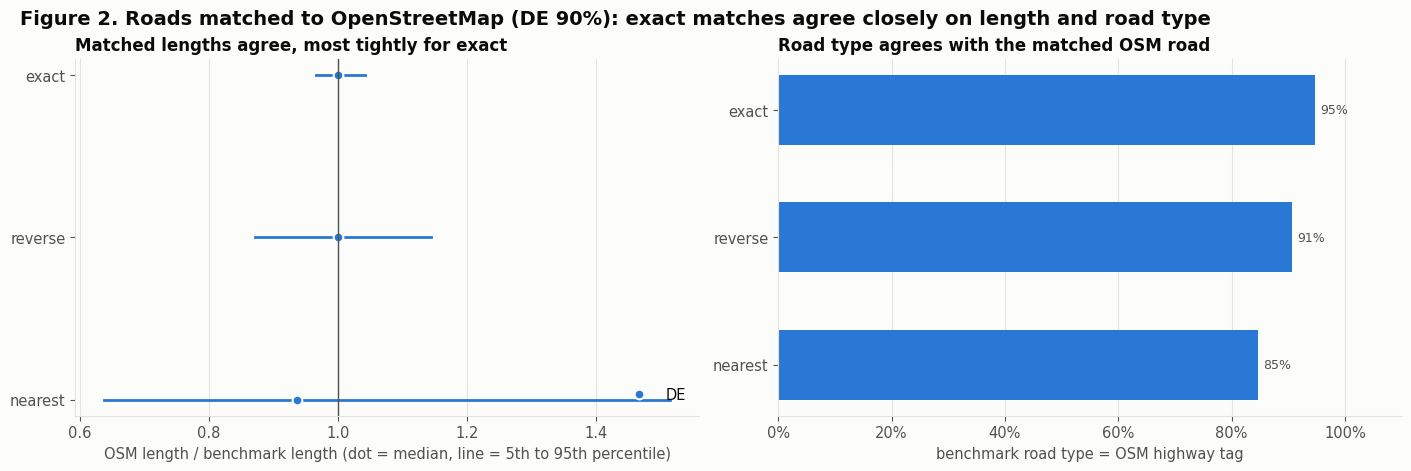

#### DE

Road match: exact 85.1%, reverse 0.5%, nearest 4.0%, unmatched 10.4%.

Node match: id 87.9%, none 9.0%, snap 3.1%; 88.8% of the dataset's node ids still exist in OSM (the OSM file is newer than the dataset); median distance to the nearest OSM node 0.0 m.

Network size: OSM has 53,248 nodes and 128,286 directed roads against the dataset's 49,023 and 116,196 (ratios 1.09 and 1.10).

Road type agrees with the matched OSM road for exact 94.6%, reverse 90.6%, nearest 84.6%.

Length ratio (OSM / dataset) by tier:

|  | roads | p05 | median | p95 | share_0.8_to_1.25 |
|---|---|---|---|---|---|
| exact | 98,855 | 0.966 | 1 | 1.04 | 0.987 |
| reverse | 584 | 0.872 | 1 | 1.15 | 0.932 |
| nearest | 4,636 | 0.637 | 0.937 | 1.52 | 0.489 |

Overall match rate if the nearest-road thresholds changed (current setting = 30 m and ratio 0.6-1.6; the loosest setting adds 5.1% at most)

| max distance (m) | 0.8-1.25 | 0.7-1.4 | 0.6-1.6 | 0.5-2 |
|---|---|---|---|---|
| 10 | 87.0% | 87.8% | 88.6% | 89.7% |
| 20 | 87.3% | 88.2% | 89.1% | 90.4% |
| 30 | 87.5% | 88.6% | 89.6% | 91.0% |
| 50 | 87.8% | 89.0% | 90.1% | 91.7% |
| 75 | 88.0% | 89.3% | 90.4% | 92.1% |

Most common road-type disagreements in the nearest tier (dataset type, OSM type, roads):

| dataset | osm | roads |
|---|---|---|
| primary | trunk | 145 |
| residential | tertiary | 110 |
| trunk | primary | 88 |
| secondary | primary | 62 |
| tertiary | secondary | 54 |
| unclassified | tertiary | 36 |

In [30]:
agreement, wrong_pairs = {}, {}
for state in STATES:
    agreement[state], wrong_pairs[state] = road_type_agreement(results[state])
plot_matching_quality(results, agreement)

for state in STATES:
    diagnostics, roads = results[state]["diagnostics"], results[state]["roads"]
    lines = [f"#### {state}"]
    lines.append("Road match: " + ", ".join(f"{tier} {format_percent(roads['match_type'].eq(tier).mean())}" for tier in MATCH_TIERS) + ".")
    if diagnostics:
        lines.append(f"Node match: " + ", ".join(f"{k} {format_percent(v)}" for k, v in diagnostics["node_match_share"].items()) +
                     f"; {format_percent(diagnostics['dataset_node_id_found_in_osm'])} of the dataset's node ids still exist in OSM "
                     f"(the OSM file is newer than the dataset); median distance to the nearest OSM node {diagnostics['nearest_node_distance_m'].get('p50', float('nan')):.1f} m.")
        sizes = diagnostics["osm_sizes"]
        lines.append(f"Network size: OSM has {sizes['osm_nodes']:,} nodes and {sizes['osm_roads']:,} directed roads against the dataset's {sizes['dataset_nodes']:,} and {sizes['dataset_roads']:,} "
                     f"(ratios {sizes['node_ratio']:.2f} and {sizes['road_ratio']:.2f}).")
    if agreement[state] is not None:
        lines.append("Road type agrees with the matched OSM road for " + ", ".join(f"{tier} {format_percent(agreement[state].loc[tier, 'agree'])}" for tier in MATCH_TIERS[:3]
                     if tier in agreement[state].index and pd.notna(agreement[state].loc[tier, 'agree'])) + ".")
    show_markdown("\n\n".join(lines))
    show_markdown("Length ratio (OSM / dataset) by tier:\n\n" + table_to_markdown(length_ratio_by_tier(roads).round(3)))
    sensitivity = threshold_sensitivity(roads)
    if sensitivity is not None:
        current = sensitivity.loc[ROAD_NEAREST_MAX_M, f"{ROAD_LEN_RATIO_RANGE[0]:g}-{ROAD_LEN_RATIO_RANGE[1]:g}"] if (ROAD_NEAREST_MAX_M in sensitivity.index and f"{ROAD_LEN_RATIO_RANGE[0]:g}-{ROAD_LEN_RATIO_RANGE[1]:g}" in sensitivity.columns) else np.nan
        observed = 1 - roads["match_type"].eq("unmatched").mean()
        note = "" if not np.isfinite(current) or abs(current - observed) < 1e-9 else "  **Warning:** the current config differs from the thresholds this file was built with."
        show_markdown(f"Overall match rate if the nearest-road thresholds changed (current setting = {ROAD_NEAREST_MAX_M} m and ratio {ROAD_LEN_RATIO_RANGE[0]:g}-{ROAD_LEN_RATIO_RANGE[1]:g}; "
           f"the loosest setting adds {format_percent(sensitivity.to_numpy().max() - sensitivity.to_numpy().min())} at most){note}\n\n" + table_to_markdown(sensitivity.apply(lambda column: column.map(lambda v: f"{v:.1%}"))))
    else:
        show_markdown("Threshold sensitivity needs the new diagnostic columns (set `FORCE_REBUILD = True` once).")
    if wrong_pairs[state] is not None and len(wrong_pairs[state]):
        show_markdown("Most common road-type disagreements in the nearest tier (dataset type, OSM type, roads):\n\n" + table_to_markdown(wrong_pairs[state].set_index("dataset")))

**Traffic-control points lost by the OSM simplification, and recovered.** Simplification removes nodes that are not junctions, taking their tags with them.
This table is the evidence for the mid-block recovery in Stage 6.

In [31]:
for state in STATES:
    diagnostics = results[state]["diagnostics"]
    if diagnostics and "midblock_recovery" in diagnostics:
        table = pd.DataFrame(diagnostics["midblock_recovery"]).T
        show_markdown(f"**{state}**\n\n" + table_to_markdown(table.round(3)))
    else:
        show_markdown(f"**{state}**: recovery statistics are not in the saved metadata (older file).")

**DE**

|  | in_file | kept_as_nodes | removed_by_simplification | recovered_mid_block | share_removed | share_of_removed_recovered |
|---|---|---|---|---|---|---|
| signal | 2,099 | 1,272 | 827 | 827 | 0.394 | 1 |
| stop | 2,177 | 351 | 1,826 | 1,826 | 0.839 | 1 |
| give_way | 196 | 0 | 196 | 196 | 1 | 1 |
| crossing | 6,842 | 31 | 6,811 | 6,811 | 0.996 | 1 |
| traffic_calming | 860 | 6 | 854 | 854 | 0.993 | 1 |

## 9. Coverage: how much did we match, and how much could we fill?
Low fill is the main weakness of OSM-derived features, so we measure *where* it comes from. There are two causes: roads that did not **match**
(the tag may exist in OSM but we could not reach it) and matched roads whose OSM road **has no tag** (the information does not exist in OSM). They need different remedies.

> **What.** The matching funnel (roads and accidents at each step), fill by road type, fill weighted by accidents, a profile of the unmatched roads, and a *ceiling* on what better matching could add.
>
> **Why.** Fill averaged over all roads is dominated by residential streets, which have few tags and few accidents; a feature known on 15% of roads may be known on 45% of accidents.
> And if the ceiling is small, smarter matching would not help.
>
> **Alternative.** Treat every missing value as "no" (rejected: it turns absence of mapping into a road property).

In [32]:
COVERAGE_TAGS = {"speed limit": "road_character_maxspeed_mph", "lanes": "road_character_lanes", "surface": "road_character_surface",
                 "cycleway": "cycle_pedestrian_lighting_cycleway_any", "sidewalk": "cycle_pedestrian_lighting_sidewalk_any", "lit": "cycle_pedestrian_lighting_lit"}
MAJOR_ROAD_TYPES = ["motorway", "motorway_link", "trunk", "trunk_link", "primary", "primary_link", "secondary", "secondary_link"]


def full_window(state, info):
    """First and last usable month of a state as 'YYYY-MM' (the configured window, or every month in the accident file)."""
    if state in USABLE_MONTHS:
        return USABLE_MONTHS[state]
    months = pd.to_datetime(info["accidents"][["year", "month"]].assign(day=1))
    return months.min().strftime("%Y-%m"), months.max().strftime("%Y-%m")


def get_window(state, name, info):
    """('YYYY-MM', 'YYYY-MM') for the analysis window `name`: 'train' (SPLIT), 'test' (SPLIT) or 'full' (all usable months)."""
    return full_window(state, info) if name == "full" else SPLIT[state][name]


def coverage_frame(result, totals):
    """One row per directed road: road type, matched flag, accidents, and True/False for 'has a value' for each tag."""
    features, roads = result["road_features"], result["roads"]
    frame = pd.DataFrame({"road_type": result["highway_class"].to_numpy(), "matched": (roads["match_type"] != "unmatched").to_numpy(),
                          "accidents": totals, "length_m": roads["length_m"].to_numpy()})
    for label, column in COVERAGE_TAGS.items():
        frame[label] = features[column].notna().to_numpy()
    return frame


def overall_coverage(frame):
    """Per tag: share of all roads with a value, share of matched roads, share of accidents on roads with a value, share of major roads."""
    major = frame["road_type"].isin(MAJOR_ROAD_TYPES)
    rows = {}
    for label in COVERAGE_TAGS:
        rows[label] = {"all roads": frame[label].mean(), "matched roads": frame.loc[frame["matched"], label].mean(),
                       "weighted by accidents": (frame[label] * frame["accidents"]).sum() / frame["accidents"].sum(),
                       "major roads": frame.loc[major, label].mean()}
    return pd.DataFrame(rows).T


def coverage_by_class(frame, top=8):
    """For the `top` road types by accidents: share of roads, share of accidents, match rate, and fill of each tag (share of ALL roads of that type)."""
    grouped = frame.groupby("road_type")
    table = pd.DataFrame({"share_of_roads": grouped.size() / len(frame),
                          "share_of_accidents": grouped["accidents"].sum() / frame["accidents"].sum(),
                          "match_rate": grouped["matched"].mean()})
    for label in COVERAGE_TAGS:
        table[label] = grouped[label].mean()
    return table.sort_values("share_of_accidents", ascending=False).head(top)


def unmatched_profile(frame):
    """What the unmatched roads are, and the ceiling on what matching them could add to each tag's fill.

    Returns (summary dict, by-type table, ceiling table). The ceiling assumes every unmatched road could be matched AND would then have the
    same tag rate as matched roads of its own type: an optimistic upper bound.
    """
    unmatched = ~frame["matched"]
    summary = {"share_of_roads": float(unmatched.mean()), "share_of_km": float(frame.loc[unmatched, "length_m"].sum() / frame["length_m"].sum()),
               "share_of_accidents": float(frame.loc[unmatched, "accidents"].sum() / frame["accidents"].sum()),
               "median_length_m_unmatched": float(frame.loc[unmatched, "length_m"].median()), "median_length_m_matched": float(frame.loc[~unmatched, "length_m"].median())}
    grouped = frame.groupby("road_type")
    by_type = pd.DataFrame({"roads": grouped.size(), "unmatched_share": 1 - grouped["matched"].mean(),
                            "accidents_per_road_unmatched": frame[unmatched].groupby("road_type")["accidents"].mean(),
                            "accidents_per_road_matched": frame[~unmatched].groupby("road_type")["accidents"].mean()})
    by_type = by_type.sort_values("roads", ascending=False).head(8)
    ceiling = {}
    for label in COVERAGE_TAGS:
        matched_fill = frame[frame["matched"]].groupby("road_type")[label].mean()
        n_unmatched = frame[unmatched].groupby("road_type").size()
        acc_unmatched = frame[unmatched].groupby("road_type")["accidents"].sum()
        gain_roads = (n_unmatched * matched_fill.reindex(n_unmatched.index).fillna(0)).sum() / len(frame)
        gain_accidents = (acc_unmatched * matched_fill.reindex(acc_unmatched.index).fillna(0)).sum() / frame["accidents"].sum()
        ceiling[label] = {"fill now (roads)": frame[label].mean(), "most extra from matching (points of roads)": gain_roads,
                          "fill now (accidents)": (frame[label] * frame["accidents"]).sum() / frame["accidents"].sum(),
                          "most extra from matching (points of accidents)": gain_accidents}
    return summary, by_type, pd.DataFrame(ceiling).T


def fill_by_group(result):
    """For each feature group: number of columns and the lowest / median / highest fill among ALL roads."""
    features = result["road_features"].drop(columns=["node_1_idx", "node_2_idx"])
    fill = features.notna().mean()
    rows = {}
    for group in [g for g in FEATURE_GROUP_PREFIXES if any(c.startswith(g + "_") for c in features.columns)]:
        values = fill[[c for c in features.columns if c.startswith(group + "_")]]
        rows[group] = {"columns": len(values), "lowest": values.min(), "median": values.median(), "highest": values.max()}
    table = pd.DataFrame(rows).T
    table.insert(0, "what", [FEATURE_GROUP_NAMES[g] for g in table.index])
    return table


FEATURE_GROUP_NAMES = {"road_character": "road character (OSM tags)", "intersection_control": "intersection control", "cycle_pedestrian_lighting": "cycle, pedestrian and lighting tags",
                       "nearby_places": "nearby places", "road_shape": "road shape (curviness)"}


def plot_coverage(frames, by_class, overall):
    """Figure 3: tag fill by road type (one heatmap per state) and fill by roads vs by accidents."""
    apply_chart_style()
    states = list(frames)
    fig = plt.figure(figsize=(6.2 * len(states) + 5, 6.4), layout="constrained")
    grid = fig.add_gridspec(1, len(states) + 1, width_ratios=[1] * len(states) + [0.85])
    labels = list(COVERAGE_TAGS)
    shared = [t for t in by_class[states[0]].index if all(t in by_class[s].index for s in states)]   # road types shown in every state, most accidents first
    common_order = shared if shared else list(by_class[states[0]].index)   # same row order in every heatmap
    for column, state in enumerate(states):
        ax = fig.add_subplot(grid[0, column])
        table = by_class[state][labels].reindex(common_order).fillna(0)
        shown = pd.concat([table, pd.DataFrame([[frames[state][label].mean() for label in labels]], index=["all roads"], columns=labels)])
        ax.imshow(shown.to_numpy(), cmap=SEQ_CMAP, vmin=0, vmax=1, aspect="auto")
        for i in range(shown.shape[0]):
            for j in range(shown.shape[1]):
                value = shown.iloc[i, j]
                ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=9.5, color=SURFACE if value > 0.5 else INK)
        ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=30, ha="right")
        ax.set_yticks(range(shown.shape[0])); ax.set_yticklabels(shown.index)
        ax.spines[:].set_visible(False); ax.tick_params(length=0)
        ax.set_title(f"{state}: share of roads with a value, by road type")
    ax = fig.add_subplot(grid[0, len(states)])
    positions = np.arange(len(labels))
    for offset, state in zip((-0.2, 0.2), states):
        ax.barh(positions + offset, overall[state]["all roads"].reindex(labels), height=0.34, color=STATE_COLORS[state], alpha=0.45, label=f"{state}: roads")
        ax.barh(positions + offset, overall[state]["weighted by accidents"].reindex(labels), height=0.14, color=STATE_COLORS[state], label=f"{state}: accidents")
    ax.set_yticks(positions); ax.set_yticklabels(labels); ax.invert_yaxis()
    ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.xaxis.grid(True)
    ax.set_title("Known on roads (wide) vs on accidents (thin)")
    ax.legend(fontsize=8.5, loc="lower right", ncol=1)
    headline = " | ".join("{}: speed limit on {:.0%} of roads but {:.0%} of accidents".format(s, overall[s].loc["speed limit", "all roads"],
                                                                                         overall[s].loc["speed limit", "weighted by accidents"]) for s in states)
    fig.suptitle("Figure 3. Tag coverage is low and uneven, but better where accidents are\n" + headline, x=0.01, ha="left", fontsize=12.5)
    save_figure(fig, "fig3_coverage")
    plt.show()


def matching_funnel(result, totals):
    """How many benchmark roads (and how many accidents) reach each step: matched, by tier, and with each tag.

    Accidents are counted on the direction where they are recorded, over the full usable period.
    Returns a table with one row per step: roads, share of roads, share of accidents.
    """
    roads, features = result["roads"], result["road_features"]
    match_type = roads["match_type"].to_numpy()
    total_accidents = max(totals.sum(), 1)
    steps = [("All benchmark roads (directed)", np.ones(len(roads), dtype=bool)),
             ("Matched to an OSM road (any tier)", match_type != "unmatched"),
             ("   exact", match_type == "exact"), ("   reverse", match_type == "reverse"), ("   nearest (the weaker tier)", match_type == "nearest"),
             ("Not matched", match_type == "unmatched")]
    for label, column in COVERAGE_TAGS.items():
        steps.append((f"Matched and has a {label} tag", features[column].notna().to_numpy()))
    place_columns = [c for c in features.columns if c.startswith("nearby_places_")]
    steps.append(("Has nearby-place features (no match needed)", features[place_columns].notna().all(axis=1).to_numpy()))
    steps.append(("Has a curviness value (no match needed)", features["road_shape_sinuosity"].notna().to_numpy()))
    return pd.DataFrame([{"step": label, "roads": int(mask.sum()), "share of roads": mask.mean(), "share of accidents": totals[mask].sum() / total_accidents}
                         for label, mask in steps]).set_index("step")

In [33]:
coverage = {}
for state in STATES:
    first, last = full_window(state, data[state])
    totals, years = accident_totals_in_period(data[state], results[state]["roads"], first, last)
    frame = coverage_frame(results[state], totals)
    summary, unmatched_by_type, ceiling = unmatched_profile(frame)
    coverage[state] = {"frame": frame, "overall": overall_coverage(frame), "by_class": coverage_by_class(frame),
                       "unmatched_summary": summary, "unmatched_by_type": unmatched_by_type, "ceiling": ceiling, "groups": fill_by_group(results[state])}

    coverage[state]["funnel"] = matching_funnel(results[state], totals)

### 9.1 The matching funnel
How many roads (and accidents) survive each step. The last line says whether better matching could change the picture.

In [34]:
for state in STATES:
    state_coverage = coverage[state]
    ceiling = state_coverage["ceiling"].loc["speed limit", "most extra from matching (points of roads)"]
    show_markdown(f"#### {state}\n\n" + table_to_markdown(state_coverage["funnel"].round(3)) +
                  f"\n\nMatching every unmatched road would add at most **{100 * ceiling:.1f} points** to speed-limit coverage (optimistic ceiling, Stage 9.3): "
                  "the gap is tags that were never mapped in OSM, not our matching.")

#### DE

| step | roads | share of roads | share of accidents |
|---|---|---|---|
| All benchmark roads (directed) | 116,196 | 1 | 1 |
| Matched to an OSM road (any tier) | 104,075 | 0.896 | 0.843 |
|    exact | 98,855 | 0.851 | 0.689 |
|    reverse | 584 | 0.005 | 0.004 |
|    nearest (the weaker tier) | 4,636 | 0.04 | 0.149 |
| Not matched | 12,121 | 0.104 | 0.157 |
| Matched and has a speed limit tag | 16,133 | 0.139 | 0.438 |
| Matched and has a lanes tag | 14,657 | 0.126 | 0.498 |
| Matched and has a surface tag | 20,155 | 0.173 | 0.268 |
| Matched and has a cycleway tag | 2,773 | 0.024 | 0.09 |
| Matched and has a sidewalk tag | 1,708 | 0.015 | 0.023 |
| Matched and has a lit tag | 710 | 0.006 | 0.014 |
| Has nearby-place features (no match needed) | 116,196 | 1 | 1 |
| Has a curviness value (no match needed) | 115,556 | 0.994 | 1 |

Matching every unmatched road would add at most **2.0 points** to speed-limit coverage (optimistic ceiling, Stage 9.3): the gap is tags that were never mapped in OSM, not our matching.

### 9.2 Figure 3: where the tags are

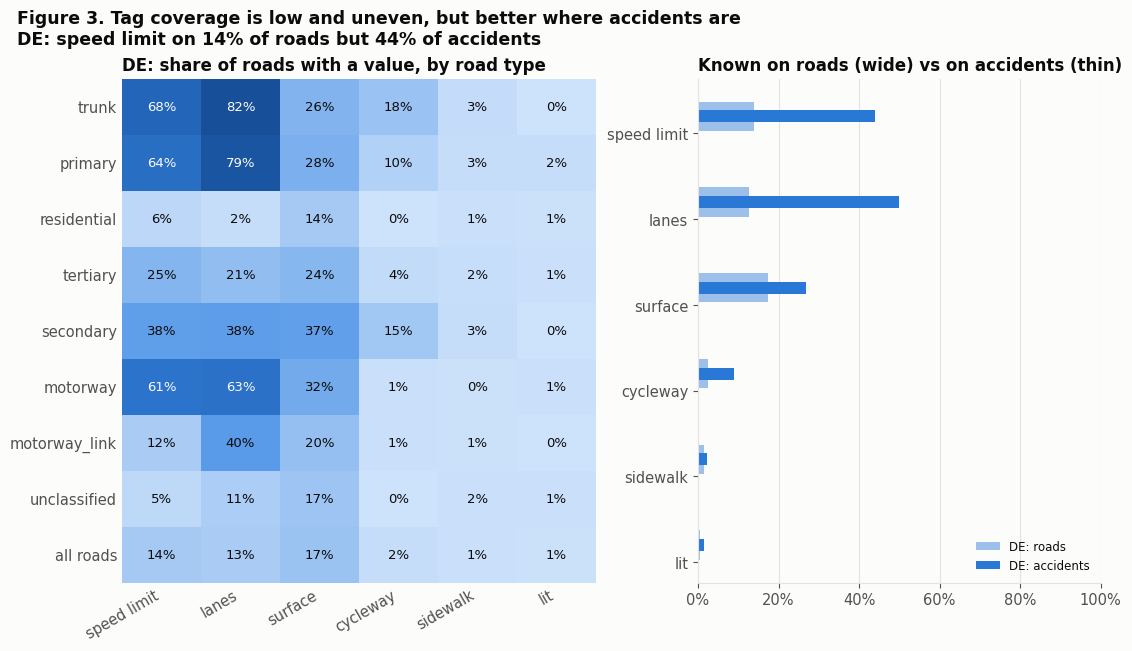

#### DE

**Share with a value** (unmatched roads count as missing)

|  | all roads | matched roads | weighted by accidents | major roads |
|---|---|---|---|---|
| speed limit | 0.139 | 0.155 | 0.438 | 0.472 |
| lanes | 0.126 | 0.141 | 0.498 | 0.578 |
| surface | 0.173 | 0.194 | 0.268 | 0.298 |
| cycleway | 0.024 | 0.027 | 0.09 | 0.122 |
| sidewalk | 0.015 | 0.016 | 0.023 | 0.026 |
| lit | 0.006 | 0.007 | 0.014 | 0.009 |

**By feature group** (fill among all roads; intersection_control flags are capped by the match rate because unmatched roads have no node tags)

|  | what | columns | lowest | median | highest |
|---|---|---|---|---|---|
| road_character | road character (OSM tags) | 5 | 0.126 | 0.173 | 0.896 |
| intersection_control | intersection control | 14 | 0.896 | 0.896 | 0.896 |
| cycle_pedestrian_lighting | cycle, pedestrian and lighting tags | 3 | 0.006 | 0.015 | 0.024 |
| nearby_places | nearby places | 35 | 1 | 1 | 1 |
| road_shape | road shape (curviness) | 1 | 0.994 | 0.994 | 0.994 |

In [35]:
plot_coverage({s: coverage[s]["frame"] for s in STATES}, {s: coverage[s]["by_class"] for s in STATES}, {s: coverage[s]["overall"] for s in STATES})
for state in STATES:
    state_coverage = coverage[state]
    show_markdown(f"#### {state}\n\n**Share with a value** (unmatched roads count as missing)\n\n" + table_to_markdown(state_coverage["overall"].round(3)))
    show_markdown("**By feature group** (fill among all roads; intersection_control flags are capped by the match rate because unmatched roads have no node tags)\n\n"
                  + table_to_markdown(state_coverage["groups"].round(3)))

### 9.3 Is it worth matching more roads? The ceiling
If the ceiling is a few points, unmatched roads are not why fill is low. The remaining gap is tags that were never mapped, and only estimation or another data source can fill it.

In [36]:
for state in STATES:
    state_coverage = coverage[state]
    unmatched_summary = state_coverage["unmatched_summary"]
    show_markdown(f"#### {state}: unmatched roads\n\n"
       f"{format_percent(unmatched_summary['share_of_roads'])} of directed roads are unmatched, covering {format_percent(unmatched_summary['share_of_km'])} of road length and carrying {format_percent(unmatched_summary['share_of_accidents'])} of accidents. "
       f"Their median length is {unmatched_summary['median_length_m_unmatched']:.0f} m against {unmatched_summary['median_length_m_matched']:.0f} m for matched roads.\n\n"
       "By road type (top 8 by roads):\n\n" + table_to_markdown(state_coverage["unmatched_by_type"].round(3)) +
       "\n\n**Ceiling on what better matching could add** (optimistic: assumes every unmatched road could be matched, with tag rates like matched roads of its own type):\n\n" +
       table_to_markdown(state_coverage["ceiling"].round(3)))
ceiling_speed = {s: coverage[s]["ceiling"].loc["speed limit", "most extra from matching (points of roads)"] for s in STATES}
show_markdown("**Reading.** " + "; ".join("{}: matching every unmatched road could add at most {:.1f} points to speed-limit fill".format(s, 100 * ceiling_speed[s]) for s in STATES) +
   ". We therefore did **not** pursue geometry-based re-matching. Two honest exceptions: a re-match would also help intersection_control (node flags), whose fill is capped by the match rate, "
   "and the nearest-road thresholds in Stage 8 show how much a looser rule would add (and risk).")

#### DE: unmatched roads

10.4% of directed roads are unmatched, covering 14.1% of road length and carrying 15.7% of accidents. Their median length is 122 m against 112 m for matched roads.

By road type (top 8 by roads):

| road_type | roads | unmatched_share | accidents_per_road_unmatched | accidents_per_road_matched |
|---|---|---|---|---|
| residential | 83,787 | 0.088 | 1.05 | 1.05 |
| tertiary | 12,698 | 0.126 | 6.09 | 5.49 |
| secondary | 6,390 | 0.142 | 7.78 | 9.5 |
| primary | 4,573 | 0.098 | 20 | 19.7 |
| trunk | 3,214 | 0.174 | 33.1 | 27.6 |
| unclassified | 2,811 | 0.273 | 2.78 | 3.2 |
| trunk_link | 953 | 0.169 | 3.53 | 4.13 |
| primary_link | 472 | 0.114 | 3.83 | 2.88 |

**Ceiling on what better matching could add** (optimistic: assumes every unmatched road could be matched, with tag rates like matched roads of its own type):

|  | fill now (roads) | most extra from matching (points of roads) | fill now (accidents) | most extra from matching (points of accidents) |
|---|---|---|---|---|
| speed limit | 0.139 | 0.02 | 0.438 | 0.091 |
| lanes | 0.126 | 0.02 | 0.498 | 0.104 |
| surface | 0.173 | 0.022 | 0.268 | 0.052 |
| cycleway | 0.024 | 0.004 | 0.09 | 0.015 |
| sidewalk | 0.015 | 0.002 | 0.023 | 0.004 |
| lit | 0.006 | 0.001 | 0.014 | 0.001 |

**Reading.** DE: matching every unmatched road could add at most 2.0 points to speed-limit fill. We therefore did **not** pursue geometry-based re-matching. Two honest exceptions: a re-match would also help intersection_control (node flags), whose fill is capped by the match rate, and the nearest-road thresholds in Stage 8 show how much a looser rule would add (and risk).

## 10. Fill gaps in speed limit, lanes and surface (validated estimates)
> **What.** For roads whose OSM road has no tag for speed limit, lanes or surface (or that did not match), we estimate the missing value from two things that need **no accident data**:
> (1) **neighbours**: the typical known value on roads of the *same road type that touch this road* (one hop, then two hops through already-estimated roads);
> (2) **road type**: the typical known value for that road type in the state. If neither exists, the state-wide typical value.
> Speed limits are snapped to the nearest 5 mph and lanes to whole numbers. The original column is never overwritten; a separate `*_filled` column and an `*_is_est` flag are added.
>
> **Why.** These three tags are known on a minority of roads but plausibly matter. A road's speed limit is usually the same as the road it continues from,
> and a residential street is almost always 25 mph, so a simple, explainable rule can recover much of what is missing.
>
> **Evidence (the gate that decides whether to keep it).** *Masked cross-validation*: hide a fifth of the **known** values (stratified by road type), fill them using only the rest, and compare with the truth.
> A method is **kept** only if it beats the state-wide value by at least `IMPUTE_MIN_GAIN` (5 points) and reaches `IMPUTE_MIN_ACCURACY` (60%; a speed estimate counts as correct within 5 mph),
> both on the hidden values and as the **expected accuracy on the roads that are really missing** (tagged roads are mostly major roads, so validation alone can flatter the method).
>
> **Alternatives considered.** A learned model on geometry and place counts (harder to explain, risks accident-correlated signals); filling from accident counts (leaks the label, rejected);
> other data sources (state DOT speed-zone files, street imagery; see future work in Stage 14); not filling at all (what happens to any feature that fails the gate).
>
> **Limits.** Validation can only use roads that **have** a tag; hiding values at random makes neighbours easier to find than in real gaps; an estimate describes the road as OSM shows it today.
> Estimates are never used in the analysis (Stage 12); they exist for the model hand-off, and the reported model uses the raw values only.

In [37]:
from scipy import sparse

SPEED_STEP_MPH = 5


def physical_attribute_table(roads, road_features, highway_class):
    """One row per PHYSICAL road (both directions merged) with the road type and the raw values of the features to fill."""
    frame = pd.DataFrame({"road_u": roads["road_u"].to_numpy(), "road_v": roads["road_v"].to_numpy(),
                          "road_type": base_road_type(highway_class).to_numpy()})
    for column in IMPUTE_FEATURES:
        frame[column] = road_features[column].to_numpy()
    return frame.groupby(["road_u", "road_v"]).first()   # first() skips missing values: if either direction has a value, it is used


def neighbour_matrix(road_u, road_v, class_codes):
    """Sparse matrix neighbour_weights: neighbour_weights[i, j] > 0 when physical roads i and j share a node AND have the same road type (diagonal removed)."""
    n = len(road_u)
    n_classes = int(class_codes.max()) + 1
    columns = np.concatenate([road_u.astype(np.int64) * n_classes + class_codes, road_v.astype(np.int64) * n_classes + class_codes])
    codes, _ = pd.factorize(columns)
    rows = np.concatenate([np.arange(n), np.arange(n)])
    incidence = sparse.csr_matrix((np.ones(len(rows)), (rows, codes)), shape=(n, codes.max() + 1))
    neighbour_weights = (incidence @ incidence.T).tocsr()
    neighbour_weights.setdiag(0)
    neighbour_weights.eliminate_zeros()
    return neighbour_weights


def snap_estimate(kind, values):
    """Round an estimate to what the tag can look like: speed to the nearest 5 mph, lanes to a whole number >= 1."""
    if kind == "speed":
        return np.clip(np.round(values / SPEED_STEP_MPH) * SPEED_STEP_MPH, SPEED_STEP_MPH, 85)
    if kind == "lanes":
        return np.clip(np.round(values), 1, 12)
    return values


def neighbour_estimate(kind, values, known, neighbour_weights, n_categories=0):
    """For every road: the typical value among its same-type touching neighbours that have a known value (NaN if none).

    Numbers: the mean of the neighbours' values, snapped. Surface: the most common neighbour category.
    `values` are floats (category codes for surface), `known` says which entries may be used as sources.
    """
    if kind == "surface":
        counts = np.column_stack([neighbour_weights @ ((values == c) & known).astype(float) for c in range(n_categories)])
        best = counts.argmax(axis=1).astype(float)
        best[counts.sum(axis=1) == 0] = np.nan
        return best
    total = neighbour_weights @ np.where(known, values, 0.0)
    weight = neighbour_weights @ known.astype(float)
    with np.errstate(invalid="ignore", divide="ignore"):
        estimate = np.where(weight > 0, total / weight, np.nan)
    return snap_estimate(kind, estimate)


def typical_value(kind, values, known, class_codes, n_categories=0):
    """The state-wide typical value and the typical value of each road type (NaN-free: types with no known value get the state-wide one).

    Returns (state_value, array with one typical value per road).
    """
    if kind == "surface":
        state_value = float(np.bincount(values[known].astype(int), minlength=n_categories).argmax())
        table = pd.crosstab(class_codes[known], values[known].astype(int))
        per_class = pd.Series(table.columns[table.to_numpy().argmax(axis=1)].to_numpy().astype(float), index=table.index) if len(table) else pd.Series(dtype=float)
    else:
        state_value = float(snap_estimate(kind, np.median(values[known])))
        per_class = pd.Series(values[known]).groupby(class_codes[known]).median()
        per_class = pd.Series(snap_estimate(kind, per_class.to_numpy()), index=per_class.index)
    return state_value, per_class.reindex(class_codes).fillna(state_value).to_numpy()


def fill_strategies(kind, values, known, class_codes, neighbour_weights, n_categories=0):
    """All three filling methods at once, using only entries marked `known` as information.

    Returns a dict with arrays over all roads: `state` (state-wide value), `type` (road type value), `full` (neighbours then road type),
    and `source` for `full`: 1 = one-hop neighbours, 2 = two-hop, 3 = road type, 4 = state-wide value.
    """
    state_value, type_values = typical_value(kind, values, known, class_codes, n_categories)
    first = neighbour_estimate(kind, values, known, neighbour_weights, n_categories)
    got_first = np.isfinite(first) & ~known
    values_2 = np.where(known, values, np.where(got_first, first, np.nan))
    second = neighbour_estimate(kind, np.nan_to_num(values_2, nan=-1.0), np.isfinite(values_2), neighbour_weights, n_categories)
    got_second = np.isfinite(second) & ~known & ~got_first

    full = type_values.copy()
    source = np.where(np.isin(class_codes, class_codes[known]), 3, 4)
    full[got_second], source[got_second] = second[got_second], 2
    full[got_first], source[got_first] = first[got_first], 1
    return {"state": np.full(len(values), state_value), "type": type_values, "full": full, "source": source}


def encode_feature(series, kind):
    """(values as floats with NaN for missing, category names or None). Surface text becomes category codes 0, 1, 2, ..."""
    if kind == "surface":
        categories = sorted(series.dropna().unique())
        lookup = {name: code for code, name in enumerate(categories)}
        return series.map(lookup).astype(float).to_numpy(), categories
    return series.astype(float).to_numpy(), None


def is_correct(kind, predicted, truth):
    """True where an estimate counts as right: speed within SPEED_TOLERANCE_MPH, lanes and surface exactly."""
    if kind == "speed":
        return np.abs(predicted - truth) <= SPEED_TOLERANCE_MPH
    return predicted == truth


def masked_cross_validation(kind, values, class_codes, neighbour_weights, n_categories, folds, seed):
    """Hide each known value once (stratified by road type), fill it without that value, and keep both for scoring.

    Returns a DataFrame with one row per known road: road type code, the truth, the three estimates and the source of the `full` one.
    """
    known = np.isfinite(values)
    known_index = np.flatnonzero(known)
    rng = np.random.default_rng(seed)
    order = rng.permutation(known_index)
    rank_in_type = pd.Series(np.arange(len(order))).groupby(class_codes[order]).cumcount().to_numpy()
    fold = np.full(len(values), -1)
    fold[order] = rank_in_type % folds
    parts = []
    for k in range(folds):
        hidden = fold == k
        visible = known & ~hidden
        result = fill_strategies(kind, np.where(visible, values, np.nan), visible, class_codes, neighbour_weights, n_categories)
        parts.append(pd.DataFrame({"type_code": class_codes[hidden], "truth": values[hidden], "state": result["state"][hidden],
                                   "type": result["type"][hidden], "full": result["full"][hidden], "source": result["source"][hidden]}))
    return pd.concat(parts, ignore_index=True)


METHOD_LABELS = {"state": "state-wide typical value", "type": "road type", "full": "neighbours + road type"}


def score_validation(kind, records):
    """Accuracy (and mean absolute error for numbers) of each method on the hidden values; accuracy of `full` by where its estimate came from."""
    scores = {}
    for method in METHOD_LABELS:
        correct = is_correct(kind, records[method].to_numpy(), records["truth"].to_numpy())
        scores[method] = {"accuracy": float(correct.mean())}
        if kind != "surface":
            scores[method]["mean_abs_error"] = float(np.abs(records[method] - records["truth"]).mean())
    by_source = records.assign(correct=is_correct(kind, records["full"].to_numpy(), records["truth"].to_numpy())).groupby("source").agg(
        hidden=("correct", "size"), accuracy=("correct", "mean"))
    return pd.DataFrame(scores).T, by_source


def decide_method(scores):
    """The gate. Returns (method to use: 'full', 'type' or 'none', plain-language reason)."""
    baseline = scores.loc["state", "accuracy"]
    passing = {m: scores.loc[m, "accuracy"] for m in ("type", "full")
               if scores.loc[m, "accuracy"] - baseline >= IMPUTE_MIN_GAIN and scores.loc[m, "accuracy"] >= IMPUTE_MIN_ACCURACY}
    if not passing:
        best = max(scores.loc[m, "accuracy"] for m in ("type", "full"))
        return "none", f"best method reaches {best:.0%}; needs +{IMPUTE_MIN_GAIN:.0%} over the state-wide value ({baseline:.0%}) and at least {IMPUTE_MIN_ACCURACY:.0%}"
    if "full" in passing and passing["full"] >= passing.get("type", 0) + IMPUTE_NEIGHBOUR_EXTRA:
        return "full", f"neighbours + road type reaches {passing['full']:.0%} against {baseline:.0%} for the state-wide value"
    method = max(passing, key=passing.get)
    return method, f"{METHOD_LABELS[method]} reaches {passing[method]:.0%} against {baseline:.0%} for the state-wide value"


def validation_by_road_type(kind, records, type_names):
    """Hidden-value accuracy of each method, by road type, with the number of hidden values."""
    table = records.assign(**{m: is_correct(kind, records[m].to_numpy(), records["truth"].to_numpy()) for m in METHOD_LABELS})
    out = table.groupby("type_code").agg(hidden=("truth", "size"), state=("state", "mean"), type=("type", "mean"), full=("full", "mean"))
    out.index = [type_names[int(c)] for c in out.index]
    return out.sort_values("hidden", ascending=False)


def fill_state(state, result, folds=IMPUTE_FOLDS, seed=RANDOM_SEED):
    """Validate and apply the gap-filling for one state.

    Returns a dict with `validation` (per feature: scores, by_source, by_type, decision, reason), `filled` (a DataFrame aligned with the
    directed roads: `<feature>_filled`, `<feature>_is_est`, `<feature>_est_source`), and `physical` (the physical-road table).
    """
    roads, features, classes = result["roads"], result["road_features"], result["highway_class"]
    physical = physical_attribute_table(roads, features, classes)
    type_names = sorted(physical["road_type"].dropna().unique())
    class_codes = physical["road_type"].map({name: code for code, name in enumerate(type_names)}).fillna(len(type_names)).astype(int).to_numpy()
    type_names = type_names + ["unknown"]
    neighbour_weights = neighbour_matrix(physical.index.get_level_values("road_u").to_numpy(), physical.index.get_level_values("road_v").to_numpy(), class_codes)

    directed_key = pd.MultiIndex.from_arrays([roads["road_u"].to_numpy(), roads["road_v"].to_numpy()])
    validation, filled = {}, pd.DataFrame(index=roads.index)
    for column, kind in IMPUTE_FEATURES.items():
        values, categories = encode_feature(physical[column], kind)
        n_categories = len(categories) if categories else 0
        known = np.isfinite(values)
        if known.sum() < 50 * IMPUTE_FOLDS:
            validation[column] = {"decision": "none", "reason": f"only {int(known.sum())} known values; too few to validate"}
            decision = "none"
            estimate = np.full(len(values), np.nan); source = np.zeros(len(values), dtype=int)
        else:
            records = masked_cross_validation(kind, values, class_codes, neighbour_weights, n_categories, folds, seed)
            scores, by_source = score_validation(kind, records)
            decision, reason = decide_method(scores)
            validation[column] = {"scores": scores, "by_source": by_source, "by_type": validation_by_road_type(kind, records, type_names),
                                  "decision": decision, "reason": reason, "kind": kind, "n_known": int(known.sum())}
            applied = fill_strategies(kind, values, known, class_codes, neighbour_weights, n_categories)
            estimate, source = applied["full" if decision == "full" else "type"], applied["source"]
            if decision == "type":
                source = np.where(known, 0, np.where(np.isin(class_codes, class_codes[known]), 3, 4))
            # mix of where the real estimates come from (decides how much to trust the overall accuracy)
            missing = ~known
            if decision != "none":
                mix = pd.Series(source[missing]).value_counts(normalize=True).sort_index()
                validation[column]["real_source_mix"] = mix
                if decision == "full":
                    accuracy_by_source = by_source["accuracy"]
                    validation[column]["expected_accuracy_on_missing"] = float(sum(mix.get(s, 0) * accuracy_by_source.get(s, np.nan) for s in mix.index if s in accuracy_by_source.index))
                else:
                    validation[column]["expected_accuracy_on_missing"] = float(scores.loc["type", "accuracy"])
                few = validation[column]["by_type"]
                small_types = set(few.index[few["hidden"] < 30])
                share_in_small = float(np.isin(class_codes[missing], [i for i, name in enumerate(type_names) if name in small_types]).mean())
                validation[column]["missing_share_in_types_with_few_validation_cases"] = share_in_small
                # Second gate: the accuracy that matters is the one on the roads that are really missing (mostly minor roads),
                # not the accuracy on the tagged roads used for validation.
                expected = validation[column]["expected_accuracy_on_missing"]
                if not expected >= IMPUTE_MIN_ACCURACY:
                    decision = "none"
                    validation[column]["decision"] = "none"
                    validation[column]["reason"] = (f"{reason}; but the expected accuracy on the roads that are really missing is {expected:.0%}, "
                                                    f"below the required {IMPUTE_MIN_ACCURACY:.0%}, so it is not filled")
        if decision == "none":
            filled_values = values.copy()
            is_est = np.zeros(len(values), dtype=bool)
            source_name = np.where(np.isfinite(values), "known", "none")
        else:
            filled_values = np.where(np.isfinite(values), values, estimate)
            is_est = ~np.isfinite(values) & np.isfinite(filled_values)
            names = np.array(["known", "neighbour", "neighbour2", "road_type", "state_value"], dtype=object)
            source_name = np.where(is_est, names[np.clip(source, 0, 4)], np.where(np.isfinite(values), "known", "none"))
        if categories:
            decoded = np.where(np.isfinite(filled_values), np.array(categories + [None], dtype=object)[np.where(np.isfinite(filled_values), filled_values, len(categories)).astype(int)], None)
            filled_values = decoded
        physical_out = pd.DataFrame({f"{column}_filled": filled_values, f"{column}_is_est": is_est.astype(float), f"{column}_est_source": source_name},
                                    index=physical.index)
        mapped = physical_out.reindex(directed_key)
        mapped.index = roads.index
        filled = pd.concat([filled, mapped], axis=1)
    return {"validation": validation, "filled": filled, "physical": physical}


def coverage_after_filling(state_fill, result, totals):
    """For each filled feature: share of directed roads (and of accidents) that are known, estimated and still missing."""
    rows = {}
    for column in IMPUTE_FEATURES:
        known = result["road_features"][column].notna().to_numpy()
        estimated = state_fill["filled"][f"{column}_is_est"].to_numpy() == 1
        for basis, weights in (("roads", np.ones(len(known))), ("accidents", totals)):
            total = weights.sum()
            rows[(column, basis)] = {"known": (weights * known).sum() / total, "estimated": (weights * estimated).sum() / total,
                                     "still missing": (weights * ~(known | estimated)).sum() / total}
    table = pd.DataFrame(rows).T
    table.index.names = ["feature", "share of"]
    return table

In [38]:
fills, fill_coverage = {}, {}
for state in STATES:
    started = time.time()
    fills[state] = fill_state(state, results[state])
    first, last = full_window(state, data[state])
    totals, _ = accident_totals_in_period(data[state], results[state]["roads"], first, last)
    fill_coverage[state] = coverage_after_filling(fills[state], results[state], totals)
    print(f"{state}: gap-filling validated and applied in {time.time() - started:.0f} s")

DE: gap-filling validated and applied in 1 s


### 10.1 Did the methods pass the gate?
Accuracy on the hidden values (higher is better). The state-wide typical value is the baseline: a method that cannot beat it adds nothing.

In [39]:
FEATURE_LABELS = {"road_character_maxspeed_mph": "speed limit", "road_character_lanes": "lanes", "road_character_surface": "surface"}


def validation_table(fills):
    """One row per state and feature: accuracy of each method on hidden values, and the gate decision."""
    rows = []
    for state, fill in fills.items():
        for column, entry in fill["validation"].items():
            row = {"state": state, "feature": FEATURE_LABELS[column], "decision": {"full": "neighbours + road type", "type": "road type only", "none": "not filled"}[entry["decision"]],
                   "reason": entry["reason"]}
            if "scores" in entry:
                row.update({"known values": entry["n_known"]})
                for method in METHOD_LABELS:
                    row[METHOD_LABELS[method]] = entry["scores"].loc[method, "accuracy"]
                if "expected_accuracy_on_missing" in entry:
                    row["expected accuracy on the missing roads"] = entry["expected_accuracy_on_missing"]
            rows.append(row)
    return pd.DataFrame(rows).set_index(["state", "feature"])


gate_table = validation_table(fills)
show_markdown("Accuracy on hidden values (speed limit: within " + str(SPEED_TOLERANCE_MPH) + " mph; lanes and surface: exact).\n\n" + table_to_markdown(gate_table.round(3)))

Accuracy on hidden values (speed limit: within 5 mph; lanes and surface: exact).

| state / feature | decision | reason | known values | state-wide typical value | road type | neighbours + road type | expected accuracy on the missing roads |
|---|---|---|---|---|---|---|---|
| DE / speed limit | neighbours + road type | neighbours + road type reaches 96% against 29% for the state-wide value | 10,482 | 0.291 | 0.644 | 0.963 | 0.635 |
| DE / lanes | not filled | neighbours + road type reaches 73% against 64% for the state-wide value; but the expected accuracy on the roads that are really missing is 55%, below the required 60%, so it is not filled | 10,526 | 0.638 | 0.638 | 0.732 | 0.55 |
| DE / surface | not filled | best method reaches 97%; needs +5% over the state-wide value (95%) and at least 60% | 11,775 | 0.949 | 0.949 | 0.971 |  |

### 10.2 Figure 4: coverage before and after, and how the methods compare

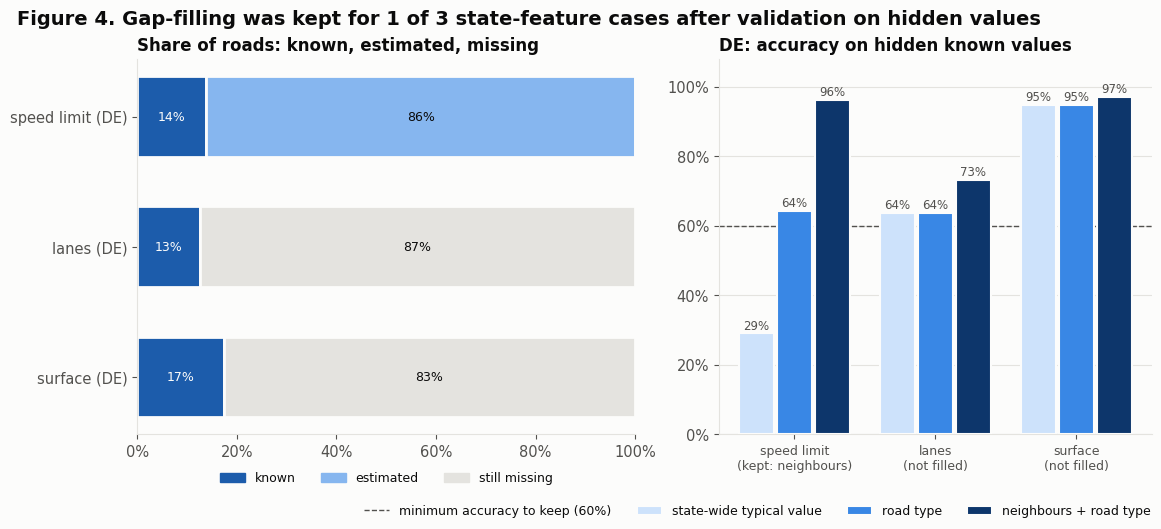

In [40]:
def plot_gap_filling(fills, fill_coverage):
    """Figure 4: known / estimated / missing shares before and after, and the accuracy of each method on hidden values."""
    apply_chart_style()
    states = list(fills)
    columns = list(IMPUTE_FEATURES)
    fig, axes = plt.subplots(1, 1 + len(states), figsize=(6 + 5.5 * len(states), 5.2), gridspec_kw={"width_ratios": [1.15] + [1] * len(states)}, layout="constrained")
    ax = axes[0]
    labels, row = [], 0
    colors = {"known": BLUE_RAMP[3], "estimated": BLUE_RAMP[1], "still missing": GRID_COLOR}
    for column in columns:
        for state in states:
            table = fill_coverage[state].loc[(column, "roads")]
            left = 0.0
            for part in ("known", "estimated", "still missing"):
                ax.barh(row, table[part], left=left, color=colors[part], height=0.62, edgecolor=SURFACE, linewidth=2)
                if table[part] > 0.06:
                    ax.text(left + table[part] / 2, row, f"{table[part]:.0%}", ha="center", va="center", fontsize=9, color=SURFACE if part == "known" else INK)
                left += table[part]
            labels.append(f"{FEATURE_LABELS[column]} ({state})")
            row += 1
    ax.set_yticks(range(row)); ax.set_yticklabels(labels); ax.invert_yaxis()
    ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=colors[p]) for p in colors], labels=list(colors), ncol=3, loc="upper center",
              bbox_to_anchor=(0.5, -0.07), fontsize=9)
    ax.set_title("Share of roads: known, estimated, missing")

    method_colors = {"state": BLUE_RAMP[0], "type": BLUE_RAMP[2], "full": BLUE_RAMP[4]}
    for ax, state in zip(axes[1:], states):
        positions = np.arange(len(columns))
        for offset, method in zip((-0.27, 0, 0.27), METHOD_LABELS):
            values = [fills[state]["validation"][c]["scores"].loc[method, "accuracy"] if "scores" in fills[state]["validation"][c] else np.nan for c in columns]
            ax.bar(positions + offset, values, width=0.25, color=method_colors[method], edgecolor=SURFACE, linewidth=1.5,
                   label=METHOD_LABELS[method], zorder=3)
            for x, v in zip(positions + offset, values):
                if np.isfinite(v):
                    ax.text(x, v + 0.012, f"{v:.0%}", ha="center", fontsize=8.5, color=INK_SECONDARY)
        ax.axhline(IMPUTE_MIN_ACCURACY, color=INK_SECONDARY, lw=1, ls="--", label="minimum accuracy to keep ({:.0%})".format(IMPUTE_MIN_ACCURACY))
        decisions = [{"full": "kept: neighbours", "type": "kept: road type", "none": "not filled"}[fills[state]["validation"][c]["decision"]] for c in columns]
        ax.set_xticks(positions); ax.set_xticklabels([f"{FEATURE_LABELS[c]}\n({d})" for c, d in zip(columns, decisions)], fontsize=9)
        ax.set_ylim(0, 1.08); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.yaxis.grid(True)
        ax.set_title(f"{state}: accuracy on hidden known values")
    handles, labels_ = axes[1].get_legend_handles_labels()
    fig.legend(handles, labels_, loc="outside lower right", ncol=4, fontsize=9)
    kept = sum(1 for s in states for c in columns if fills[s]["validation"][c]["decision"] != "none")
    fig.suptitle(f"Figure 4. Gap-filling was kept for {kept} of {len(states) * len(columns)} state-feature cases after validation on hidden values", x=0.01, ha="left")
    save_figure(fig, "fig4_gap_filling")
    plt.show()


plot_gap_filling(fills, fill_coverage)

### 10.3 Where the estimates come from, and how far to trust them
*Source* says how an estimate was made: one-hop or two-hop neighbours, road type, or the state-wide value. Neighbour estimates are usually the most reliable;
the state-wide value is a last resort. The last figure in each line warns about missing roads whose road type has too few validation cases (under 30).

In [41]:
for state in STATES:
    parts = []
    for column in IMPUTE_FEATURES:
        entry = fills[state]["validation"][column]
        if "real_source_mix" in entry and entry["decision"] != "none":
            names = {1: "neighbour", 2: "neighbour (2 hops)", 3: "road type", 4: "state-wide value"}
            mix = ", ".join(f"{names[int(s)]} {format_percent(v)}" for s, v in entry["real_source_mix"].items())
            accuracy_by_source = entry["by_source"]["accuracy"] if entry["decision"] == "full" else None
            detail = "" if accuracy_by_source is None else " Accuracy on hidden values by source: " + ", ".join(f"{names[int(s)]} {format_percent(a)}" for s, a in accuracy_by_source.items()) + "."
            parts.append(f"* **{FEATURE_LABELS[column]}**: estimates come from {mix}.{detail} "
                         f"{format_percent(entry['missing_share_in_types_with_few_validation_cases'])} of the missing roads are in road types with fewer than 30 validation cases.")
        else:
            parts.append(f"* **{FEATURE_LABELS[column]}**: not filled ({entry['reason']}).")
    show_markdown(f"#### {state}\n\n" + "\n".join(parts))
    for column in IMPUTE_FEATURES:
        entry = fills[state]["validation"][column]
        if "by_type" in entry and entry["decision"] != "none":
            show_markdown(f"Accuracy on hidden {FEATURE_LABELS[column]} values by road type ({state}):\n\n" + table_to_markdown(entry["by_type"].head(8).round(3)))

#### DE

* **speed limit**: estimates come from neighbour 7.7%, neighbour (2 hops) 3.6%, road type 88.6%, state-wide value 0.0%. Accuracy on hidden values by source: neighbour 97.7%, neighbour (2 hops) 94.9%, road type 59.2%. 0.0% of the missing roads are in road types with fewer than 30 validation cases.
* **lanes**: not filled (neighbours + road type reaches 73% against 64% for the state-wide value; but the expected accuracy on the roads that are really missing is 55%, below the required 60%, so it is not filled).
* **surface**: not filled (best method reaches 97%; needs +5% over the state-wide value (95%) and at least 60%).

Accuracy on hidden speed limit values by road type (DE):

|  | hidden | state | type | full |
|---|---|---|---|---|
| residential | 2,756 | 0.017 | 0.755 | 0.969 |
| primary | 2,275 | 0.537 | 0.537 | 0.973 |
| trunk | 2,137 | 0.316 | 0.804 | 0.975 |
| tertiary | 1,706 | 0.35 | 0.596 | 0.951 |
| secondary | 1,319 | 0.374 | 0.374 | 0.951 |
| motorway | 205 | 0.034 | 0.766 | 0.873 |
| unclassified | 84 | 0.06 | 0.702 | 0.821 |

**How the estimates are used.** The raw columns stay exactly as OSM gave them. The model-ready table (Stage 13) adds `*_filled` columns and `*_is_est` flags,
so a model can use the filled values, learn that estimated values are less certain, or ignore them. The analysis in Stage 12 uses real values only.

## 11. Assumptions register
Every choice that shapes the features, with the value used (read from the config, so it cannot drift from the code), why we made it, where this notebook checks it,
a reference where one exists, and what goes wrong if it is wrong. **L** numbers point to the limitations in Stage 14, which say what each choice costs.

References: Geofabrik extracts, https://download.geofabrik.de/north-america/us.html. Nippani et al. (2023), road-accident benchmark, [arXiv 2311.00164](https://arxiv.org/abs/2311.00164).
Boeing, G. (2017). OSMnx: New methods for acquiring, constructing, analyzing, and visualizing complex street networks. *Computers, Environment and Urban Systems* 65, 126-139.
OpenStreetMap wiki, [Key:maxspeed](https://wiki.openstreetmap.org/wiki/Key:maxspeed). MacKinnon, J. G. and White, H. (1985). Some heteroskedasticity-consistent covariance matrix
estimators with improved finite sample properties. *Journal of Econometrics* 29(3), 305-325.
Goodchild, M. F. and Hunter, G. J. (1997). A simple positional accuracy measure for linear features. *International Journal of Geographical Information Science* 11(3), 299-306.
Haklay, M. (2010). How good is volunteered geographical information? A comparative study of OpenStreetMap and Ordnance Survey datasets. *Environment and Planning B* 37(4), 682-703.

In [42]:
def build_assumptions_register():
    """The assumptions register as a table. Values come from the config; evidence cells use numbers from this run where they exist."""
    states = STATES

    def per_state(function):
        try:
            return "; ".join(f"{s}: {function(s)}" for s in states)
        except Exception:
            return "(see the stage referenced)"

    def snapshot_date(state):
        meta_path = DATA_DIR / f"{state}_osm_matching_meta.json"
        return json.load(open(meta_path)).get("osm_snapshot_date") if meta_path.exists() else "n/a"

    diagnostics = lambda s: results[s]["diagnostics"]
    def unitless(state):
        speed = diagnostics(state)["tag_cleaning"]["maxspeed"]
        if speed["unitless_read_as_mph"] == 0:
            return f"none: all {speed['tagged']:,} tagged speed limits carry an explicit unit, so the rule changes no value"
        return (f"{speed['unitless_read_as_mph']:,} OSM road pieces; {format_percent(speed['unitless_share_ending_in_5'])} end in 5 against "
                f"{format_percent(speed['explicit_mph_share_ending_in_5'])} for explicit mph")
    rows = [
        ("A1", "2.1", "One OSM snapshot stands for every accident year", f"Geofabrik extract, snapshot {per_state(snapshot_date)}",
         "A historical extract per year was out of scope; a recent snapshot is reproducible.",
         f"Benchmark node ids still in OSM: {per_state(lambda s: format_percent(diagnostics(s)['dataset_node_id_found_in_osm']))} (Stage 8).",
         "Geofabrik", "Roads, tags and signals may differ from when the accidents happened; reverse causality.", "L1, L16"),
        ("A2", "2.1", "The same road set as the benchmark", f"{len(ROAD_HIGHWAY_VALUES)} highway types", "Matching needs both sides to describe the same roads.",
         f"OSM / benchmark road count: {per_state(lambda s: format(diagnostics(s)['osm_sizes']['road_ratio'], '.2f'))} (Stage 8).", "Nippani et al. (2023)",
         "Extra or missing road types would create false or missed matches.", "L2"),
        ("A3", "5", "A stored node id counts only if the positions agree", f"within {NODE_ID_COORD_TOL_M} m", "Ids can be reused or moved between extracts.",
         f"Node match shares: {per_state(lambda s: diagnostics(s)['node_match_share'])} (Stage 8).", "-", "A moved node would attach the wrong roads.", "L2"),
        ("A4", "5", "Otherwise snap to the nearest OSM node", f"within {NODE_SNAP_MAX_M} m", "Recovers nodes whose id changed.",
         "Median distance to the nearest OSM node in Stage 8.", "-", "A wrong snap mismatches both roads at that node.", "L2"),
        ("A5", "5", "Road tiers: exact, then reverse, then nearest", f"nearest within {ROAD_NEAREST_MAX_M} m and length ratio {ROAD_LEN_RATIO_RANGE[0]}-{ROAD_LEN_RATIO_RANGE[1]}",
         "Trust node pairs first; use position only when the pair is missing, with a length check.", "Sensitivity table and road-type agreement by tier (Stage 8).", "-",
         "Nearest matches are weaker: about half have a length within 0.8-1.25x.", "L2, L14"),
        ("A6", "6", "Mid-block control points attach to the nearest road", f"within {MIDBLOCK_NODE_MAX_M} m", "osmnx's simplification removes non-junction nodes and their tags.",
         "Recovery table (Stage 8).", "Boeing (2017)", "A point near two roads may attach to the wrong one.", "L11"),
        ("A7", "4", "Both directions are one physical road", "accidents summed, features shared", "Accidents are stored on one direction only.",
         "Cleaning log: share of two-way roads with accidents on one direction only (Stage 4).", "-", "Direction-specific effects cannot be studied.", "L10"),
        ("A8", "2.2", "Roads with several types take the last type found as a label", "label for matching checks and gap-filling only",
         "Needed one label per road; the analysis leaves these roads out.", "Cleaning log: roads with more than one type (Stage 4).", "-",
         "Road-type agreement and gap-filling for those roads use an arbitrary one of their types.", "L14"),
        ("A9", "4", "A missing tag is unknown; a 0 node flag means 'not mapped'", "kept as NaN / 0 as described in the catalogue",
         "Volunteer mapping is incomplete; absence of a tag is not absence of the thing.", "Coverage (Stage 9).", "-",
         "Treating 'not mapped' as 'absent' would make mapping effort look like a road property.", "L3, L4"),
        ("A10", "1.6", "A speed limit without a unit is mph", "unit-less maxspeed read as mph",
         "US limits are posted in mph; the OSM wiki's default unit is km/h, so this departs from the OSM convention.", f"Unit-less values: {per_state(unitless)} (Stage 7.2).",
         "OSM wiki, Key:maxspeed", "If they were really km/h, those speeds would be about 1.6 times too high.", "L3"),
        ("A11", "6", "Nearby places are counted from the road's midpoint, by straight-line distance", f"radii {', '.join(str(r) for r in PLACE_RADII_M)} m",
         "Fast and gives every road a value; four radii let a model pick the scale.", "Feature catalogue (Stage 7).", "-", "Coarse for long roads; ignores barriers and network distance.", "L12"),
        ("A12", "6", "Rare surface types are pooled", f"fewer than {RARE_CATEGORY_MIN_ROADS} roads become 'other'", "Very rare categories cannot be learned or compared.",
         "Data dictionary (Stage 13).", "-", "Distinct rare surfaces are merged.", "-"),
        ("A13", "10", "Gap-filling is kept only if it passes the gate",
         f"accuracy at least {IMPUTE_MIN_ACCURACY:.0%}, at least {IMPUTE_MIN_GAIN:.0%} better than the state-wide value; speed correct within {SPEED_TOLERANCE_MPH} mph",
         "An estimate must beat the trivial guess clearly to be worth adding.", f"Gate outcome: {per_state(lambda s: ', '.join(FEATURE_LABELS[c] + ' ' + e['decision'] for c, e in fills[s]['validation'].items()))} (Stage 10).",
         "-", "Validated on tagged (mostly major) roads, so accuracy on missing residential roads is less certain.", "L5"),
        ("A14", "all", "Accidents are never used to build, fill or select a feature", "by design", "Prevents label leakage into the model.",
         "The model-ready table is checked for label-derived columns (Stage 13).", "-", "Leakage would inflate any model gain.", "-"),
        ("A15", "12", "Analysis rules", f"clear only if at least {MIN_ACCIDENTS_FOR_VERDICT} accidents, interval excludes 1, and ratio outside {1 / MIN_EFFECT_RATIO:.2f}-{MIN_EFFECT_RATIO}; HC1 intervals; roads treated as independent",
         "Guards against calling noise a finding.", "Stage 12.", "MacKinnon and White (1985)", "Neighbouring roads are correlated, so intervals are somewhat too narrow.", "L7"),
        ("A16", "4", "Partial-month detector", "below 0.5 x the median of the surrounding 12 months", "Flags months that were only partly recorded.",
         "Detector against configured exclusions (Stage 4).", "-", "A real drop could be flagged; it is kept unless configured.", "-"),
        ("A17", "6", "A road with several surfaces is 'mixed'; with several road types, the most common in the state is kept",
         "replaces v7's 'first value of the list'", "osmnx merges OSM pieces and keeps their values in a list whose order can change between runs; "
         "the first value made 139 Delaware roads change surface between two builds.",
         f"Pieces with several surfaces / road types: {per_state(lambda s: str(diagnostics(s)['tag_cleaning']['maxspeed'].get('surface_several_values_mixed', 'n/a')) + ' / ' + str(diagnostics(s)['tag_cleaning']['maxspeed'].get('highway_several_values', 'n/a')))} (Stage 7.2).",
         "Boeing (2017)", "'mixed' hides which surface covers most of the road.", "-"),
    ]
    columns = ["id", "stage", "assumption", "value used", "why", "evidence in this notebook", "reference", "if wrong", "limitation"]
    return pd.DataFrame(rows, columns=columns).set_index("id")


assumptions = build_assumptions_register()
show_markdown(table_to_markdown(assumptions))

| id | stage | assumption | value used | why | evidence in this notebook | reference | if wrong | limitation |
|---|---|---|---|---|---|---|---|---|
| A1 | 2.1 | One OSM snapshot stands for every accident year | Geofabrik extract, snapshot DE: 2026-10-18 | A historical extract per year was out of scope; a recent snapshot is reproducible. | Benchmark node ids still in OSM: DE: 88.8% (Stage 8). | Geofabrik | Roads, tags and signals may differ from when the accidents happened; reverse causality. | L1, L16 |
| A2 | 2.1 | The same road set as the benchmark | 14 highway types | Matching needs both sides to describe the same roads. | OSM / benchmark road count: DE: 1.10 (Stage 8). | Nippani et al. (2023) | Extra or missing road types would create false or missed matches. | L2 |
| A3 | 5 | A stored node id counts only if the positions agree | within 25 m | Ids can be reused or moved between extracts. | Node match shares: DE: {'id': 0.8792, 'none': 0.0898, 'snap': 0.031} (Stage 8). | - | A moved node would attach the wrong roads. | L2 |
| A4 | 5 | Otherwise snap to the nearest OSM node | within 20 m | Recovers nodes whose id changed. | Median distance to the nearest OSM node in Stage 8. | - | A wrong snap mismatches both roads at that node. | L2 |
| A5 | 5 | Road tiers: exact, then reverse, then nearest | nearest within 30 m and length ratio 0.6-1.6 | Trust node pairs first; use position only when the pair is missing, with a length check. | Sensitivity table and road-type agreement by tier (Stage 8). | - | Nearest matches are weaker: about half have a length within 0.8-1.25x. | L2, L14 |
| A6 | 6 | Mid-block control points attach to the nearest road | within 15 m | osmnx's simplification removes non-junction nodes and their tags. | Recovery table (Stage 8). | Boeing (2017) | A point near two roads may attach to the wrong one. | L11 |
| A7 | 4 | Both directions are one physical road | accidents summed, features shared | Accidents are stored on one direction only. | Cleaning log: share of two-way roads with accidents on one direction only (Stage 4). | - | Direction-specific effects cannot be studied. | L10 |
| A8 | 2.2 | Roads with several types take the last type found as a label | label for matching checks and gap-filling only | Needed one label per road; the analysis leaves these roads out. | Cleaning log: roads with more than one type (Stage 4). | - | Road-type agreement and gap-filling for those roads use an arbitrary one of their types. | L14 |
| A9 | 4 | A missing tag is unknown; a 0 node flag means 'not mapped' | kept as NaN / 0 as described in the catalogue | Volunteer mapping is incomplete; absence of a tag is not absence of the thing. | Coverage (Stage 9). | - | Treating 'not mapped' as 'absent' would make mapping effort look like a road property. | L3, L4 |
| A10 | 1.6 | A speed limit without a unit is mph | unit-less maxspeed read as mph | US limits are posted in mph; the OSM wiki's default unit is km/h, so this departs from the OSM convention. | Unit-less values: DE: none: all 19,504 tagged speed limits carry an explicit unit, so the rule changes no value (Stage 7.2). | OSM wiki, Key:maxspeed | If they were really km/h, those speeds would be about 1.6 times too high. | L3 |
| A11 | 6 | Nearby places are counted from the road's midpoint, by straight-line distance | radii 100, 250, 500, 1000 m | Fast and gives every road a value; four radii let a model pick the scale. | Feature catalogue (Stage 7). | - | Coarse for long roads; ignores barriers and network distance. | L12 |
| A12 | 6 | Rare surface types are pooled | fewer than 50 roads become 'other' | Very rare categories cannot be learned or compared. | Data dictionary (Stage 13). | - | Distinct rare surfaces are merged. | - |
| A13 | 10 | Gap-filling is kept only if it passes the gate | accuracy at least 60%, at least 5% better than the state-wide value; speed correct within 5 mph | An estimate must beat the trivial guess clearly to be worth adding. | Gate outcome: DE: speed limit full, lanes none, surface none (Stage 10). | - | Validated on tagged (mostly major) roads, so accuracy on missing residential roads is less certain. | L5 |
| A14 | all | Accidents are never used to build, fill or select a feature | by design | Prevents label leakage into the model. | The model-ready table is checked for label-derived columns (Stage 13). | - | Leakage would inflate any model gain. | - |
| A15 | 12 | Analysis rules | clear only if at least 100 accidents, interval excludes 1, and ratio outside 0.80-1.25; HC1 intervals; roads treated as independent | Guards against calling noise a finding. | Stage 12. | MacKinnon and White (1985) | Neighbouring roads are correlated, so intervals are somewhat too narrow. | L7 |
| A16 | 4 | Partial-month detector | below 0.5 x the median of the surrounding 12 months | Flags months that were only partly recorded. | Detector against configured exclusions (Stage 4). | - | A real drop could be flagged; it is kept unless configured. | - |
| A17 | 6 | A road with several surfaces is 'mixed'; with several road types, the most common in the state is kept | replaces v7's 'first value of the list' | osmnx merges OSM pieces and keeps their values in a list whose order can change between runs; the first value made 139 Delaware roads change surface between two builds. | Pieces with several surfaces / road types: DE: 251 / 163 (Stage 7.2). | Boeing (2017) | 'mixed' hides which surface covers most of the road. | - |

## 12. Analyse: do the features go with more or fewer accidents?
This stage checks that the features **carry signal**; it is not the model. Two steps: each feature on its own (12.1), then all features together with a robustness check (12.2).

> **What.** For every feature, compare accident rates **between its values**, using only roads where the value is known. The comparison is a **controlled ratio**:
> observed accidents divided by what roads of the same length band and road type usually have, so a feature does not look dangerous just because the roads that have it are long or major.
> A ratio of 1 means "as many accidents per km as comparable roads"; 1.5 means 50% more.
>
> **Rules (A15).** A level is judged only with at least `MIN_ACCIDENTS_FOR_VERDICT` accidents; it **differs** only if the robust interval excludes 1 *and* the ratio is outside 0.8 to 1.25.
> The interval uses variation between roads (`se(log ratio) = sqrt(sum (observed - ratio x expected)^2) / observed`), because accidents cluster on few roads and a plain Poisson interval would be far too narrow.
>
> **Window.** Each state's full usable period; the paper's training years are repeated as a robustness check in 12.2.
>
> **Limits.** Associations, not causes: signals, food places and parking mark busy built-up areas, and traffic volume is not used (L6). Intervals treat roads as independent (L7).
> For sparse tags, a finding describes only the roads where the tag exists, usually the better-mapped ones (L4).

### 12.1 Each feature on its own

In [43]:
def expected_accidents(levels, strata_columns, n_years):
    """How many accidents each road would have if only its stratum mattered.

    Why: a feature can look risky just because the roads that have it are long, or are major roads. To control for
    that, roads are grouped into strata (for example length band x road type). Within a stratum every road is given
    the same rate per km-year, so a road's expected accidents = stratum rate x its own km-years.

    Takes: the table from `add_analysis_levels`, the stratum columns, and the period length in years.
    Returns: an array aligned with `levels`.
    """
    km_years = levels["length_m"] / 1000 * n_years
    stratum_accidents = levels.groupby(strata_columns, observed=True, dropna=False)["accidents"].transform("sum")
    stratum_exposure = km_years.groupby([levels[c] for c in strata_columns], observed=True, dropna=False).transform("sum")
    return (stratum_accidents / stratum_exposure * km_years).to_numpy()


def rate_by_level(levels, variable, n_years):
    """Accident rate per km-year for each level of one variable, with a 95% confidence interval.

    Why: raw counts mislead because long roads collect more accidents. A rate per kilometre of road per year
    puts roads of different length on one scale.

    How: for each level, rate = accidents / (total km x years). The interval is the exact Poisson interval:
    lower = chi2.ppf(0.025, 2k) / 2 / E and upper = chi2.ppf(0.975, 2k + 2) / 2 / E, with k accidents and E km-years.

    Takes: the table from `add_analysis_levels`, the variable name, and the length of the period in years.
    Returns: one row per level: roads, accidents, km, rate, interval, and the share of roads with any accident.
    """
    grouped = levels.groupby(variable, observed=True)
    result = pd.DataFrame({
        "roads": grouped.size(),
        "accidents": grouped["accidents"].sum(),
        "km": grouped["length_m"].sum() / 1000,
        "share_roads_with_accident": grouped["accidents"].apply(lambda s: (s > 0).mean()),
    })
    exposure = result["km"] * n_years
    k = result["accidents"]
    result["rate"] = k / exposure
    result["ci_low"] = np.where(k > 0, chi2.ppf(0.025, 2 * k) / 2 / exposure, 0.0)
    result["ci_high"] = chi2.ppf(0.975, 2 * k + 2) / 2 / exposure
    return result


def build_physical_road_table(roads, road_features, highway_class, accident_total):
    """One row per PHYSICAL road: the two directions of a two-way road are merged.

    Why: the dataset stores each accident on only one direction of a two-way road (brief section 1b), so the
    other direction always shows zero. Summing both directions removes that artefact.

    How: accidents are added over both directions; length is the mean; for the features, the larger value of
    the two directions is used (OSM features are the same in both; "at the start / end" features are combined
    into "at either end").

    Takes: `roads` (after matching), `road_features`, `highway_class`, and the accident totals per directed road.
    Returns: a DataFrame indexed by (road_u, road_v) with the columns used by `add_analysis_levels`.
    """
    f = road_features
    directed = pd.DataFrame({
        "road_u": roads["road_u"].to_numpy(), "road_v": roads["road_v"].to_numpy(),
        "length_m": roads["length_m"].to_numpy(), "accidents": accident_total,
        "highway_class": highway_class.to_numpy(), "matched": (roads["osm_row"] >= 0).to_numpy(),
        # road_character
        "speed_mph": f["road_character_maxspeed_mph"].to_numpy(), "lanes": f["road_character_lanes"].to_numpy(),
        "surface": f["road_character_surface"].to_numpy(), "bridge": f["road_character_bridge"].to_numpy(),
        # intersection_control: at either end of the road, and mid-block
        "signal_at_end": np.fmax(f["intersection_control_signal_start"], f["intersection_control_signal_end"]),
        "stop_at_end": np.fmax(f["intersection_control_stop_start"], f["intersection_control_stop_end"]),
        "crossing_at_end": np.fmax(f["intersection_control_crossing_start"], f["intersection_control_crossing_end"]),
        "signal_midblock": f["intersection_control_signal_midblock"].to_numpy(), "stop_midblock": f["intersection_control_stop_midblock"].to_numpy(),
        "crossing_midblock": f["intersection_control_crossing_midblock"].to_numpy(), "calming_midblock": f["intersection_control_traffic_calming_midblock"].to_numpy(),
        "roundabout": f["intersection_control_roundabout"].to_numpy(),
        # cycle_pedestrian_lighting
        "cycleway": f["cycle_pedestrian_lighting_cycleway_any"].to_numpy(), "sidewalk": f["cycle_pedestrian_lighting_sidewalk_any"].to_numpy(), "lit": f["cycle_pedestrian_lighting_lit"].to_numpy(),
        # nearby_places
        "crossings_250m": f["nearby_places_crossing_250m"].to_numpy(), "parking_250m": f["nearby_places_parking_250m"].to_numpy(),
        "food_250m": f["nearby_places_food_250m"].to_numpy(), "signals_250m": f["nearby_places_signal_250m"].to_numpy(),
        "school_nearest_m": f["nearby_places_school_nearest_m"].to_numpy(),
        # road_shape
        "sinuosity": f["road_shape_sinuosity"].to_numpy(),
    })
    how = {column: "max" for column in directed.columns if column not in ("road_u", "road_v")}
    how.update({"length_m": "mean", "accidents": "sum", "highway_class": "first", "surface": "first"})
    return directed.groupby(["road_u", "road_v"]).agg(how)

In [44]:
# The order of levels, used for ordered variables and for plotting. Binary variables run from "no" to "yes".
LEVEL_ORDER = {
    "length": ["<50 m", "50-100 m", "100-200 m", "200-500 m", "0.5-1 km", ">1 km"],
    "speed_limit": ["<=20", "25", "30", "35", "40", "45", "50", "55+"],
    "lanes": ["1", "2", "3", "4+"],
    "signal_midblock": ["0", "1", "2+"], "stop_midblock": ["0", "1", "2+"], "crossing_midblock": ["0", "1", "2+"], "calming_midblock": ["0", "1", "2+"],
    "crossings_within_250m": ["0", "1-2", "3-5", "6+"], "parking_within_250m": ["0", "1-2", "3-5", "6+"],
    "food_within_250m": ["0", "1-2", "3-5", "6+"], "signals_within_250m": ["0", "1-2", "3-5", "6+"],
    "nearest_school": ["<250 m", "250-500 m", "0.5-1 km", ">1 km"],
    "sinuosity": ["straight", "<5% longer", "5-20% longer", ">20% longer"],
}
BINARY_VARIABLES = ["bridge", "signal_at_end", "stop_at_end", "crossing_at_end", "roundabout", "cycleway", "sidewalk", "lit"]
for _name in BINARY_VARIABLES:
    LEVEL_ORDER[_name] = ["no", "yes"]

VARIABLE_LABELS = {
    "speed_limit": "speed limit (mph)", "lanes": "lanes", "surface": "surface", "bridge": "on a bridge",
    "signal_at_end": "signal at a road end", "stop_at_end": "stop sign at a road end", "crossing_at_end": "crossing at a road end", "roundabout": "roundabout",
    "signal_midblock": "signals mid-block", "stop_midblock": "stop signs mid-block", "crossing_midblock": "crossings mid-block", "calming_midblock": "traffic calming mid-block",
    "cycleway": "cycleway tagged", "sidewalk": "sidewalk tagged", "lit": "street lighting",
    "crossings_within_250m": "crossings within 250 m", "parking_within_250m": "parking within 250 m", "food_within_250m": "food places within 250 m",
    "signals_within_250m": "signals within 250 m", "nearest_school": "distance to nearest school", "sinuosity": "curviness (length vs straight line)",
    "road_type": "road type",
}

# Which feature group each analysis variable belongs to, for the summaries.
FEATURE_GROUP_OF_VARIABLE = {
    "speed_limit": "road_character", "lanes": "road_character", "surface": "road_character", "bridge": "road_character",
    "signal_at_end": "intersection_control", "stop_at_end": "intersection_control", "crossing_at_end": "intersection_control", "roundabout": "intersection_control",
    "signal_midblock": "intersection_control", "stop_midblock": "intersection_control", "crossing_midblock": "intersection_control", "calming_midblock": "intersection_control",
    "cycleway": "cycle_pedestrian_lighting", "sidewalk": "cycle_pedestrian_lighting", "lit": "cycle_pedestrian_lighting",
    "crossings_within_250m": "nearby_places", "parking_within_250m": "nearby_places", "food_within_250m": "nearby_places",
    "signals_within_250m": "nearby_places", "nearest_school": "nearby_places",
    "sinuosity": "road_shape",
}


def add_analysis_levels(table):
    """Group each feature into a few labelled levels so rates can be compared (for example speed limit "25", "30", "35").

    Takes the table from `build_physical_road_table`. Returns a DataFrame with the same rows plus `accidents` and `length_m`, and one column per
    analysis variable. **A value that is missing (no tag, or the road did not match OSM) stays missing (NaN)**; it is never turned into a level.
    Dense variables (nearby places, shape) have a value on every road; flags from OSM nodes exist on matched roads only; tag variables exist where the tag exists.
    """
    def binned(values, edges, labels):
        return pd.cut(values, edges, labels=labels).astype(object)

    def yes_no(values):
        return pd.Series(np.where(values > 0, "yes", "no"), index=values.index).where(values.notna())

    def count_bins(values):
        return binned(values, [-1, 0, 2, 5, np.inf], LEVEL_ORDER["crossings_within_250m"])

    def at_most_two(values):
        return binned(values, [-1, 0, 1, np.inf], LEVEL_ORDER["signal_midblock"])

    surface_top = table["surface"].value_counts().index[:4]
    levels = pd.DataFrame(index=table.index)
    levels["length_m"], levels["accidents"] = table["length_m"], table["accidents"]

    levels["length"] = binned(table["length_m"], [0, 50, 100, 200, 500, 1000, np.inf], LEVEL_ORDER["length"])
    levels["road_type"] = table["highway_class"]
    levels["speed_limit"] = binned(table["speed_mph"], [0, 20, 25, 30, 35, 40, 45, 50, 200], LEVEL_ORDER["speed_limit"])
    levels["lanes"] = binned(table["lanes"], [0, 1, 2, 3, 100], LEVEL_ORDER["lanes"])
    levels["surface"] = table["surface"].where(table["surface"].isin(surface_top), "other").where(table["surface"].notna())
    levels["bridge"] = yes_no(table["bridge"])
    for name in ("signal_at_end", "stop_at_end", "crossing_at_end", "roundabout"):
        levels[name] = yes_no(table[name])
    for name in ("signal_midblock", "stop_midblock", "crossing_midblock", "calming_midblock"):
        levels[name] = at_most_two(table[name])
    for name in ("cycleway", "sidewalk", "lit"):
        levels[name] = yes_no(table[name])

    levels["crossings_within_250m"] = count_bins(table["crossings_250m"])
    levels["parking_within_250m"] = count_bins(table["parking_250m"])
    levels["food_within_250m"] = count_bins(table["food_250m"])
    levels["signals_within_250m"] = count_bins(table["signals_250m"])
    levels["nearest_school"] = binned(table["school_nearest_m"], [-1, 250, 500, 1000, np.inf], LEVEL_ORDER["nearest_school"])
    levels["sinuosity"] = binned(table["sinuosity"], [0, 1.001, 1.05, 1.2, np.inf], LEVEL_ORDER["sinuosity"])
    return levels


def controlled_ratio_by_level(levels, variable, n_years, strata_columns):
    """Observed / expected accidents for each level of one variable, controlling for the strata.

    A ratio of 1 means the level has as many accidents as roads of the same strata (length band, and road type) usually do; 1.5 means 50% more.
    Only rows where `variable` has a value are used, so the expected rate comes from comparable roads that also have a value.

    Two 95% intervals are returned:
      ci_low / ci_high: robust (use this one). Accidents cluster on a few roads, so counts are far more spread out than Poisson.
        se(log ratio) = sqrt(sum over roads of (observed - ratio x expected)^2) / observed.   `se_log` is returned too.
      poisson_low / poisson_high: the plain exact Poisson interval, kept to show how much too narrow it is.
    Returns one row per level: observed, expected, ratio, se_log and the intervals.
    """
    levels = levels[levels[variable].notna()]
    frame = pd.DataFrame({"level": levels[variable].to_numpy(), "observed": levels["accidents"].to_numpy(),
                          "expected": expected_accidents(levels, strata_columns, n_years)})
    sums = frame.groupby("level", observed=True)[["observed", "expected"]].sum()
    ratio = sums["observed"] / sums["expected"]

    frame["residual_sq"] = (frame["observed"] - frame["level"].map(ratio) * frame["expected"]) ** 2
    se_log = np.sqrt(frame.groupby("level", observed=True)["residual_sq"].sum()) / sums["observed"].replace(0, np.nan)

    result = sums.assign(ratio=ratio, se_log=se_log, ci_low=ratio * np.exp(-1.96 * se_log), ci_high=ratio * np.exp(1.96 * se_log))
    k = sums["observed"]
    result["poisson_low"] = np.where(k > 0, chi2.ppf(0.025, 2 * np.maximum(k, 1)) / 2 / sums["expected"], 0.0)
    result["poisson_high"] = chi2.ppf(0.975, 2 * k + 2) / 2 / sums["expected"]
    return result


def controlled_ratios_for_all_variables(levels, n_years):
    """Controlled ratios for every variable, on known values only, with two controls side by side.

    `_len`: controls for road length only. `_len_type`: controls for length and road type together, which answers "does this feature add
    anything beyond road type and length?". `road_type` itself is only controlled for length.
    `known_share` and `known_accident_share`: how many of all roads, and of all accidents, have a value for the variable, i.e. how much
    of the state the finding speaks for.
    `differs` is True only when ALL hold: at least MIN_ACCIDENTS_FOR_VERDICT accidents; the robust interval excludes 1; the ratio is
    outside 1/MIN_EFFECT_RATIO .. MIN_EFFECT_RATIO.
    """
    variables = [c for c in levels.columns if c not in ("length_m", "accidents", "length")]
    parts = []
    for variable in variables:
        known = levels[variable].notna()
        if levels.loc[known, variable].nunique() < 2:
            continue
        subset = levels[known]
        by_length = controlled_ratio_by_level(levels, variable, n_years, ["length"])
        part = pd.DataFrame({"variable": variable, "roads": subset.groupby(variable, observed=True).size(), "accidents": by_length["observed"],
                             "ratio_len": by_length["ratio"], "low_len": by_length["ci_low"], "high_len": by_length["ci_high"]})
        if variable != "road_type":
            by_both = controlled_ratio_by_level(levels, variable, n_years, ["length", "road_type"])
            part["ratio_len_type"], part["low_len_type"], part["high_len_type"] = by_both["ratio"], by_both["ci_low"], by_both["ci_high"]
            part["se_len_type"] = by_both["se_log"]
            part["poisson_low"], part["poisson_high"] = by_both["poisson_low"], by_both["poisson_high"]
        else:
            part["ratio_len_type"] = part["low_len_type"] = part["high_len_type"] = part["se_len_type"] = np.nan
            part["poisson_low"], part["poisson_high"] = by_length["poisson_low"], by_length["poisson_high"]
        part["se_len"] = by_length["se_log"]
        part["known_share"] = known.mean()
        part["known_accident_share"] = subset["accidents"].sum() / max(levels["accidents"].sum(), 1)
        part.index.name = "level"
        parts.append(part.reset_index())
    table = pd.concat(parts, ignore_index=True)

    ratio = table["ratio_len_type"].fillna(table["ratio_len"])
    low = table["low_len_type"].fillna(table["low_len"])
    high = table["high_len_type"].fillna(table["high_len"])
    table["differs"] = ((table["accidents"] >= MIN_ACCIDENTS_FOR_VERDICT) & ((low > 1) | (high < 1))
                        & ((ratio > MIN_EFFECT_RATIO) | (ratio < 1 / MIN_EFFECT_RATIO)))
    table["ratio_used"], table["low_used"], table["high_used"] = ratio, low, high
    table["se_used"] = table["se_len_type"].fillna(table["se_len"])
    return table


def describe_trend(rows, order):
    """Direction of a variable's rate across its ordered levels, from the judged levels only.

    'rises' / 'falls': the rate changes by at least the minimum effect from the lowest to the highest judged level AND the weighted straight-line trend
    is clear (p < 0.05; for a two-level variable, the levels clearly differ). 'mixed': some level clearly differs but there is no steady direction.
    'flat': no level clearly differs. 'too few levels': fewer than two levels with enough accidents.
    """
    judged = rows[rows["accidents"] >= MIN_ACCIDENTS_FOR_VERDICT].copy()
    judged["position"] = judged["level"].map({level: i for i, level in enumerate(order)})
    judged = judged.dropna(subset=["position"]).sort_values("position")
    if len(judged) < 2:
        return {"direction": "too few levels", "first_level": None, "last_level": None, "first_ratio": np.nan, "last_ratio": np.nan, "slope": np.nan, "p_value": np.nan}
    first, last = judged.iloc[0], judged.iloc[-1]
    end_to_end = last["ratio_used"] / first["ratio_used"]
    slope, p_value = (np.nan, np.nan)
    if len(judged) >= 3:
        slope, p_value = weighted_trend(judged["position"], np.log(judged["ratio_used"]), judged["se_used"])
        steady = np.isfinite(p_value) and p_value < 0.05
    else:
        steady = bool(rows["differs"].any())
    if steady and end_to_end >= MIN_EFFECT_RATIO:
        direction = "rises"
    elif steady and end_to_end <= 1 / MIN_EFFECT_RATIO:
        direction = "falls"
    elif rows["differs"].any():
        direction = "mixed"
    else:
        direction = "flat"
    return {"direction": direction, "first_level": first["level"], "last_level": last["level"], "first_ratio": first["ratio_used"],
            "last_ratio": last["ratio_used"], "slope": slope, "p_value": p_value}


UNORDERED_VARIABLES = ("surface", "road_type")   # categories with no natural order: no 'rises / falls', only 'differs'


def verdict_by_variable(controlled):
    """One line per variable: coverage, the trend direction, and the strongest level.

    Returns a table with: how many roads / accidents have a known value, the number of levels judged and that differ, the strongest level
    with its ratio and interval, the trend direction (ordered variables) and a verdict.
    """
    judged = controlled[(controlled["accidents"] >= MIN_ACCIDENTS_FOR_VERDICT)].copy()
    judged["distance"] = np.abs(np.log(judged["ratio_used"]))
    strongest = judged.sort_values("distance", ascending=False).groupby("variable").head(1).set_index("variable")
    summary = pd.DataFrame({
        "known_share_of_roads": controlled.groupby("variable")["known_share"].first(),
        "known_share_of_accidents": controlled.groupby("variable")["known_accident_share"].first(),
        "levels_judged": judged.groupby("variable").size(),
        "levels_that_differ": controlled.groupby("variable")["differs"].sum(),
    })
    summary["strongest_level"] = strongest["level"]
    summary["ratio"], summary["ci_low"], summary["ci_high"] = strongest["ratio_used"], strongest["low_used"], strongest["high_used"]
    empty = {"direction": "unordered", "first_level": None, "last_level": None, "first_ratio": np.nan, "last_ratio": np.nan, "slope": np.nan, "p_value": np.nan}
    trends = {variable: (empty if variable in UNORDERED_VARIABLES else describe_trend(controlled[controlled["variable"] == variable], LEVEL_ORDER[variable]))
              for variable in summary.index}
    summary["trend"] = pd.Series({v: t["direction"] for v, t in trends.items()})
    summary["from_level"], summary["from_ratio"] = pd.Series({v: t["first_level"] for v, t in trends.items()}), pd.Series({v: t["first_ratio"] for v, t in trends.items()})
    summary["to_level"], summary["to_ratio"] = pd.Series({v: t["last_level"] for v, t in trends.items()}), pd.Series({v: t["last_ratio"] for v, t in trends.items()})
    summary["trend_p"] = pd.Series({v: t["p_value"] for v, t in trends.items()})
    summary["verdict"] = np.where(summary["levels_that_differ"] > 0, "meaningful difference", "no meaningful difference")
    return summary.sort_values("ratio", key=lambda s: np.abs(np.log(s)), ascending=False)


def analyse_state_window(state, window, result, info):
    """Controlled ratios, verdicts and trends for one state in one accident window ('train' or 'full')."""
    first, last = get_window(state, window, info)
    totals, years = accident_totals_in_period(info, result["roads"], first, last)
    physical = build_physical_road_table(result["roads"], result["road_features"], result["highway_class"], totals)
    # Roads with more than one road type cannot be put in one comparison group, so they are left out of the trend analysis (the comparison groups need one type per road).
    multi = result["highway_class"].attrs.get("multi_type")
    left_out = {"roads": 0, "accidents": 0.0, "road_share": 0.0, "accident_share": 0.0}
    if multi is not None and multi.any():
        key = pd.MultiIndex.from_arrays([result["roads"]["road_u"].to_numpy(), result["roads"]["road_v"].to_numpy()])
        flagged = pd.Series(multi, index=key).groupby(level=[0, 1]).any().reindex(physical.index).fillna(False).to_numpy().astype(bool)
        left_out = {"roads": int(flagged.sum()), "accidents": float(physical.loc[flagged, "accidents"].sum()),
                    "road_share": float(flagged.mean()), "accident_share": float(physical.loc[flagged, "accidents"].sum() / max(physical["accidents"].sum(), 1))}
        physical = physical[~flagged]
    levels = add_analysis_levels(physical)
    controlled = controlled_ratios_for_all_variables(levels, years)
    return {"window": window, "first": first, "last": last, "years": years, "levels": levels, "controlled": controlled, "left_out_multi_type": left_out,
            "verdict": verdict_by_variable(controlled), "accidents": float(levels["accidents"].sum()), "physical_roads": len(levels)}

In [45]:
analyses = {state: {} for state in STATES}
for state in STATES:
    for window in ("train", "full"):
        started = time.time()
        analyses[state][window] = analyse_state_window(state, window, results[state], data[state])
        analysis = analyses[state][window]
        print(f"{state} {window}: {analysis['first']} to {analysis['last']}, {analysis['physical_roads']:,} physical roads, {analysis['accidents']:,.0f} accidents ({time.time() - started:.0f} s)")
    multi_type_summary = analyses[state]["full"]["left_out_multi_type"]
    print(f"{state}: {multi_type_summary['roads']:,} physical roads with more than one road type ({multi_type_summary['road_share']:.1%} of roads, {multi_type_summary['accident_share']:.1%} of accidents) are left out of the trend analysis")

DE train: 2009-01 to 2012-12, 62,957 physical roads, 107,686 accidents (6 s)
DE full: 2009-01 to 2022-09, 62,957 physical roads, 439,537 accidents (4 s)
DE: 2,295 physical roads with more than one road type (3.5% of roads, 4.1% of accidents) are left out of the trend analysis


**What each finding speaks for.** A trend on a tag known for 3% of roads is a statement about those roads only. The two share columns say how far each finding reaches.

In [46]:
HEADLINE = HEADLINE_WINDOW
for state in STATES:
    verdict = analyses[state][HEADLINE]["verdict"].copy()
    verdict.index = [VARIABLE_LABELS.get(v, v) for v in verdict.index]
    shown = verdict[["known_share_of_roads", "known_share_of_accidents", "levels_judged", "levels_that_differ", "trend", "from_level", "from_ratio", "to_level", "to_ratio", "strongest_level", "ratio", "ci_low", "ci_high"]]
    show_markdown(f"#### {state}: one line per variable (full period {analyses[state][HEADLINE]['first']} to {analyses[state][HEADLINE]['last']})\n\n" + table_to_markdown(shown.round(3)))

headline_analyses = {s: analyses[s][HEADLINE] for s in STATES}

#### DE: one line per variable (full period 2009-01 to 2022-09)

|  | known_share_of_roads | known_share_of_accidents | levels_judged | levels_that_differ | trend | from_level | from_ratio | to_level | to_ratio | strongest_level | ratio | ci_low | ci_high |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| road type | 1 | 1 | 7 | 6 | unordered | None |  | None |  | motorway | 5.39 | 4.38 | 6.63 |
| speed limit (mph) | 0.164 | 0.448 | 8 | 5 | mixed | <=20 | 0.202 | 55+ | 0.714 | <=20 | 0.202 | 0.133 | 0.308 |
| roundabout | 0.897 | 0.848 | 2 | 1 | falls | no | 1 | yes | 0.289 | yes | 0.289 | 0.201 | 0.414 |
| signals mid-block | 0.897 | 0.848 | 3 | 2 | rises | 0 | 0.961 | 2+ | 3.41 | 2+ | 3.41 | 1.75 | 6.63 |
| crossings mid-block | 0.897 | 0.848 | 3 | 2 | rises | 0 | 0.895 | 2+ | 2.63 | 2+ | 2.63 | 2.3 | 3.01 |
| food places within 250 m | 1 | 1 | 4 | 3 | rises | 0 | 0.803 | 6+ | 2.44 | 6+ | 2.44 | 2.28 | 2.62 |
| signals within 250 m | 1 | 1 | 4 | 4 | rises | 0 | 0.713 | 6+ | 2.01 | 6+ | 2.01 | 1.9 | 2.12 |
| street lighting | 0.007 | 0.015 | 2 | 1 | rises | no | 0.53 | yes | 1.07 | no | 0.53 | 0.353 | 0.796 |
| signal at a road end | 0.897 | 0.848 | 2 | 1 | rises | no | 0.869 | yes | 1.85 | yes | 1.85 | 1.78 | 1.93 |
| parking within 250 m | 1 | 1 | 4 | 3 | rises | 0 | 0.775 | 6+ | 1.85 | 6+ | 1.85 | 1.77 | 1.94 |
| surface | 0.181 | 0.27 | 5 | 2 | unordered | None |  | None |  | paved | 0.559 | 0.328 | 0.953 |
| stop signs mid-block | 0.897 | 0.848 | 3 | 2 | falls | 0 | 1.01 | 2+ | 0.571 | 2+ | 0.571 | 0.466 | 0.701 |
| lanes | 0.154 | 0.499 | 4 | 3 | rises | 1 | 0.942 | 4+ | 1.7 | 4+ | 1.7 | 1.54 | 1.87 |
| stop sign at a road end | 0.897 | 0.848 | 2 | 1 | rises | no | 0.986 | yes | 1.68 | yes | 1.68 | 1.54 | 1.84 |
| crossings within 250 m | 1 | 1 | 4 | 3 | rises | 0 | 0.746 | 6+ | 1.65 | 6+ | 1.65 | 1.6 | 1.71 |
| cycleway tagged | 0.029 | 0.093 | 2 | 1 | rises | no | 0.628 | yes | 1.01 | no | 0.628 | 0.446 | 0.885 |
| curviness (length vs straight line) | 0.99 | 1 | 4 | 2 | falls | straight | 1.07 | >20% longer | 0.762 | 5-20% longer | 0.667 | 0.592 | 0.751 |
| distance to nearest school | 1 | 1 | 4 | 3 | mixed | <250 m | 1.27 | >1 km | 0.812 | 250-500 m | 1.48 | 1.4 | 1.56 |
| sidewalk tagged | 0.017 | 0.024 | 2 | 1 | rises | no | 0.76 | yes | 1.22 | no | 0.76 | 0.632 | 0.914 |
| traffic calming mid-block | 0.897 | 0.848 | 3 | 0 | flat | 0 | 0.999 | 2+ | 1.19 | 2+ | 1.19 | 0.924 | 1.52 |
| crossing at a road end | 0.897 | 0.848 | 2 | 0 | flat | no | 1 | yes | 1.15 | yes | 1.15 | 0.752 | 1.76 |
| on a bridge | 0.897 | 0.848 | 2 | 0 | flat | no | 0.993 | yes | 1.11 | yes | 1.11 | 0.923 | 1.33 |

**Speed limit and lanes inside each road type.** Pooling road types can hide or fake a trend (motorways have high limits and high rates for other reasons),
so the comparison is repeated inside the four road types with most accidents, controlling for length only. The sentence is generated from the table.

In [47]:
def within_road_type_table(analyses_window, variables=("speed_limit", "lanes"), top_types=4):
    """Controlled ratio of each variable by value inside each of the main road types (length held fixed), per state.

    Takes the headline analyses. Returns one row per state, variable, road type and level with at least MIN_ACCIDENTS_FOR_VERDICT accidents:
    accidents, ratio, robust interval, and `clear` (interval excludes 1 and the ratio is outside 1/MIN_EFFECT_RATIO .. MIN_EFFECT_RATIO).
    """
    rows = []
    for state, analysis in analyses_window.items():
        levels, years = analysis["levels"], analysis["years"]
        types = levels.groupby("road_type")["accidents"].sum().sort_values(ascending=False).index[:top_types]
        for variable in variables:
            for road_type in types:
                subset = levels[levels["road_type"] == road_type]
                if subset[variable].nunique() < 2:
                    continue
                table = controlled_ratio_by_level(subset, variable, years, ["length"])
                for level in LEVEL_ORDER[variable]:
                    if level in table.index and table.loc[level, "observed"] >= MIN_ACCIDENTS_FOR_VERDICT:
                        r = table.loc[level]
                        clear = (r["ci_low"] > 1 or r["ci_high"] < 1) and (r["ratio"] > MIN_EFFECT_RATIO or r["ratio"] < 1 / MIN_EFFECT_RATIO)
                        rows.append({"state": state, "variable": VARIABLE_LABELS[variable], "road type": road_type, "level": level, "accidents": r["observed"],
                                     "ratio": r["ratio"], "ci_low": r["ci_low"], "ci_high": r["ci_high"], "clear": bool(clear)})
    return pd.DataFrame(rows)


within_types = within_road_type_table(headline_analyses)
for (state, variable), part in within_types.groupby(["state", "variable"]):
    higher, lower = int((part["clear"] & (part["ratio"] > 1)).sum()), int((part["clear"] & (part["ratio"] < 1)).sum())
    reading = ("points both ways, so its pooled trend mostly reflects road type" if higher and lower else
               "is higher where it differs" if higher else "is lower where it differs" if lower else "does not clearly differ inside any road type")
    show_markdown(f"**{state}, {variable}**: inside road types, {higher} level(s) are clearly higher and {lower} clearly lower than comparable roads; the effect {reading}.")
show_markdown(table_to_markdown(within_types.set_index(["state", "variable", "road type", "level"]).round(3)) if len(within_types) else "No road type has enough known values.")

**DE, lanes**: inside road types, 9 level(s) are clearly higher and 3 clearly lower than comparable roads; the effect points both ways, so its pooled trend mostly reflects road type.

**DE, speed limit (mph)**: inside road types, 7 level(s) are clearly higher and 6 clearly lower than comparable roads; the effect points both ways, so its pooled trend mostly reflects road type.

| state / variable / road type / level | accidents | ratio | ci_low | ci_high | clear |
|---|---|---|---|---|---|
| DE / speed limit (mph) / trunk / 25 | 1,621 | 0.942 | 0.692 | 1.28 | False |
| DE / speed limit (mph) / trunk / 30 | 149 | 0.985 | 0.635 | 1.53 | False |
| DE / speed limit (mph) / trunk / 35 | 3,358 | 0.693 | 0.557 | 0.861 | True |
| DE / speed limit (mph) / trunk / 40 | 4,851 | 1.5 | 1.25 | 1.81 | True |
| DE / speed limit (mph) / trunk / 45 | 12,934 | 1.44 | 1.28 | 1.62 | True |
| DE / speed limit (mph) / trunk / 50 | 24,615 | 1.42 | 1.29 | 1.56 | True |
| DE / speed limit (mph) / trunk / 55+ | 12,148 | 0.519 | 0.475 | 0.568 | True |
| DE / speed limit (mph) / primary / 25 | 15,094 | 1.49 | 1.35 | 1.64 | True |
| DE / speed limit (mph) / primary / 30 | 505 | 0.96 | 0.652 | 1.41 | False |
| DE / speed limit (mph) / primary / 35 | 11,166 | 0.937 | 0.835 | 1.05 | False |
| DE / speed limit (mph) / primary / 40 | 7,055 | 1.01 | 0.88 | 1.17 | False |
| DE / speed limit (mph) / primary / 45 | 14,926 | 1.14 | 0.994 | 1.3 | False |
| DE / speed limit (mph) / primary / 50 | 9,002 | 0.677 | 0.596 | 0.768 | True |
| DE / speed limit (mph) / primary / 55+ | 4,725 | 0.727 | 0.622 | 0.848 | True |
| DE / speed limit (mph) / residential / <=20 | 269 | 0.158 | 0.095 | 0.264 | True |
| DE / speed limit (mph) / residential / 25 | 8,798 | 1.24 | 1.13 | 1.36 | False |
| DE / speed limit (mph) / residential / 40 | 169 | 4.57 | 1.31 | 15.9 | True |
| DE / speed limit (mph) / residential / 50 | 946 | 1.06 | 0.873 | 1.3 | False |
| DE / speed limit (mph) / tertiary / 25 | 3,697 | 1.52 | 1.25 | 1.85 | True |
| DE / speed limit (mph) / tertiary / 35 | 4,553 | 1.31 | 1.1 | 1.55 | True |
| DE / speed limit (mph) / tertiary / 40 | 1,696 | 1.05 | 0.878 | 1.25 | False |
| DE / speed limit (mph) / tertiary / 45 | 1,287 | 1.43 | 0.96 | 2.12 | False |
| DE / speed limit (mph) / tertiary / 50 | 8,909 | 0.78 | 0.706 | 0.862 | True |
| DE / speed limit (mph) / tertiary / 55+ | 146 | 0.766 | 0.505 | 1.16 | False |
| DE / lanes / trunk / 1 | 409 | 1.13 | 0.638 | 2 | False |
| DE / lanes / trunk / 2 | 41,936 | 0.784 | 0.739 | 0.832 | True |
| DE / lanes / trunk / 3 | 15,211 | 1.43 | 1.25 | 1.63 | True |
| DE / lanes / trunk / 4+ | 14,876 | 1.87 | 1.67 | 2.1 | True |
| DE / lanes / primary / 1 | 2,167 | 0.732 | 0.508 | 1.05 | False |
| DE / lanes / primary / 2 | 35,371 | 0.811 | 0.76 | 0.865 | False |
| DE / lanes / primary / 3 | 18,531 | 1.27 | 1.13 | 1.42 | True |
| DE / lanes / primary / 4+ | 17,976 | 1.4 | 1.29 | 1.52 | True |
| DE / lanes / residential / 1 | 3,227 | 1.63 | 1.43 | 1.85 | True |
| DE / lanes / residential / 2 | 4,103 | 0.721 | 0.623 | 0.834 | True |
| DE / lanes / residential / 3 | 540 | 2.26 | 1.52 | 3.37 | True |
| DE / lanes / residential / 4+ | 100 | 1.7 | 1.02 | 2.85 | True |
| DE / lanes / tertiary / 1 | 1,222 | 0.712 | 0.543 | 0.935 | True |
| DE / lanes / tertiary / 2 | 11,757 | 0.819 | 0.749 | 0.897 | False |
| DE / lanes / tertiary / 3 | 3,892 | 1.7 | 1.42 | 2.05 | True |
| DE / lanes / tertiary / 4+ | 2,663 | 2.25 | 1.67 | 3.04 | True |

**The trends in words** (generated from the tables above). These are one-at-a-time comparisons. Stage 12.2 shows which survive when the other features are held fixed:
signals and crossings between junctions (mid-block), for example, look strong here but are no longer clear in the joint model, because they mark busy areas.

In [48]:
def trend_sentences(analyses_window, states):
    """One sentence per variable and state, from the verdict tables (no hand-typed numbers)."""
    lines = []
    for variable in list(FEATURE_GROUP_OF_VARIABLE):
        for state in states:
            verdict = analyses_window[state]["verdict"]
            if variable not in verdict.index:
                continue
            v = verdict.loc[variable]
            label = VARIABLE_LABELS[variable]
            known = f"(known on {format_percent(v['known_share_of_roads'], 0)} of roads, {format_percent(v['known_share_of_accidents'], 0)} of accidents)"
            if v["trend"] in ("rises", "falls"):
                lines.append((variable, state, f"**{label}, {state}**: the rate per km {v['trend']} with value, from {v['from_ratio']:.2f}x at {v['from_level']} to {v['to_ratio']:.2f}x at {v['to_level']} {known}."))
            elif v["trend"] in ("mixed", "unordered") and v["levels_that_differ"] > 0:
                lines.append((variable, state, f"**{label}, {state}**: levels differ without a steady direction; strongest is {v['strongest_level']} at {v['ratio']:.2f}x {known}."))
            elif v["trend"] in ("flat", "unordered", "mixed"):
                lines.append((variable, state, f"**{label}, {state}**: no level clearly differs from comparable roads {known}."))
    return lines


for state in STATES:
    sentences = [text for variable, s, text in trend_sentences(headline_analyses, STATES) if s == state]
    show_markdown(f"#### {state}\n\n" + "\n".join("* " + t for t in sentences))

#### DE

* **speed limit (mph), DE**: levels differ without a steady direction; strongest is <=20 at 0.20x (known on 16% of roads, 45% of accidents).
* **lanes, DE**: the rate per km rises with value, from 0.94x at 1 to 1.70x at 4+ (known on 15% of roads, 50% of accidents).
* **surface, DE**: levels differ without a steady direction; strongest is paved at 0.56x (known on 18% of roads, 27% of accidents).
* **on a bridge, DE**: no level clearly differs from comparable roads (known on 90% of roads, 85% of accidents).
* **signal at a road end, DE**: the rate per km rises with value, from 0.87x at no to 1.85x at yes (known on 90% of roads, 85% of accidents).
* **stop sign at a road end, DE**: the rate per km rises with value, from 0.99x at no to 1.68x at yes (known on 90% of roads, 85% of accidents).
* **crossing at a road end, DE**: no level clearly differs from comparable roads (known on 90% of roads, 85% of accidents).
* **roundabout, DE**: the rate per km falls with value, from 1.00x at no to 0.29x at yes (known on 90% of roads, 85% of accidents).
* **signals mid-block, DE**: the rate per km rises with value, from 0.96x at 0 to 3.41x at 2+ (known on 90% of roads, 85% of accidents).
* **stop signs mid-block, DE**: the rate per km falls with value, from 1.01x at 0 to 0.57x at 2+ (known on 90% of roads, 85% of accidents).
* **crossings mid-block, DE**: the rate per km rises with value, from 0.89x at 0 to 2.63x at 2+ (known on 90% of roads, 85% of accidents).
* **traffic calming mid-block, DE**: no level clearly differs from comparable roads (known on 90% of roads, 85% of accidents).
* **cycleway tagged, DE**: the rate per km rises with value, from 0.63x at no to 1.01x at yes (known on 3% of roads, 9% of accidents).
* **sidewalk tagged, DE**: the rate per km rises with value, from 0.76x at no to 1.22x at yes (known on 2% of roads, 2% of accidents).
* **street lighting, DE**: the rate per km rises with value, from 0.53x at no to 1.08x at yes (known on 1% of roads, 2% of accidents).
* **crossings within 250 m, DE**: the rate per km rises with value, from 0.75x at 0 to 1.65x at 6+ (known on 100% of roads, 100% of accidents).
* **parking within 250 m, DE**: the rate per km rises with value, from 0.77x at 0 to 1.85x at 6+ (known on 100% of roads, 100% of accidents).
* **food places within 250 m, DE**: the rate per km rises with value, from 0.80x at 0 to 2.45x at 6+ (known on 100% of roads, 100% of accidents).
* **signals within 250 m, DE**: the rate per km rises with value, from 0.71x at 0 to 2.01x at 6+ (known on 100% of roads, 100% of accidents).
* **distance to nearest school, DE**: levels differ without a steady direction; strongest is 250-500 m at 1.48x (known on 100% of roads, 100% of accidents).
* **curviness (length vs straight line), DE**: the rate per km falls with value, from 1.07x at straight to 0.76x at >20% longer (known on 99% of roads, 100% of accidents).

### 12.2 All features together, and do the findings hold up?
Features overlap (a road with a signal tends to be near food places and crossings), so one-at-a-time ratios can double-count.

1. **Joint model.** One Poisson regression with all dense features at once, controlling for road length and road type (offset = log of km-years, so each coefficient is a ratio of accident rates per km; HC1 robust errors, MacKinnon and White 1985).
   Each **sparse tag** (speed limit, lanes, surface, cycleway, sidewalk, lighting) gets its own model **on the roads where it is known**, with a small fixed set of controls,
   because putting sparse tags in one model would mean dropping almost every road or inventing an "untagged" level.
2. **Robustness.** Does a finding keep its direction when the paper's training years (2009-2012 for Delaware) replace the full period? With two states, also: does it hold in the other state?

In [49]:
DENSE_MODEL_FEATURES = ["bridge", "signal_at_end", "stop_at_end", "crossing_at_end", "roundabout", "signal_midblock", "stop_midblock",
                        "crossing_midblock", "calming_midblock", "crossings_within_250m", "parking_within_250m", "food_within_250m",
                        "signals_within_250m", "nearest_school", "sinuosity"]
TAG_MODEL_FEATURES = ["speed_limit", "lanes", "surface", "cycleway", "sidewalk", "lit"]
TAG_MODEL_CONTROLS = ["signals_within_250m"]   # added to length and road type in each tag model


def common_references(levels_list, variables):
    """For each variable, the level that is most common across all the given tables (known values only)."""
    references = {}
    for variable in variables:
        parts = [levels[variable].value_counts() for levels in levels_list if variable in levels.columns]
        if parts:
            counts = pd.concat(parts).groupby(level=0).sum()
            if len(counts):
                references[variable] = counts.idxmax()
    return references


NOT_ESTIMABLE_INTERVAL_WIDTH = 1000   # upper/lower ends of the 95% interval further apart than this: no usable estimate


def fit_rate_model(levels, n_years, features, references, model_name):
    """One Poisson model of accident counts on the given features plus road length and road type; rows with any missing value are dropped.

    Returns one row per variable level: roads, accidents, rate_ratio against the reference level, 95% interval, p_value, `estimable` (False when the interval is absurdly wide, e.g. a level fully explained by another feature; its estimates are NaN), `clear` (at least
    MIN_ACCIDENTS_FOR_VERDICT accidents, interval excludes 1, and ratio outside 1/MIN_EFFECT_RATIO .. MIN_EFFECT_RATIO), `is_control` and `model`. The table's `.attrs` hold the number of roads and accidents used.
    """
    import statsmodels.api as sm
    import statsmodels.formula.api as smf

    needed = ["length", "road_type"] + list(features)
    data = levels.dropna(subset=needed).copy()
    type_counts = data["road_type"].map(data["road_type"].value_counts())
    data["road_type"] = data["road_type"].where(type_counts >= MIN_ROADS_FOR_ROAD_TYPE, "rare_type")
    km_years = data["length_m"] / 1000 * n_years

    variables = [v for v in needed if data[v].nunique() >= 2]
    reference = {v: (references.get(v) if references.get(v) in set(data[v].unique()) else data[v].value_counts().idxmax()) for v in variables}
    terms = [f"C({v}, Treatment(reference='{reference[v]}'))" for v in variables]
    fit = smf.glm("accidents ~ " + " + ".join(terms), data=data, family=sm.families.Poisson(), offset=np.log(km_years)).fit(cov_type="HC1")

    interval = fit.conf_int()
    rows = []
    for name in fit.params.index:
        match = re.match(r"C\((\w+), Treatment\(reference='(.*?)'\)\)\[T\.(.*)\]$", name)
        if match is None:  # the intercept
            continue
        variable, level = match.group(1), match.group(3)
        rows.append({"variable": variable, "level": level, "reference": match.group(2), "roads": int((data[variable] == level).sum()),
                     "accidents": float(data.loc[data[variable] == level, "accidents"].sum()),
                     "rate_ratio": np.exp(fit.params[name]), "ci_low": np.exp(interval.loc[name, 0]), "ci_high": np.exp(interval.loc[name, 1]),
                     "p_value": fit.pvalues[name], "is_control": variable in ("length", "road_type"), "model": model_name})
    result = pd.DataFrame(rows)
    # A level that is almost perfectly explained by another feature (e.g. every 55 mph road is a motorway) has no usable estimate: the model
    # returns an interval from 0 to infinity. Report those as not estimable (NaN) instead of printing a meaningless number.
    width = result["ci_high"] / result["ci_low"].replace(0, np.nan)
    result["estimable"] = np.isfinite(width) & (width < NOT_ESTIMABLE_INTERVAL_WIDTH)
    result.loc[~result["estimable"], ["rate_ratio", "ci_low", "ci_high", "p_value"]] = np.nan
    result["clear"] = ((result["accidents"] >= MIN_ACCIDENTS_FOR_VERDICT) & ((result["ci_low"] > 1) | (result["ci_high"] < 1))
                       & ((result["rate_ratio"] > MIN_EFFECT_RATIO) | (result["rate_ratio"] < 1 / MIN_EFFECT_RATIO)))
    result.attrs.update({"n_roads": int(len(data)), "n_accidents": float(data["accidents"].sum())})
    return result


def fit_all_models(levels, n_years, references):
    """The dense joint model plus one model per sparse tag (each on the roads where the tag is known). Tag models keep only their own tag's rows."""
    parts = [fit_rate_model(levels, n_years, DENSE_MODEL_FEATURES, references, "dense")]
    sizes = {"dense": (parts[0].attrs["n_roads"], parts[0].attrs["n_accidents"])}
    for tag in TAG_MODEL_FEATURES:
        if levels[tag].notna().sum() < 500 or levels.loc[levels[tag].notna(), tag].nunique() < 2:
            continue
        try:
            table = fit_rate_model(levels, n_years, [tag] + TAG_MODEL_CONTROLS, references, f"tag: {tag}")
        except Exception as error:   # a very small or degenerate subset can fail to fit; say so rather than stopping
            print(f"  tag model for {tag} could not be fitted ({type(error).__name__}: {error})")
            continue
        sizes[tag] = (table.attrs["n_roads"], table.attrs["n_accidents"])
        parts.append(table[table["variable"] == tag])
    result = pd.concat(parts, ignore_index=True)
    result.attrs["model_sizes"] = sizes
    return result

def compare_joint_models(joint_a, joint_b, name_a, name_b):
    """Put two states' joint-model results side by side to see which findings replicate.

    Rate ratios are only comparable when both models used the same reference level for the variable (the most common
    level can differ between states), so rows with different references are marked and left out of the counts.

    Takes: two tables from `fit_joint_rate_model` and the names to label them.
    Returns: one row per variable level with both rate ratios, `same_direction` (both above 1 or both below 1) and
    `clear_in_both`. Prints how many of the levels that are clear in the first state also hold in the second.
    """
    merged = joint_a.merge(joint_b, on=["variable", "level"], suffixes=(f"_{name_a}", f"_{name_b}"))
    merged["same_reference"] = merged[f"reference_{name_a}"] == merged[f"reference_{name_b}"]
    ratio_a, ratio_b = merged[f"rate_ratio_{name_a}"], merged[f"rate_ratio_{name_b}"]
    merged["same_direction"] = (ratio_a - 1) * (ratio_b - 1) > 0
    merged["clear_in_both"] = merged[f"clear_{name_a}"] & merged[f"clear_{name_b}"]

    comparable = merged[merged["same_reference"]]
    clear_a = comparable[comparable[f"clear_{name_a}"]]
    print(f"levels compared: {len(comparable)} ({len(merged) - len(comparable)} skipped: different reference level)")
    print(f"clear in {name_a}: {len(clear_a)}; same direction in {name_b}: {int(clear_a['same_direction'].sum())}; "
          f"also clear in {name_b}: {int(clear_a['clear_in_both'].sum())}")
    columns = ["variable", "level", f"reference_{name_a}", f"rate_ratio_{name_a}", f"rate_ratio_{name_b}",
               f"clear_{name_a}", f"clear_{name_b}", "same_direction", "same_reference"]
    return merged[columns]

In [50]:
FIT_VARIABLES = ["length", "road_type"] + DENSE_MODEL_FEATURES + TAG_MODEL_FEATURES
models, references = {state: {} for state in STATES}, {}
# one set of reference levels for all states and windows, so ratios are comparable everywhere
references = common_references([analyses[s][w]["levels"] for s in STATES for w in ("train", "full")], FIT_VARIABLES)
for state in STATES:
    for window in ("train", "full"):
        started = time.time()
        models[state][window] = fit_all_models(analyses[state][window]["levels"], analyses[state][window]["years"], references)
        sizes = models[state][window].attrs["model_sizes"]
        print(f"{state} {window}: {len(models[state][window])} effects; dense model on {sizes['dense'][0]:,} roads; "
              f"tag models on " + ", ".join(f"{k} {v[0]:,}" for k, v in sizes.items() if k != "dense") + f" ({time.time() - started:.0f} s)")

DE train: 59 effects; dense model on 55,870 roads; tag models on speed_limit 10,321, lanes 9,714, surface 11,374, cycleway 1,810, sidewalk 1,044 (19 s)
DE full: 59 effects; dense model on 55,870 roads; tag models on speed_limit 10,321, lanes 9,714, surface 11,374, cycleway 1,810, sidewalk 1,044 (11 s)


**Figure 5: the effect of each feature, other features held fixed.** Only levels that are clearly different are drawn; ✓ marks those that are also clear, in the same direction,
in the paper's training years (with two states: in both states). The levels that are not clearly different are listed in the table under the figure, with the reason.

levels compared: 47 (0 skipped: different reference level)
clear in train: 27; same direction in full: 27; also clear in full: 24


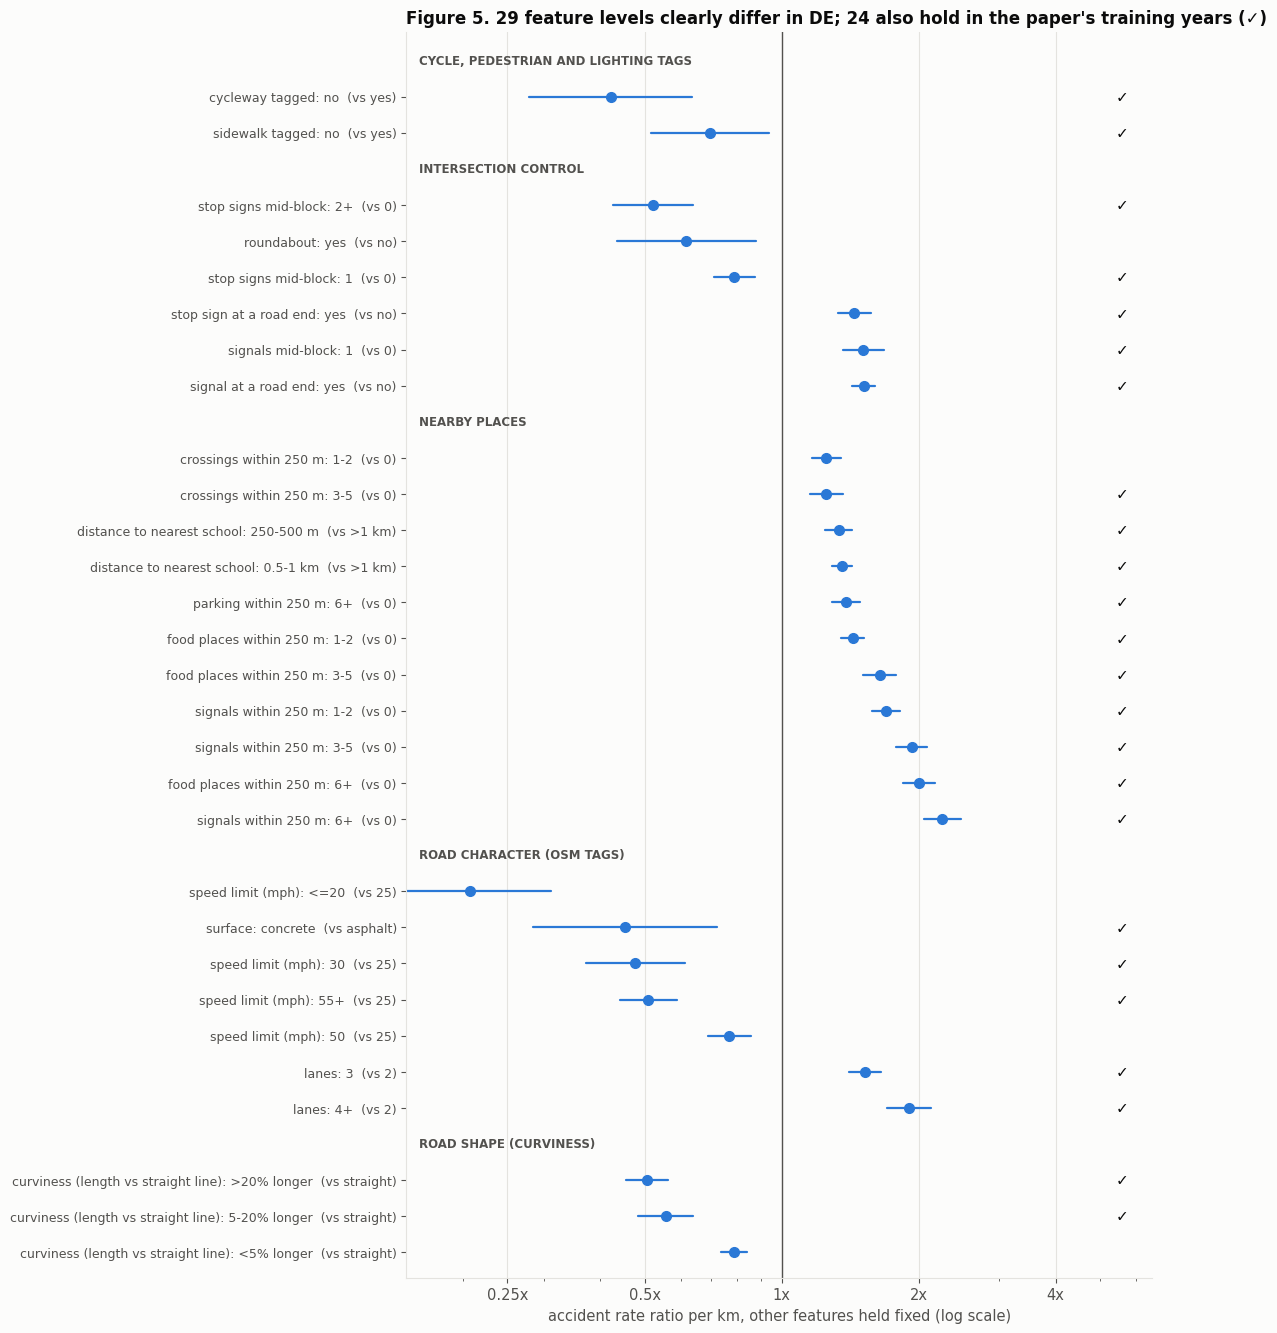

**Levels not clearly different**

|  | group | accidents | rate_ratio | ci_low | ci_high | reason |
|---|---|---|---|---|---|---|
| on a bridge: yes (vs no) | road_character | 25,251 | 1.2 | 1.03 | 1.39 | effect within 0.80-1.25x |
| crossing at a road end: yes (vs no) | intersection_control | 302 | 0.752 | 0.506 | 1.12 | interval includes 1 |
| signals mid-block: 2+ (vs 0) | intersection_control | 2,140 | 1.69 | 0.897 | 3.2 | interval includes 1 |
| crossings mid-block: 1 (vs 0) | intersection_control | 61,031 | 1.09 | 1.02 | 1.17 | effect within 0.80-1.25x |
| crossings mid-block: 2+ (vs 0) | intersection_control | 14,234 | 1.23 | 1.08 | 1.4 | effect within 0.80-1.25x |
| traffic calming mid-block: 1 (vs 0) | intersection_control | 1,035 | 1.2 | 0.973 | 1.48 | interval includes 1 |
| traffic calming mid-block: 2+ (vs 0) | intersection_control | 1,181 | 1.26 | 0.951 | 1.66 | interval includes 1 |
| crossings within 250 m: 6+ (vs 0) | nearby_places | 123,793 | 1.17 | 1.1 | 1.25 | effect within 0.80-1.25x |
| parking within 250 m: 1-2 (vs 0) | nearby_places | 39,740 | 1.23 | 1.15 | 1.31 | effect within 0.80-1.25x |
| parking within 250 m: 3-5 (vs 0) | nearby_places | 26,707 | 1.21 | 1.12 | 1.31 | effect within 0.80-1.25x |
| distance to nearest school: <250 m (vs >1 km) | nearby_places | 11,651 | 1.18 | 1.07 | 1.29 | effect within 0.80-1.25x |
| speed limit (mph): 35 (vs 25) | road_character | 24,005 | 0.804 | 0.722 | 0.895 | effect within 0.80-1.25x |
| speed limit (mph): 40 (vs 25) | road_character | 16,850 | 0.954 | 0.851 | 1.07 | interval includes 1 |
| speed limit (mph): 45 (vs 25) | road_character | 31,161 | 0.948 | 0.848 | 1.06 | interval includes 1 |
| lanes: 1 (vs 2) | road_character | 8,320 | 1.13 | 0.98 | 1.31 | interval includes 1 |
| surface: mixed (vs asphalt) | road_character | 4,959 | 1.07 | 0.638 | 1.78 | interval includes 1 |
| surface: other (vs asphalt) | road_character | 499 | 0.929 | 0.482 | 1.79 | interval includes 1 |
| surface: paved (vs asphalt) | road_character | 890 | 0.655 | 0.392 | 1.09 | interval includes 1 |

In [51]:
def effect_table(models_window, first, second):
    """Both states' effects side by side for feature levels (not controls) with the same reference level."""
    tables = {s: models_window[s].query("not is_control").set_index(["variable", "level"]) for s in (first, second)}
    both = tables[first].join(tables[second], how="inner", lsuffix=f"_{first}", rsuffix=f"_{second}")
    both = both[both[f"reference_{first}"] == both[f"reference_{second}"]].copy()
    both["group"] = [FEATURE_GROUP_OF_VARIABLE.get(v, "?") for v, _ in both.index]
    both["same_direction"] = (both[f"rate_ratio_{first}"] - 1) * (both[f"rate_ratio_{second}"] - 1) > 0
    both["replicates"] = both[f"clear_{first}"] & both[f"clear_{second}"] & both["same_direction"]
    return both


def plot_effect_summary(models_window, first, second, max_rows=40):
    """Figure 5: grouped forest plot of feature effects in both states."""
    apply_chart_style()
    both = effect_table(models_window, first, second)
    both = both[both[f"clear_{first}"] | both[f"clear_{second}"]]
    both = both.assign(order=both["group"], sort=both[f"rate_ratio_{first}"]).sort_values(["order", "sort"])
    if len(both) > max_rows:   # keep the strongest if there are very many
        strength = np.abs(np.log(both[[f"rate_ratio_{first}", f"rate_ratio_{second}"]])).max(axis=1)
        both = both.loc[strength.sort_values(ascending=False).index[:max_rows]].sort_values(["order", "sort"])
    n_rows = len(both) + both["group"].nunique()
    fig, ax = plt.subplots(figsize=(11.5, 0.33 * n_rows + 2.0), layout="constrained")
    y, ticks, labels, current = 0, [], [], None
    for (variable, level), line in both.iterrows():
        if line["group"] != current:
            current = line["group"]
            ax.text(0.16, y, FEATURE_GROUP_NAMES.get(current, current).upper(), fontsize=8.5, fontweight="bold", color=INK_SECONDARY, va="center")
            y += 1
        for offset, state in zip((-0.15, 0.15), (first, second)):
            ratio, low, high = line[f"rate_ratio_{state}"], line[f"ci_low_{state}"], line[f"ci_high_{state}"]
            colour, filled = STATE_COLORS[state], line[f"clear_{state}"]
            ax.plot([low, high], [y + offset] * 2, color=colour, lw=1.6, solid_capstyle="round")
            ax.plot(ratio, y + offset, "o", ms=7, mfc=colour if filled else SURFACE, mec=colour, mew=1.6)
        if line["replicates"]:
            ax.text(5.6, y, "✓", fontsize=11, color=INK, va="center", ha="center")
        ticks.append(y); labels.append(f"{VARIABLE_LABELS.get(variable, variable)}: {level}  (vs {line[f'reference_{first}']})")
        y += 1
    ax.axvline(1, color=INK_SECONDARY, lw=1)
    ax.set_xscale("log"); ax.set_xlim(0.15, 6.5)
    ax.set_xticks([0.25, 0.5, 1, 2, 4]); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}x")); ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_yticks(ticks); ax.set_yticklabels(labels, fontsize=9); ax.set_ylim(y - 0.3, -0.8)
    ax.xaxis.grid(True)
    ax.set_xlabel("accident rate ratio per km, other features held fixed (log scale)")
    n_rep = int(both["replicates"].sum())
    ax.set_title(f"Figure 5. {n_rep} of {len(both)} feature levels shown are clear and point the same way in both states (✓)")
    handles = [Line2D([], [], color=STATE_COLORS[s], marker="o", ms=7, lw=1.6, label=s) for s in (first, second)]
    handles.append(Line2D([], [], color=INK_SECONDARY, marker="o", ms=7, mfc=SURFACE, lw=0, label="not clearly different"))
    fig.legend(handles=handles, loc="outside lower center", ncol=3, fontsize=9)
    save_figure(fig, "fig7_effect_summary")
    plt.show()
    return both


def effect_table_one_state(model_window, window_comparison):
    """One state's joint-model effects for feature levels, with the training-years check.

    Takes the state's headline model table and the table from `compare_joint_models(train, full)`.
    Returns one row per (variable, level): the model columns plus `group` and `holds_in_training_years`
    (clear in both windows, same direction, same reference level).
    """
    table = model_window.query("not is_control").set_index(["variable", "level"])
    check = window_comparison.set_index(["variable", "level"])
    holds = check["same_reference"] & check["clear_train"] & check["clear_full"] & check["same_direction"]
    table["holds_in_training_years"] = holds.reindex(table.index).fillna(False).astype(bool)
    table["group"] = [FEATURE_GROUP_OF_VARIABLE.get(variable, "?") for variable, _ in table.index]
    return table


def plot_effect_summary_one_state(effects, state):
    """Figure 5 (one state): feature levels that clearly differ, other features held fixed; a tick marks those that also hold in the training years."""
    apply_chart_style()
    shown = effects[effects["clear"]].assign(order=lambda t: t["group"]).sort_values(["order", "rate_ratio"])
    if not len(shown):
        print("No feature level is clearly different.")
        return
    n_rows = len(shown) + shown["group"].nunique()
    fig, ax = plt.subplots(figsize=(11.5, 0.33 * n_rows + 2.0), layout="constrained")
    y, ticks, labels, current = 0, [], [], None
    for (variable, level), line in shown.iterrows():
        if line["group"] != current:
            current = line["group"]
            ax.text(0.16, y, FEATURE_GROUP_NAMES.get(current, current).upper(), fontsize=8.5, fontweight="bold", color=INK_SECONDARY, va="center")
            y += 1
        ax.plot([line["ci_low"], line["ci_high"]], [y, y], color=STATE_COLORS[state], lw=1.6, solid_capstyle="round")
        ax.plot(line["rate_ratio"], y, "o", ms=7, color=STATE_COLORS[state])
        if line["holds_in_training_years"]:
            ax.text(5.6, y, "✓", fontsize=11, color=INK, va="center", ha="center")
        ticks.append(y); labels.append(f"{VARIABLE_LABELS.get(variable, variable)}: {level}  (vs {line['reference']})")
        y += 1
    ax.axvline(1, color=INK_SECONDARY, lw=1)
    ax.set_xscale("log"); ax.set_xlim(0.15, 6.5)
    ax.set_xticks([0.25, 0.5, 1, 2, 4]); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:g}x")); ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_yticks(ticks); ax.set_yticklabels(labels, fontsize=9); ax.set_ylim(y - 0.3, -0.8)
    ax.xaxis.grid(True)
    ax.set_xlabel("accident rate ratio per km, other features held fixed (log scale)")
    n_hold = int(shown["holds_in_training_years"].sum())
    ax.set_title(f"Figure 5. {len(shown)} feature levels clearly differ in {state}; {n_hold} also hold in the paper's training years (✓)")
    save_figure(fig, "fig5_effect_summary")
    plt.show()


def unclear_levels_table(effects):
    """Feature levels that are NOT clearly different, with the reason (so nothing is hidden by the figure)."""
    rest = effects[~effects["clear"]].copy()
    reasons = []
    for _, row in rest.iterrows():
        if not row["estimable"]:
            reasons.append("not estimable (explained by another feature)")
        elif row["accidents"] < MIN_ACCIDENTS_FOR_VERDICT:
            reasons.append(f"fewer than {MIN_ACCIDENTS_FOR_VERDICT} accidents")
        elif row["ci_low"] <= 1 <= row["ci_high"]:
            reasons.append("interval includes 1")
        else:
            reasons.append(f"effect within {1 / MIN_EFFECT_RATIO:.2f}-{MIN_EFFECT_RATIO}x")
    rest["reason"] = reasons
    rest.index = [f"{VARIABLE_LABELS.get(variable, variable)}: {level} (vs {r})" for (variable, level), r in zip(rest.index, rest["reference"])]
    return rest[["group", "accidents", "rate_ratio", "ci_low", "ci_high", "reason"]]


first = STATES[0]
second = STATES[1] if len(STATES) > 1 else None
replication_windows = {state: compare_joint_models(models[state]["train"].query("not is_control"), models[state]["full"].query("not is_control"), "train", "full") for state in STATES}
if second is None:
    effects_shown = effect_table_one_state(models[first][HEADLINE], replication_windows[first])
    plot_effect_summary_one_state(effects_shown, first)
    show_markdown("**Levels not clearly different**\n\n" + table_to_markdown(unclear_levels_table(effects_shown).round(3)))
else:
    effects_shown = plot_effect_summary({s: models[s][HEADLINE] for s in STATES}, first, second)

**Figure 6: do the findings hold in the paper's training years (and, with two states, in the other state)?** Each dot is a feature level.
Dots near the dashed diagonal agree; filled dots are clear in both and point the same way.

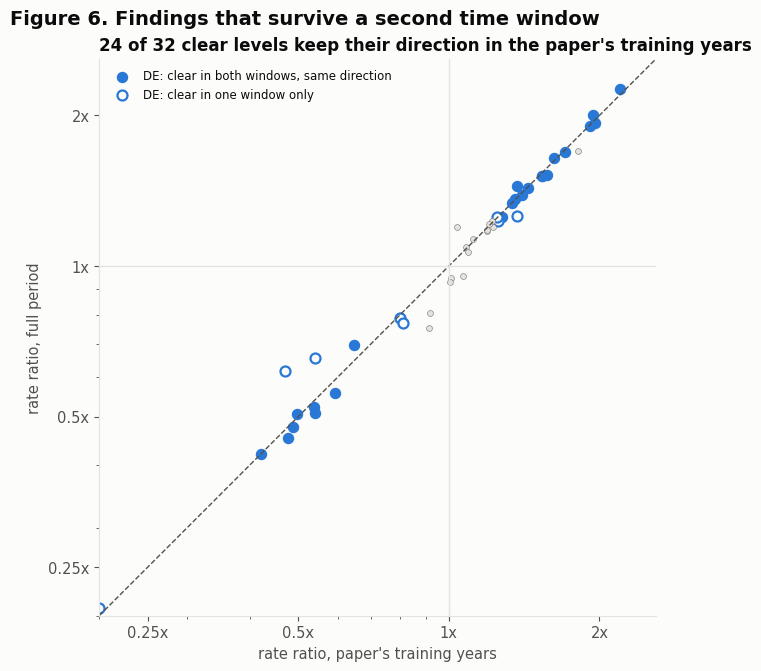

In [52]:
def plot_stability(rep_states, rep_windows, first, second):
    """Figure 6: cross-state agreement (left) and training-years-vs-full-period agreement (right). Returns the two tables used."""
    apply_chart_style()
    if rep_states is None:   # one state: only the time-window panel
        fig, ax_window = plt.subplots(figsize=(7.5, 6.6), layout="constrained")
        ax_state = None
    else:
        fig, (ax_state, ax_window) = plt.subplots(1, 2, figsize=(14.5, 6.6), layout="constrained")

    def prepare(table, a, b):
        table = table[table["same_reference"] & ~table["variable"].isin(["length", "road_type"])].copy()
        table["either_clear"] = table[f"clear_{a}"] | table[f"clear_{b}"]
        table["replicated"] = table[f"clear_{a}"] & table[f"clear_{b}"] & table["same_direction"]
        table["opposite"] = table["either_clear"] & ~table["same_direction"]
        return table

    def axis_limits(*series, floor=0.2, ceiling=5.0):
        values = pd.concat(series)
        return max(floor, values.min() / 1.15), min(ceiling, values.max() * 1.15)

    def scatter(ax, table, a, b, colour):
        x, y = table[f"rate_ratio_{a}"], table[f"rate_ratio_{b}"]
        low, high = axis_limits(x, y)
        x, y = x.clip(low, high), y.clip(low, high)   # an extreme level is drawn on the frame instead of stretching the axes
        ax.plot([low, high], [low, high], color=INK_SECONDARY, lw=1, ls="--")
        ax.axhline(1, color=GRID_COLOR, lw=1); ax.axvline(1, color=GRID_COLOR, lw=1)
        none = ~table["either_clear"]
        ax.scatter(x[none], y[none], s=24, color=GRID_COLOR, edgecolor=INK_MUTED, linewidth=0.6, label="not clear in either")
        some = table["either_clear"] & ~table["replicated"]
        ax.scatter(x[some], y[some], s=52, facecolor=SURFACE, edgecolor=colour, linewidth=1.6, label="clear in one only, or opposite")
        ax.scatter(x[table["replicated"]], y[table["replicated"]], s=52, color=colour, label="clear and same direction in both")
        for _, line in table[table["opposite"]].iterrows():
            ax.annotate(f"{VARIABLE_LABELS.get(line['variable'], line['variable'])}: {line['level']}", (line[f"rate_ratio_{a}"], line[f"rate_ratio_{b}"]),
                        xytext=(6, 5), textcoords="offset points", fontsize=8.5, color=INK_SECONDARY)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(low, high); ax.set_ylim(low, high)
        ticks = [t for t in (0.25, 0.5, 1, 2, 4) if low <= t <= high]
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_locator(plt.FixedLocator(ticks)); axis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}x")); axis.set_minor_formatter(plt.NullFormatter())
        ax.set_aspect("equal")

    if rep_states is None:   # one state: nothing to compare across states
        across_states = None   # the cross-state panel needs two states (set STATES = ["DE", "MD"])
    else:
        across_states = prepare(rep_states, first, second)
        scatter(ax_state, across_states, first, second, INK)
        ax_state.set_xlabel(f"{first} rate ratio"); ax_state.set_ylabel(f"{second} rate ratio")
        ax_state.legend(loc="upper left", fontsize=8.5)
        n1 = int(across_states["either_clear"].sum())
        ax_state.set_title(f"{int(across_states['replicated'].sum())} of {n1} clear levels hold in both states")

    # right: training vs full period, both states in their own colour
    parts = []
    for state, table in rep_windows.items():
        prepared = prepare(table, "train", "full")
        prepared["state"] = state
        parts.append(prepared)
        prepared = prepared.assign(rate_ratio_train=prepared["rate_ratio_train"].clip(0.2, 5.0), rate_ratio_full=prepared["rate_ratio_full"].clip(0.2, 5.0))
        parts[-1] = prepared
        ax_window.scatter(prepared[prepared["replicated"]]["rate_ratio_train"], prepared[prepared["replicated"]]["rate_ratio_full"], s=52, color=STATE_COLORS[state], label=f"{state}: clear in both windows, same direction")
        some = prepared["either_clear"] & ~prepared["replicated"]
        ax_window.scatter(prepared[some]["rate_ratio_train"], prepared[some]["rate_ratio_full"], s=52, facecolor=SURFACE, edgecolor=STATE_COLORS[state], linewidth=1.6, label=f"{state}: clear in one window only")
        ax_window.scatter(prepared[~prepared["either_clear"]]["rate_ratio_train"], prepared[~prepared["either_clear"]]["rate_ratio_full"], s=18, color=GRID_COLOR, edgecolor=INK_MUTED, linewidth=0.5)
    window_table = pd.concat(parts)
    low, high = axis_limits(window_table["rate_ratio_train"], window_table["rate_ratio_full"])
    ax_window.plot([low, high], [low, high], color=INK_SECONDARY, lw=1, ls="--")
    ax_window.axhline(1, color=GRID_COLOR, lw=1); ax_window.axvline(1, color=GRID_COLOR, lw=1)
    ax_window.set_xscale("log"); ax_window.set_yscale("log"); ax_window.set_xlim(low, high); ax_window.set_ylim(low, high)
    ticks = [t for t in (0.25, 0.5, 1, 2, 4) if low <= t <= high]
    for axis in (ax_window.xaxis, ax_window.yaxis):
        axis.set_major_locator(plt.FixedLocator(ticks)); axis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}x")); axis.set_minor_formatter(plt.NullFormatter())
    ax_window.set_aspect("equal")
    ax_window.set_xlabel("rate ratio, paper's training years"); ax_window.set_ylabel("rate ratio, full period")
    ax_window.legend(loc="upper left", fontsize=8.5)
    n2 = int(window_table["either_clear"].sum())
    ax_window.set_title(f"{int(window_table['replicated'].sum())} of {n2} clear levels keep their direction in the paper's training years")
    fig.suptitle("Figure 6. Findings that survive a second time window" + (" and a second state" if rep_states is not None else ""), x=0.01, ha="left")
    save_figure(fig, "fig8_stability")
    plt.show()
    return across_states, window_table


replication_states = (compare_joint_models(models[first][HEADLINE].query("not is_control"), models[second][HEADLINE].query("not is_control"), first, second)
                      if second else None)
stability_states, stability_windows = plot_stability(replication_states, replication_windows, first, second)

**Summary by feature group.** How many feature levels were tested in each group, how many are clear, and how many also hold in the paper's training years (and, with two states, in both states).

In [53]:
def summarise_feature_groups(models_window, stability_states, stability_windows, first, second):
    """One row per feature group: levels tested, clear in each state, clear in both with the same direction, and also stable in the paper's training years."""
    rows = {}
    if second is None:   # one state: tested, clear, and also clear in the training years
        table = models_window[first].query("not is_control")
        table = table[table["variable"].isin(FEATURE_GROUP_OF_VARIABLE)].assign(group=lambda t: t["variable"].map(FEATURE_GROUP_OF_VARIABLE))
        rows[f"levels_tested_{first}"] = table.groupby("group").size()
        rows[f"clear_{first}"] = table.groupby("group")["clear"].sum()
        windows = stability_windows[stability_windows["variable"].isin(FEATURE_GROUP_OF_VARIABLE)].copy()
        rows["also_hold_in_training_years"] = windows["replicated"].groupby(windows["variable"].map(FEATURE_GROUP_OF_VARIABLE)).sum()
        summary = pd.DataFrame(rows).fillna(0).astype(int)
        summary.insert(0, "what", [FEATURE_GROUP_NAMES[g] for g in summary.index])
        return summary
    for state in (first, second):
        table = models_window[state].query("not is_control")
        table = table[table["variable"].isin(FEATURE_GROUP_OF_VARIABLE)].assign(group=lambda t: t["variable"].map(FEATURE_GROUP_OF_VARIABLE))
        rows[f"levels_tested_{state}"] = table.groupby("group").size()
        rows[f"clear_{state}"] = table.groupby("group")["clear"].sum()
    both = stability_states[stability_states["variable"].isin(FEATURE_GROUP_OF_VARIABLE)].copy()
    both["group"] = both["variable"].map(FEATURE_GROUP_OF_VARIABLE)
    rows["clear_in_both_states"] = both["replicated"].groupby(both["group"]).sum()
    stable = set()
    for state, table in stability_windows.groupby("state"):
        stable |= {(state, v, l) for v, l, r in zip(table["variable"], table["level"], table["replicated"]) if r}
    both["stable_over_time"] = [all(((s, v, l) in stable) for s in (first, second)) for v, l in zip(both["variable"], both["level"])]
    rows["also_hold_in_training_years"] = (both["replicated"] & both["stable_over_time"]).groupby(both["group"]).sum()
    summary = pd.DataFrame(rows).fillna(0).astype(int)
    summary.insert(0, "what", [FEATURE_GROUP_NAMES[g] for g in summary.index])
    return summary


group_summary = summarise_feature_groups({s: models[s][HEADLINE] for s in STATES}, stability_states, stability_windows, first, second)
show_markdown(table_to_markdown(group_summary))

|  | what | levels_tested_DE | clear_DE | also_hold_in_training_years |
|---|---|---|---|---|
| cycle_pedestrian_lighting | cycle, pedestrian and lighting tags | 2 | 2 | 2 |
| intersection_control | intersection control | 12 | 6 | 5 |
| nearby_places | nearby places | 15 | 11 | 10 |
| road_character | road character (OSM tags) | 15 | 7 | 5 |
| road_shape | road shape (curviness) | 3 | 3 | 2 |

## 13. Hand-off: the files the model notebook reads
1. **`{STATE}_osm_features.parquet`**: one row per directed road, in the benchmark's adjacency order (`node_1_idx`, `node_2_idx` are the keys).
   Raw features, unscaled, missing kept as NaN, plus `*_filled` and `*_is_est` for the three gap-filled tags.
2. **`{STATE}_osm_features_meta.json`**: feature-group definitions (used by the model notebook to switch groups on and off), a written preprocessing recipe, gate decisions, thresholds, versions.
3. **`osm_data_dictionary.csv`**: every column with group, meaning, unit, missing-value rule and fill rate.

> **Why raw and unscaled.** Scaling, encoding and missing-value handling depend on the model and on the training years, so they belong in the model code, fitted on the training period only.
> The recipe below says what we recommend. **Alternative:** a ready-scaled matrix (convenient, but it hides choices and could leak test-period statistics).

In [54]:
# One entry per column family: (group, kind, unit, meaning, missing rule). {k} is filled per column.
def data_dictionary_entries():
    """Return {column: (group, kind, unit, meaning, missing_rule)} for every column the pipeline can write."""
    entries = {}
    add = lambda column, *info: entries.__setitem__(column, info)

    for column, meaning in (("node_1_idx", "start node of the directed road (row position in the dataset's node table)"),
                            ("node_2_idx", "end node of the directed road"), ("road_u", "smaller of the two node indices (key of the physical road)"),
                            ("road_v", "larger of the two node indices"), ("length_m", "road length recorded in the dataset")):
        add(column, "id", "id" if column != "length_m" else "numeric", "m" if column == "length_m" else "", meaning, "never missing")
    add("has_reverse", "id", "binary", "", "the opposite direction also exists (two-way road)", "never missing")
    add("u_lt_v", "id", "binary", "", "start node has the lower index (accidents are recorded mostly on this direction)", "never missing")
    add("match_type", "diagnostic", "category", "", "how the road was matched to OSM: exact, reverse, nearest, unmatched", "never missing")
    add("match_dist_m", "diagnostic", "numeric", "m", "distance to the OSM road for nearest matches (0 for exact and reverse)", "NaN for unmatched")
    add("len_ratio", "diagnostic", "numeric", "", "OSM road length / dataset road length", "NaN for unmatched")
    add("osm_highway", "diagnostic", "category", "", "the matched OSM road's own highway tag", "NaN for unmatched")
    add("cand_dist_m", "diagnostic", "numeric", "m", "distance of the nearest OSM candidate for roads that reached the nearest tier (also when rejected)", "NaN if exact/reverse matched")
    add("cand_len_ratio", "diagnostic", "numeric", "", "length ratio of that candidate", "NaN if exact/reverse matched")
    add("has_osm_match", "diagnostic", "binary", "", "1 if the road matched an OSM road (any tier)", "never missing")

    add("road_character_maxspeed_mph", "road_character", "numeric", "mph", "speed limit from the OSM road's maxspeed (highest if several; km/h converted)", "NaN: no parsable maxspeed tag, or road unmatched (unknown, not zero)")
    add("road_character_lanes", "road_character", "count", "lanes", "number of lanes from the OSM lanes tag (highest if several)", "NaN: no lanes tag, or unmatched")
    add("road_character_surface", "road_character", "category", "", "surface type ('mixed' if the road's OSM pieces have different surfaces); categories on fewer than %d roads are folded into 'other'" % RARE_CATEGORY_MIN_ROADS, "NaN: no surface tag, or unmatched")
    add("road_character_bridge", "road_character", "binary", "", "1 if the OSM road is tagged as a bridge", "0 = not tagged as bridge; NaN only for unmatched")
    add("road_character_tunnel", "road_character", "binary", "", "1 if the OSM road is tagged as a tunnel", "0 = not tagged as tunnel; NaN only for unmatched")
    for kind, name in (("signal", "traffic signals"), ("stop", "a stop sign"), ("give_way", "a give-way sign"), ("crossing", "a pedestrian crossing")):
        for end in ("start", "end"):
            add(f"intersection_control_{kind}_{end}", "intersection_control", "binary", "", f"1 if the OSM node at the road's {end} carries {name}", "0 = not mapped there (not necessarily absent in reality); NaN for unmatched")
    add("intersection_control_roundabout", "intersection_control", "binary", "", "1 if the OSM road is part of a roundabout", "0 = not tagged; NaN for unmatched")
    for kind in TAGGED_NODE_KINDS:
        add(f"intersection_control_{kind}_midblock", "intersection_control", "count", "points", f"{kind.replace('_', ' ')} points in the middle of the road, recovered from the XML after simplification removed them (within {MIDBLOCK_NODE_MAX_M} m of the road)", "0 = none found; NaN for unmatched")
    add("cycle_pedestrian_lighting_cycleway_any", "cycle_pedestrian_lighting", "binary", "", "any cycleway tag (cycleway, :left, :right, :both) says a cycle lane exists", "NaN = not tagged (unknown), or unmatched; 0 = tagged 'no'")
    add("cycle_pedestrian_lighting_sidewalk_any", "cycle_pedestrian_lighting", "binary", "", "the sidewalk tag says there is a sidewalk (includes 'separate')", "NaN = not tagged, or unmatched; 0 = tagged 'no'")
    add("cycle_pedestrian_lighting_lit", "cycle_pedestrian_lighting", "binary", "", "the lit tag says the road is lit", "NaN = not tagged, or unmatched; 0 = tagged 'no'")
    place_text = {"school": "schools", "bar_pub": "bars and pubs", "food": "restaurants and fast food", "parking": "parking places", "bus_stop": "bus stops",
                  "crossing": "pedestrian crossings", "signal": "traffic signals"}
    for kind, text in place_text.items():
        for radius in PLACE_RADII_M:
            add(f"nearby_places_{kind}_{radius}m", "nearby_places", "count", "places", f"number of {text} within {radius} m of the road's midpoint", "never missing")
        add(f"nearby_places_{kind}_nearest_m", "nearby_places", "distance", "m", f"distance from the road's midpoint to the nearest of {text}", "NaN only if the state has none at all")
    add("road_shape_sinuosity", "road_shape", "numeric", "ratio", "road length / straight-line distance between its ends (1 = straight)", "NaN if the two ends coincide")
    for column, text in (("road_character_maxspeed_mph", "speed limit"), ("road_character_lanes", "lane count"), ("road_character_surface", "surface")):
        add(f"{column}_filled", "road_character_filled", "numeric" if column != "road_character_surface" else "category", "mph" if column == "road_character_maxspeed_mph" else "",
            f"{text}: the real OSM value where known, otherwise a validated estimate (see {column}_is_est)", "NaN if the estimate method failed the gate (Stage 10) for this state")
        add(f"{column}_is_est", "road_character_filled", "binary", "", f"1 if the {text} in {column}_filled is an estimate, 0 if it is the real OSM value", "never missing")
        add(f"{column}_est_source", "diagnostic", "category", "", "known / neighbour / neighbour2 / road_type / state_value / none: where the estimate came from", "never missing")
    return entries

In [55]:
MODEL_READY_ID_COLUMNS = ["node_1_idx", "node_2_idx", "road_u", "road_v", "has_reverse", "u_lt_v", "length_m", "match_type", "has_osm_match"]


def build_model_ready_table(state, result, state_fill):
    """Keys, raw features (unscaled, missing kept) and the filled columns with their flags, in the dataset's adjacency order."""
    roads, features = result["roads"], result["road_features"]
    ids = roads[["node_1_idx", "node_2_idx", "road_u", "road_v", "has_reverse", "u_lt_v", "length_m", "match_type"]].copy().reset_index(drop=True)
    ids["has_osm_match"] = (ids["match_type"] != "unmatched").astype(float)
    raw = features.drop(columns=["node_1_idx", "node_2_idx"]).reset_index(drop=True)
    filled = state_fill["filled"].reset_index(drop=True)
    table = pd.concat([ids, raw, filled], axis=1)
    assert len(table) == len(roads) and not table.columns.duplicated().any()
    assert not any("accident" in c.lower() for c in table.columns), "a label-derived column slipped into the feature table"
    return table


def redundant_pairs(table, threshold=0.9, sample=100_000, seed=RANDOM_SEED):
    """Pairs of numeric feature columns that move together (Spearman |rho| at or above the threshold), strongest first, on a random sample of roads."""
    numeric = table.select_dtypes("number").drop(columns=[c for c in table.columns if c in MODEL_READY_ID_COLUMNS or c.endswith("_is_est")], errors="ignore")
    numeric = numeric.loc[:, numeric.nunique() > 1]
    if len(numeric) > sample:
        numeric = numeric.sample(sample, random_state=seed)
    corr = numeric.corr(method="spearman")
    pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("spearman").reset_index()
    pairs.columns = ["feature_a", "feature_b", "spearman"]
    return pairs[pairs["spearman"].abs() >= threshold].sort_values("spearman", key=abs, ascending=False).reset_index(drop=True)


PREPROCESSING_RECIPE = [
    "Features are RAW. Fit every scaler, encoder and imputer on the TRAINING years' roads only (SPLIT in the config), then apply to validation and test.",
    "Directed rows: OSM-derived values are identical in both directions of a road; the start/end columns swap meaning between the two directions.",
    "Counts and distances (nearby_places_*_{100,250,500,1000}m, nearby_places_*_nearest_m, intersection_control_*_midblock): apply log1p, then standardise. A nearest-distance is NaN only if a state has no place of that kind; fill with the maximum plus a flag.",
    "Road length, node degree and road type are NOT repeated here: take them from the benchmark's own features. road_shape holds only curviness (road_shape_sinuosity).",
    "Binary flags in intersection_control: NaN means the road was not matched (check has_osm_match). Fill with 0 and keep has_osm_match as an input. A 0 means 'not mapped there', which is weaker than 'absent'.",
    "cycle_pedestrian_lighting flags are three-state: 1 yes, 0 tagged 'no', NaN not tagged. Encode as three categories rather than filling; they are too sparse to fill.",
    "road_character speed limit, lanes, surface: use the *_filled columns (with *_is_est) for models, or the raw columns with a missing indicator. Encode surface one-hot (categories include 'other'). Never mix: an estimate is not a measurement.",
    "A feature group is defined by its prefix (road_character, road_character_filled, intersection_control, cycle_pedestrian_lighting, nearby_places, road_shape); the meta file lists the columns of each.",
    "Many nearby_places columns are near-duplicates across radii (see redundant_pairs in the meta file). Choose one or two radii per place type, or reduce them, before comparing group importance.",
    "No feature uses accident counts, and no feature was selected, dropped or filled using them.",
]


def write_hand_off(state, result, state_fill, fill_validation, data_dir):
    """Write the model-ready parquet and its metadata for one state; returns the table and the metadata dict."""
    table = build_model_ready_table(state, result, state_fill)
    pairs = redundant_pairs(table)
    parquet_path = data_dir / f"{state}_osm_features.parquet"
    table.to_parquet(parquet_path, index=False)

    feature_columns = [c for c in table.columns if c not in MODEL_READY_ID_COLUMNS and not c.endswith("_est_source")]
    groups = {"road_character": [c for c in feature_columns if c.startswith("road_character_") and not c.endswith(("_filled", "_is_est"))],
              "road_character_filled": [c for c in feature_columns if c.startswith("road_character_") and c.endswith(("_filled", "_is_est"))]}
    for group in ("intersection_control", "cycle_pedestrian_lighting", "nearby_places", "road_shape"):
        groups[group] = [c for c in feature_columns if c.startswith(group + "_")]
    metadata = {
        "state": state, "pipeline_version": PIPELINE_VERSION, "rows": len(table), "row_order": "same as adj.coalesce().indices() of the dataset",
        "keys": ["node_1_idx", "node_2_idx"], "id_columns": MODEL_READY_ID_COLUMNS,
        "feature_groups_for_ablation": groups,
        "diagnostic_columns_not_features": [c for c in table.columns if c.endswith("_est_source")],
        "gap_filling": {FEATURE_LABELS[c]: {"decision": e["decision"], "reason": e["reason"]} for c, e in fill_validation.items()},
        "preprocessing_recipe": PREPROCESSING_RECIPE,
        "redundant_pairs_spearman_0.9": pairs.head(40).round(3).to_dict(orient="records"),
        "split": SPLIT[state], "split_note": "the paper's Table 7 (arXiv 2311.00164)",
        "thresholds": configured_thresholds(), "environment": ENVIRONMENT,
        "fill_rate": table[feature_columns].notna().mean().round(4).to_dict(),
    }
    meta_path = data_dir / f"{state}_osm_features_meta.json"
    with open(meta_path, "w") as file:
        json.dump(metadata, file, indent=2, default=str)
    return table, metadata


model_ready, model_ready_meta = {}, {}
for state in STATES:
    model_ready[state], model_ready_meta[state] = write_hand_off(state, results[state], fills[state], fills[state]["validation"], DATA_DIR)
    print(f"{state}: wrote {len(model_ready[state]):,} rows x {model_ready[state].shape[1]} columns; groups: " +
          ", ".join(f"{g} {len(c)}" for g, c in model_ready_meta[state]["feature_groups_for_ablation"].items()))

entries = data_dictionary_entries()
all_columns = list(dict.fromkeys(c for s in STATES for c in model_ready[s].columns))
undocumented = [c for c in all_columns if c not in entries]
assert not undocumented, f"columns without a data dictionary entry: {undocumented}"
dictionary = pd.DataFrame([{"column": c, "group": entries[c][0], "type": entries[c][1], "unit": entries[c][2], "meaning": entries[c][3], "missing_rule": entries[c][4],
                            **{f"fill_{s}": model_ready[s][c].notna().mean() if c in model_ready[s].columns else np.nan for s in STATES}} for c in all_columns]).set_index("column")
dictionary.round(4).to_csv(DATA_DIR / "osm_data_dictionary.csv")
print(f"data dictionary: {len(dictionary)} columns, all documented; saved to osm_data_dictionary.csv")

DE: wrote 116,196 rows x 76 columns; groups: road_character 5, road_character_filled 6, intersection_control 14, cycle_pedestrian_lighting 3, nearby_places 35, road_shape 1
data dictionary: 76 columns, all documented; saved to osm_data_dictionary.csv


**The data dictionary** (first rows of each group; the full table is in `osm_data_dictionary.csv`). Fill rate = share of directed roads with a value.

In [56]:
for group in ["road_character", "road_character_filled", "intersection_control", "cycle_pedestrian_lighting", "nearby_places", "road_shape"]:
    part = dictionary[dictionary["group"] == group]
    shown = part.head(8) if group in ("intersection_control", "nearby_places", "road_shape") else part
    show_markdown(f"**{group}** ({len(part)} columns{'; first 8 shown' if len(part) > len(shown) else ''})\n\n" + table_to_markdown(shown[["type", "unit", "meaning", "missing_rule"] + [f"fill_{s}" for s in STATES]].round(3)))

**road_character** (5 columns)

| column | type | unit | meaning | missing_rule | fill_DE |
|---|---|---|---|---|---|
| road_character_maxspeed_mph | numeric | mph | speed limit from the OSM road's maxspeed (highest if several; km/h converted) | NaN: no parsable maxspeed tag, or road unmatched (unknown, not zero) | 0.139 |
| road_character_lanes | count | lanes | number of lanes from the OSM lanes tag (highest if several) | NaN: no lanes tag, or unmatched | 0.126 |
| road_character_surface | category |  | surface type ('mixed' if the road's OSM pieces have different surfaces); categories on fewer than 50 roads are folded into 'other' | NaN: no surface tag, or unmatched | 0.173 |
| road_character_bridge | binary |  | 1 if the OSM road is tagged as a bridge | 0 = not tagged as bridge; NaN only for unmatched | 0.896 |
| road_character_tunnel | binary |  | 1 if the OSM road is tagged as a tunnel | 0 = not tagged as tunnel; NaN only for unmatched | 0.896 |

**road_character_filled** (6 columns)

| column | type | unit | meaning | missing_rule | fill_DE |
|---|---|---|---|---|---|
| road_character_maxspeed_mph_filled | numeric | mph | speed limit: the real OSM value where known, otherwise a validated estimate (see road_character_maxspeed_mph_is_est) | NaN if the estimate method failed the gate (Stage 10) for this state | 1 |
| road_character_maxspeed_mph_is_est | binary |  | 1 if the speed limit in road_character_maxspeed_mph_filled is an estimate, 0 if it is the real OSM value | never missing | 1 |
| road_character_lanes_filled | numeric |  | lane count: the real OSM value where known, otherwise a validated estimate (see road_character_lanes_is_est) | NaN if the estimate method failed the gate (Stage 10) for this state | 0.126 |
| road_character_lanes_is_est | binary |  | 1 if the lane count in road_character_lanes_filled is an estimate, 0 if it is the real OSM value | never missing | 1 |
| road_character_surface_filled | category |  | surface: the real OSM value where known, otherwise a validated estimate (see road_character_surface_is_est) | NaN if the estimate method failed the gate (Stage 10) for this state | 0.174 |
| road_character_surface_is_est | binary |  | 1 if the surface in road_character_surface_filled is an estimate, 0 if it is the real OSM value | never missing | 1 |

**intersection_control** (14 columns; first 8 shown)

| column | type | unit | meaning | missing_rule | fill_DE |
|---|---|---|---|---|---|
| intersection_control_signal_start | binary |  | 1 if the OSM node at the road's start carries traffic signals | 0 = not mapped there (not necessarily absent in reality); NaN for unmatched | 0.896 |
| intersection_control_signal_end | binary |  | 1 if the OSM node at the road's end carries traffic signals | 0 = not mapped there (not necessarily absent in reality); NaN for unmatched | 0.896 |
| intersection_control_stop_start | binary |  | 1 if the OSM node at the road's start carries a stop sign | 0 = not mapped there (not necessarily absent in reality); NaN for unmatched | 0.896 |
| intersection_control_stop_end | binary |  | 1 if the OSM node at the road's end carries a stop sign | 0 = not mapped there (not necessarily absent in reality); NaN for unmatched | 0.896 |
| intersection_control_give_way_start | binary |  | 1 if the OSM node at the road's start carries a give-way sign | 0 = not mapped there (not necessarily absent in reality); NaN for unmatched | 0.896 |
| intersection_control_give_way_end | binary |  | 1 if the OSM node at the road's end carries a give-way sign | 0 = not mapped there (not necessarily absent in reality); NaN for unmatched | 0.896 |
| intersection_control_crossing_start | binary |  | 1 if the OSM node at the road's start carries a pedestrian crossing | 0 = not mapped there (not necessarily absent in reality); NaN for unmatched | 0.896 |
| intersection_control_crossing_end | binary |  | 1 if the OSM node at the road's end carries a pedestrian crossing | 0 = not mapped there (not necessarily absent in reality); NaN for unmatched | 0.896 |

**cycle_pedestrian_lighting** (3 columns)

| column | type | unit | meaning | missing_rule | fill_DE |
|---|---|---|---|---|---|
| cycle_pedestrian_lighting_cycleway_any | binary |  | any cycleway tag (cycleway, :left, :right, :both) says a cycle lane exists | NaN = not tagged (unknown), or unmatched; 0 = tagged 'no' | 0.024 |
| cycle_pedestrian_lighting_sidewalk_any | binary |  | the sidewalk tag says there is a sidewalk (includes 'separate') | NaN = not tagged, or unmatched; 0 = tagged 'no' | 0.015 |
| cycle_pedestrian_lighting_lit | binary |  | the lit tag says the road is lit | NaN = not tagged, or unmatched; 0 = tagged 'no' | 0.006 |

**nearby_places** (35 columns; first 8 shown)

| column | type | unit | meaning | missing_rule | fill_DE |
|---|---|---|---|---|---|
| nearby_places_school_100m | count | places | number of schools within 100 m of the road's midpoint | never missing | 1 |
| nearby_places_school_250m | count | places | number of schools within 250 m of the road's midpoint | never missing | 1 |
| nearby_places_school_500m | count | places | number of schools within 500 m of the road's midpoint | never missing | 1 |
| nearby_places_school_1000m | count | places | number of schools within 1000 m of the road's midpoint | never missing | 1 |
| nearby_places_school_nearest_m | distance | m | distance from the road's midpoint to the nearest of schools | NaN only if the state has none at all | 1 |
| nearby_places_bus_stop_100m | count | places | number of bus stops within 100 m of the road's midpoint | never missing | 1 |
| nearby_places_bus_stop_250m | count | places | number of bus stops within 250 m of the road's midpoint | never missing | 1 |
| nearby_places_bus_stop_500m | count | places | number of bus stops within 500 m of the road's midpoint | never missing | 1 |

**road_shape** (1 columns)

| column | type | unit | meaning | missing_rule | fill_DE |
|---|---|---|---|---|---|
| road_shape_sinuosity | numeric | ratio | road length / straight-line distance between its ends (1 = straight) | NaN if the two ends coincide | 0.994 |

**Preprocessing recipe** (also saved in the meta file) **and redundant feature pairs.**

In [57]:
show_markdown("**Preprocessing recipe (also saved in the meta file)**\n\n" + "\n".join(f"{i}. {line}" for i, line in enumerate(PREPROCESSING_RECIPE, 1)))
for state in STATES:
    pairs = pd.DataFrame(model_ready_meta[state]["redundant_pairs_spearman_0.9"])
    show_markdown(f"**{state}: {len(pairs)} feature pairs with |Spearman| >= 0.9** (strongest 10)\n\n" + (table_to_markdown(pairs.head(10).set_index("feature_a")) if len(pairs) else "none"))

**Preprocessing recipe (also saved in the meta file)**

1. Features are RAW. Fit every scaler, encoder and imputer on the TRAINING years' roads only (SPLIT in the config), then apply to validation and test.
2. Directed rows: OSM-derived values are identical in both directions of a road; the start/end columns swap meaning between the two directions.
3. Counts and distances (nearby_places_*_{100,250,500,1000}m, nearby_places_*_nearest_m, intersection_control_*_midblock): apply log1p, then standardise. A nearest-distance is NaN only if a state has no place of that kind; fill with the maximum plus a flag.
4. Road length, node degree and road type are NOT repeated here: take them from the benchmark's own features. road_shape holds only curviness (road_shape_sinuosity).
5. Binary flags in intersection_control: NaN means the road was not matched (check has_osm_match). Fill with 0 and keep has_osm_match as an input. A 0 means 'not mapped there', which is weaker than 'absent'.
6. cycle_pedestrian_lighting flags are three-state: 1 yes, 0 tagged 'no', NaN not tagged. Encode as three categories rather than filling; they are too sparse to fill.
7. road_character speed limit, lanes, surface: use the *_filled columns (with *_is_est) for models, or the raw columns with a missing indicator. Encode surface one-hot (categories include 'other'). Never mix: an estimate is not a measurement.
8. A feature group is defined by its prefix (road_character, road_character_filled, intersection_control, cycle_pedestrian_lighting, nearby_places, road_shape); the meta file lists the columns of each.
9. Many nearby_places columns are near-duplicates across radii (see redundant_pairs in the meta file). Choose one or two radii per place type, or reduce them, before comparing group importance.
10. No feature uses accident counts, and no feature was selected, dropped or filled using them.

**DE: 2 feature pairs with |Spearman| >= 0.9** (strongest 10)

| feature_a | feature_b | spearman |
|---|---|---|
| road_character_maxspeed_mph | road_character_maxspeed_mph_filled | 1 |
| road_character_lanes | road_character_lanes_filled | 1 |

**Read the hand-off files back** and check them against the benchmark: same order, same keys, nothing label-derived.

In [58]:
# Read the hand-off files back and check them against the dataset: same order, same keys, nothing label-derived.
for state in STATES:
    saved = pd.read_parquet(DATA_DIR / f"{state}_osm_features.parquet")
    expected = dataset_tables[state]["roads"]
    assert len(saved) == len(expected)
    assert (saved["node_1_idx"].to_numpy() == expected["node_1_idx"].to_numpy()).all() and (saved["node_2_idx"].to_numpy() == expected["node_2_idx"].to_numpy()).all()
    assert not any("accident" in c.lower() for c in saved.columns)
    print(f"{state}: hand-off file re-read OK ({len(saved):,} rows, order matches the dataset, no label columns)")

DE: hand-off file re-read OK (116,196 rows, order matches the dataset, no label columns)


## 14. Findings and limitations
Every number in this stage is **computed by the run above**; nothing is typed in.

### 14.1 Findings (generated)

In [59]:
def first_value(table, variable, column, default=np.nan):
    """table.loc[variable, column] or `default` if the variable is not there."""
    return table.loc[variable, column] if variable in table.index else default


def consistent_trends(verdicts, states):
    """Variables whose trend is 'rises' (or 'falls') in every state, strongest first, with their from/to ratios per state."""
    found = []
    for variable in FEATURE_GROUP_OF_VARIABLE:
        if not all(variable in verdicts[s].index for s in states):
            continue
        directions = {verdicts[s].loc[variable, "trend"] for s in states}
        if len(directions) == 1 and directions <= {"rises", "falls"}:
            strength = np.mean([abs(np.log(verdicts[s].loc[variable, "to_ratio"] / verdicts[s].loc[variable, "from_ratio"])) for s in states])
            found.append((strength, variable, directions.pop()))
    return [(v, d) for _, v, d in sorted(found, reverse=True)]


def build_findings():
    """The findings as Markdown, written entirely from the computed tables."""
    states = STATES
    verdicts = {s: analyses[s][HEADLINE]["verdict"] for s in states}
    lines = []
    snapshot = {}
    for s in states:
        meta_path = DATA_DIR / f"{s}_osm_matching_meta.json"
        snapshot[s] = json.load(open(meta_path)).get("osm_snapshot_date") if meta_path.exists() else None
    n_features = sum(len(v) for g, v in model_ready_meta[states[0]]["feature_groups_for_ablation"].items() if g != "road_character_filled")

    lines.append("#### What we built")
    lines.append(f"* For each state, {n_features} OpenStreetMap-derived features per directed road in five groups (road character, intersection control, cycle/pedestrian/lighting tags, nearby places, road shape), "
                 + ", ".join(f"{len(model_ready[s]):,} roads in {s}" for s in states) + ". "
                 f"OSM snapshot: {', '.join(f'{s} {snapshot[s]}' for s in states if snapshot[s]) or 'see metadata'}; accident years: "
                 + ", ".join(f"{s} {analyses[s]['full']['first']} to {analyses[s]['full']['last']}" for s in states) + ".")
    lines.append("* The hand-off files (model-ready table, data dictionary, preprocessing recipe, group definitions) are in Stage 13; `osm_baseline_comparison.ipynb` reads them.")

    lines.append("\n#### Matching and coverage")
    for s in states:
        shares = results[s]["roads"]["match_type"].value_counts(normalize=True)
        c = coverage[s]
        lines.append(f"* **{s}**: {format_percent(1 - shares.get('unmatched', 0))} of roads matched to OSM (exact {format_percent(shares.get('exact', 0))}). "
                     f"Speed limit is known on {format_percent(c['overall'].loc['speed limit', 'all roads'])} of roads but on {format_percent(c['overall'].loc['speed limit', 'weighted by accidents'])} of accidents "
                     f"(major roads {format_percent(c['overall'].loc['speed limit', 'major roads'])}); lanes {format_percent(c['overall'].loc['lanes', 'all roads'])} / {format_percent(c['overall'].loc['lanes', 'weighted by accidents'])}; "
                     f"surface {format_percent(c['overall'].loc['surface', 'all roads'])} / {format_percent(c['overall'].loc['surface', 'weighted by accidents'])}; "
                     f"cycleway, sidewalk and lighting are known on {format_percent(c['overall'].loc['cycleway', 'all roads'])}, {format_percent(c['overall'].loc['sidewalk', 'all roads'])} and {format_percent(c['overall'].loc['lit', 'all roads'])} of roads.")
    lines.append("* **Low fill comes mostly from tags that were never mapped, not from failed matching**: even if every unmatched road were matched, speed-limit fill would rise by at most "
                 + ", ".join(f"{100 * coverage[s]['ceiling'].loc['speed limit', 'most extra from matching (points of roads)']:.1f} points ({s})" for s in states) + ".")

    lines.append("\n#### Gap-filling (speed limit, lanes, surface)")
    for s in states:
        for column in IMPUTE_FEATURES:
            entry = fills[s]["validation"][column]
            label = FEATURE_LABELS[column]
            if entry["decision"] == "none":
                lines.append(f"* {s} {label}: **not filled**; {entry['reason']}.")
            else:
                known = fill_coverage[s].loc[(column, 'roads'), 'known']
                est = fill_coverage[s].loc[(column, 'roads'), 'estimated']
                lines.append(f"* {s} {label}: **filled** ({'neighbours + road type' if entry['decision'] == 'full' else 'road type'}); {entry['reason']}. "
                             f"Coverage rises from {format_percent(known)} to {format_percent(known + est)} of roads; expected accuracy on the roads that were missing {format_percent(entry.get('expected_accuracy_on_missing', np.nan), 0)}.")

    lines.append("\n#### What goes with more or fewer accidents per km (known values, full period)")
    trends = consistent_trends(verdicts, states)
    for variable, direction in trends[:8]:
        parts = []
        for s in states:
            v = verdicts[s].loc[variable]
            parts.append(f"{v['from_ratio']:.2f}x to {v['to_ratio']:.2f}x ({s}, {v['from_level']} to {v['to_level']})")
        lines.append(f"* **{VARIABLE_LABELS[variable]}**: the rate per km {direction} with value: " + "; ".join(parts) + f"; known on {format_percent(np.mean([verdicts[s].loc[variable, 'known_share_of_roads'] for s in states]), 0)} of roads.")
    if not trends:
        lines.append("* No ordered feature shows a clear trend in the same direction in both states.")
    disagree = [v for v in FEATURE_GROUP_OF_VARIABLE if len(states) == 2 and all(v in verdicts[s].index for s in states) and verdicts[states[0]].loc[v, "trend"] in ("rises", "falls") and verdicts[states[1]].loc[v, "trend"] in ("rises", "falls") and verdicts[states[0]].loc[v, "trend"] != verdicts[states[1]].loc[v, "trend"]]
    if disagree:
        lines.append("* Trends that point **opposite ways** in the two states, so are not findings: " + ", ".join(VARIABLE_LABELS[v] for v in disagree) + ".")

    lines.append("\n#### With all features held fixed, and do they hold up?")
    if len(states) == 1:
        clear = effects_shown[effects_shown["clear"]].copy()
        holds = clear[clear["holds_in_training_years"]]
        lines.append(f"* {len(clear)} feature levels clearly differ from their reference in {states[0]} with all features held fixed; **{len(holds)} of them also keep their direction in the paper's training years**.")
        if len(holds):
            holds = holds.assign(strength=np.abs(np.log(holds["rate_ratio"])))
            for (variable, level), r in holds.sort_values("strength", ascending=False).head(6).iterrows():
                lines.append(f"  * {VARIABLE_LABELS.get(variable, variable)} = {level} (vs {r['reference']}): {r['rate_ratio']:.2f}x.")
        lines.append("* Replication in a second state is not run here (Delaware only); set STATES to include MD to add it.")
    else:
        n_clear = int(stability_states["either_clear"].sum())
        n_both = int(group_summary["clear_in_both_states"].sum())
        n_stable = int(group_summary["also_hold_in_training_years"].sum())
        lines.append(f"* {n_clear} feature levels are clearly different from their reference in at least one state; **{n_both} are clear in both states in the same direction, and {n_stable} of those also keep their direction in the paper's training years**.")
        replicated = effects_shown[effects_shown["replicates"]].copy()
        if len(replicated):
            replicated["strength"] = np.abs(np.log(replicated[[f"rate_ratio_{states[0]}", f"rate_ratio_{states[1]}"]])).min(axis=1)
            for (variable, level), r in replicated.sort_values("strength", ascending=False).head(6).iterrows():
                lines.append(f"  * {VARIABLE_LABELS.get(variable, variable)} = {level} (vs {r[f'reference_{states[0]}']}): {r[f'rate_ratio_{states[0]}']:.2f}x in {states[0]}, {r[f'rate_ratio_{states[1]}']:.2f}x in {states[1]}.")
        opposite = stability_states[stability_states["opposite"]]
        if len(opposite):
            lines.append("* Clear in at least one state but **pointing opposite ways** (not treated as findings): " + "; ".join(f"{VARIABLE_LABELS.get(r['variable'], r['variable'])} = {r['level']}" for _, r in opposite.iterrows()) + ".")

    lines.append("\n#### How to read these results")
    lines.append("* Associations, not causes: signals, food places and parking mark busy built-up areas, and traffic volume (known for only a small share of roads) is not used. Some control may also have been added *because* of past accidents (L16).")
    lines.append("* Sparse tags (speed limit, lanes, cycleway, sidewalk, lighting) describe the roads that are tagged, usually the better-mapped ones; the coverage numbers above say how far each reaches.")
    lines.append("* The full list of limitations, each with its evidence, is in 14.2.")
    return "\n".join(lines)


findings_text = build_findings()
show_markdown(findings_text)

#### What we built
* For each state, 58 OpenStreetMap-derived features per directed road in five groups (road character, intersection control, cycle/pedestrian/lighting tags, nearby places, road shape), 116,196 roads in DE. OSM snapshot: DE 2026-10-18; accident years: DE 2009-01 to 2022-09.
* The hand-off files (model-ready table, data dictionary, preprocessing recipe, group definitions) are in Stage 13; `osm_baseline_comparison.ipynb` reads them.

#### Matching and coverage
* **DE**: 89.6% of roads matched to OSM (exact 85.1%). Speed limit is known on 13.9% of roads but on 43.8% of accidents (major roads 47.2%); lanes 12.6% / 49.8%; surface 17.3% / 26.8%; cycleway, sidewalk and lighting are known on 2.4%, 1.5% and 0.6% of roads.
* **Low fill comes mostly from tags that were never mapped, not from failed matching**: even if every unmatched road were matched, speed-limit fill would rise by at most 2.0 points (DE).

#### Gap-filling (speed limit, lanes, surface)
* DE speed limit: **filled** (neighbours + road type); neighbours + road type reaches 96% against 29% for the state-wide value. Coverage rises from 13.9% to 100.0% of roads; expected accuracy on the roads that were missing 63%.
* DE lanes: **not filled**; neighbours + road type reaches 73% against 64% for the state-wide value; but the expected accuracy on the roads that are really missing is 55%, below the required 60%, so it is not filled.
* DE surface: **not filled**; best method reaches 97%; needs +5% over the state-wide value (95%) and at least 60%.

#### What goes with more or fewer accidents per km (known values, full period)
* **signals mid-block**: the rate per km rises with value: 0.96x to 3.41x (DE, 0 to 2+); known on 90% of roads.
* **roundabout**: the rate per km falls with value: 1.00x to 0.29x (DE, no to yes); known on 90% of roads.
* **food places within 250 m**: the rate per km rises with value: 0.80x to 2.45x (DE, 0 to 6+); known on 100% of roads.
* **crossings mid-block**: the rate per km rises with value: 0.89x to 2.63x (DE, 0 to 2+); known on 90% of roads.
* **signals within 250 m**: the rate per km rises with value: 0.71x to 2.01x (DE, 0 to 6+); known on 100% of roads.
* **parking within 250 m**: the rate per km rises with value: 0.77x to 1.85x (DE, 0 to 6+); known on 100% of roads.
* **crossings within 250 m**: the rate per km rises with value: 0.75x to 1.65x (DE, 0 to 6+); known on 100% of roads.
* **signal at a road end**: the rate per km rises with value: 0.87x to 1.85x (DE, no to yes); known on 90% of roads.

#### With all features held fixed, and do they hold up?
* 29 feature levels clearly differ from their reference in DE with all features held fixed; **24 of them also keep their direction in the paper's training years**.
  * cycleway tagged = no (vs yes): 0.42x.
  * signals within 250 m = 6+ (vs 0): 2.25x.
  * surface = concrete (vs asphalt): 0.45x.
  * speed limit (mph) = 30 (vs 25): 0.48x.
  * food places within 250 m = 6+ (vs 0): 2.00x.
  * curviness (length vs straight line) = >20% longer (vs straight): 0.51x.
* Replication in a second state is not run here (Delaware only); set STATES to include MD to add it.

#### How to read these results
* Associations, not causes: signals, food places and parking mark busy built-up areas, and traffic volume (known for only a small share of roads) is not used. Some control may also have been added *because* of past accidents (L16).
* Sparse tags (speed limit, lanes, cycleway, sidewalk, lighting) describe the roads that are tagged, usually the better-mapped ones; the coverage numbers above say how far each reaches.
* The full list of limitations, each with its evidence, is in 14.2.

**Reading the findings above.** The list "What goes with more or fewer accidents" reports one-at-a-time ratios. In the joint model of Stage 12.2,
signals between junctions (3.41x on their own) fall to 1.69x with an interval that includes 1, and crossings between junctions (2.63x) fall to 1.23x, below the
minimum effect size: both mark busy areas rather than adding risk of their own. Nearby food places, nearby signals, and signals or stop signs at a road's end
remain clear. The report's Table O4 shows both views side by side.

### 14.2 Limitations register
Each limitation has live evidence from this run, what it does to the conclusions, and what we did or would do about it.

In [60]:
def build_limitations():
    """The limitations register as a table. Evidence cells use numbers from this run."""
    states = STATES
    def per_state(function):
        try:
            return "; ".join(f"{s}: {function(s)}" for s in states)
        except Exception:
            return "(see the sections referenced)"

    snapshot = {}
    for s in states:
        meta_path = DATA_DIR / f"{s}_osm_matching_meta.json"
        snapshot[s] = json.load(open(meta_path)).get("osm_snapshot_date") if meta_path.exists() else None
    id_found = lambda s: format_percent(results[s]["diagnostics"]["dataset_node_id_found_in_osm"]) if results[s]["diagnostics"] else "n/a (older file)"
    agree = lambda s: format_percent(agreement[s].loc["exact", "agree"]) if agreement[s] is not None and "exact" in agreement[s].index else "n/a (needs the new diagnostic columns)"
    one_sided = lambda s: format_percent(direction_evidence(dataset_tables[s]["roads"], accident_totals_in_period(data[s], dataset_tables[s]["roads"], *full_window(s, data[s]))[0])["one_sided_share"])
    fill_roads = lambda s: format_percent(coverage[s]["overall"].loc["speed limit", "all roads"])
    fill_acc = lambda s: format_percent(coverage[s]["overall"].loc["speed limit", "weighted by accidents"])
    gate = lambda s: ", ".join(f"{FEATURE_LABELS[c]} {'kept' if e['decision'] != 'none' else 'not filled'}" for c, e in fills[s]["validation"].items())
    small = lambda s: ", ".join(f"{FEATURE_LABELS[c]} {format_percent(e['missing_share_in_types_with_few_validation_cases'], 0)}" for c, e in fills[s]["validation"].items() if "missing_share_in_types_with_few_validation_cases" in e)
    removed = lambda s: ("signals " + format_percent(results[s]["diagnostics"]["midblock_recovery"]["signal"]["share_removed"], 0) + ", crossings " + format_percent(results[s]["diagnostics"]["midblock_recovery"]["crossing"]["share_removed"], 0)) if results[s]["diagnostics"] and "midblock_recovery" in results[s]["diagnostics"] else "n/a (older file)"

    rows = [
        ("L1", "Data age", "The OSM snapshot is newer than the accident years, so roads, tags and signals may not match what existed when accidents happened.",
         f"OSM snapshot {snapshot}; accidents {per_state(lambda s: analyses[s]['full']['first'] + ' to ' + analyses[s]['full']['last'])}. Dataset node ids still found in OSM: {per_state(id_found)}.",
         "Features describe today's road, applied to past accidents; effect sizes may be blurred.", "Recorded in the metadata. A snapshot matching the accident years (OSM history extracts) would fix it; not done."),
        ("L2", "Matching", "A match is a best guess; tier shares say how many matched, not how many matched correctly.",
         f"Road type agrees with the matched OSM road for exact matches: {per_state(agree)}. Match tiers in Stage 8.",
         "Wrong matches add noise and bias features towards zero.", "Length and road-type checks (Stage 8); threshold sensitivity table; exact matches dominate."),
        ("L3", "Coverage", "Speed limit, lanes, surface and especially cycleway, sidewalk and lighting are sparsely tagged in OSM. For node flags (signals, stop signs, crossings) a 0 means 'not mapped', not 'absent'.",
         f"Speed limit known on roads / accidents: {per_state(lambda s: fill_roads(s) + ' / ' + fill_acc(s))}.",
         "Trends for sparse tags describe only tagged roads.", "Coverage is reported beside every trend; gap-filling for three tags (Stage 10); cycle_pedestrian_lighting not filled."),
        ("L4", "Mapping bias", "Tags exist mostly on better-mapped, busier roads, so tagged roads are not a random sample.",
         f"Share of roads vs accidents with a known speed limit differ (above); other tags in Stage 9.", "A trend among tagged roads may not hold for untagged ones.",
         "Controls for road type and length; within-road-type table (Stage 12.1); coverage shown."),
        ("L5", "Gap-filling", "Estimates are validated only on roads that have a tag (mostly major roads) and by random hiding, which finds neighbours more easily than real gaps do. They describe OSM today.",
         f"Gate outcome: {per_state(gate)}. Share of missing roads in road types with fewer than 30 validation cases: {per_state(small)}.",
         "Accuracy on the typical untagged residential road is less certain than reported.", "Estimates are flagged and never used in trend analysis; the gate can switch a feature off; thresholds are in the config."),
        ("L6", "Causation", "All trends are associations. Signals, food places and parking mark busy areas, and traffic volume (known for only a small share of roads) and population exposure are not used.",
         "No exposure variable is used; traffic volume is available for only a small share of roads.", "Effects of signals, places and similar features are probably confounded by traffic.", "Wording in all figures and text; traffic volume or population density is a next step."),
        ("L7", "Statistical", "Intervals treat roads as independent, but neighbouring roads share traffic and risk.", "Robust (HC1 / residual-based) intervals are used; no spatial clustering.",
         "Intervals are probably somewhat too narrow.", "A difference is called clear only if the interval excludes 1 and the ratio is outside 0.8 to 1.25. Clustered errors would be the next refinement."),
        ("L8", "States", "This run covers " + ", ".join(states) + "; Maryland is supported but needs its benchmark zip. Different states differ in years of data, mapping quality and road mix.", f"Headline window: {per_state(lambda s: analyses[s][HEADLINE]['first'] + ' to ' + analyses[s][HEADLINE]['last'])}.",
         "Effect sizes differ by state; direction is what replicates. Other states untested.", "Findings are reported as findings only if they hold in both states and in both windows (full period and the paper's training years)."),
        ("L9", "Split", "The robustness window uses the paper's training years (Table 7 of arXiv 2311.00164, checked).", f"SPLIT in the config; DE train = {SPLIT['DE']['train'][0]} to {SPLIT['DE']['train'][1]}.",
         "None expected; the model notebook uses the same split.", "Change SPLIT in one place and re-run."),
        ("L10", "Accident records", "Accidents are recorded on one direction of a two-way road, so directions are merged for analysis.", f"Two-way roads with accidents on one direction only: {per_state(one_sided)}.",
         "Direction-specific effects cannot be studied.", "Physical roads used throughout; both directions share OSM values in the hand-off."),
        ("L11", "Lost tags", "Simplifying the OSM graph removes tagged points that are not junctions.", f"Share of tagged points removed: {per_state(removed)}.",
         "Mid-block signals and crossings are partly recovered by position, not perfectly.", "Recovery within 15 m (Stage 6); counts shown in Stage 8."),
        ("L12", "Places", "Nearby-place counts use the road midpoint and straight-line distance, not walking or driving distance; places come from the same snapshot.", "Definition of nearby_places in Stage 6.",
         "Coarse for long roads.", "Four radii kept so a model can pick the scale."),
        ("L13", "Tags not used", "Only plain sidewalk tags were read, and tunnels are built but not analysed; many other tags (parking lanes, turn lanes, cycle infrastructure details) were not read.", "OSM tag list in Stage 2.1.",
         "Some real structure is missing.", "Easy to extend: add the tag to the config list and rebuild."),
        ("L14", "Thresholds", "Match, gap-filling and verdict thresholds are judgement calls.", "All values in the config cell (Stage 1.2).", "Different thresholds change counts, rarely directions.", "Sensitivity shown for the matching thresholds (Stage 8) and the analysis window (Stage 12)."),
        ("L15", "Other sources", "Official speed-zone or road-inventory files, or street imagery, could fill gaps better than estimation. Not tried here.", "Not tested; no claim is made about their availability or quality for DE and MD.",
         "Fill rate stays limited by OSM tagging.", "Listed as a possible next step if estimation is judged not good enough."),
        ("L16", "Reverse causality", "Signals, stop signs and traffic calming are often installed after a run of crashes. With a 2026 map and 2009-2022 accidents, a road may carry a feature because of its accidents.",
         "Not measurable with one snapshot.", "'Signals go with more accidents' may be partly caused by accidents; a model may learn from information that postdates the accidents it predicts (a form of leakage).",
         "Stated here and in the model notebook. A historical OSM extract matched to each accident year would measure it."),
        ("L17", "OSM completeness", "OSM is volunteer-mapped. Road geometry is largely complete worldwide (Barrington-Leigh and Millard-Ball 2017, PLoS ONE 12(8): e0180698, more than 80%), but attributes such as speed limit are much patchier, especially on residential roads (reported by mappers; no systematic US study found).",
         f"Speed limit known on roads / accidents: {per_state(lambda s: fill_roads(s) + ' / ' + fill_acc(s))}.", "Tag-based features describe a minority of roads; their contribution to a model is limited by coverage, not only by their relevance.",
         "Coverage reported everywhere; gap-filling where validated; other sources listed as future work (14.3)."),
    ]
    return pd.DataFrame(rows, columns=["id", "area", "limitation", "evidence from this run", "effect on conclusions", "what we did / next step"]).set_index("id")


limitations = build_limitations()
show_markdown(table_to_markdown(limitations))

| id | area | limitation | evidence from this run | effect on conclusions | what we did / next step |
|---|---|---|---|---|---|
| L1 | Data age | The OSM snapshot is newer than the accident years, so roads, tags and signals may not match what existed when accidents happened. | OSM snapshot {'DE': '2026-10-18'}; accidents DE: 2009-01 to 2022-09. Dataset node ids still found in OSM: DE: 88.8%. | Features describe today's road, applied to past accidents; effect sizes may be blurred. | Recorded in the metadata. A snapshot matching the accident years (OSM history extracts) would fix it; not done. |
| L2 | Matching | A match is a best guess; tier shares say how many matched, not how many matched correctly. | Road type agrees with the matched OSM road for exact matches: DE: 94.6%. Match tiers in Stage 8. | Wrong matches add noise and bias features towards zero. | Length and road-type checks (Stage 8); threshold sensitivity table; exact matches dominate. |
| L3 | Coverage | Speed limit, lanes, surface and especially cycleway, sidewalk and lighting are sparsely tagged in OSM. For node flags (signals, stop signs, crossings) a 0 means 'not mapped', not 'absent'. | Speed limit known on roads / accidents: DE: 13.9% / 43.8%. | Trends for sparse tags describe only tagged roads. | Coverage is reported beside every trend; gap-filling for three tags (Stage 10); cycle_pedestrian_lighting not filled. |
| L4 | Mapping bias | Tags exist mostly on better-mapped, busier roads, so tagged roads are not a random sample. | Share of roads vs accidents with a known speed limit differ (above); other tags in Stage 9. | A trend among tagged roads may not hold for untagged ones. | Controls for road type and length; within-road-type table (Stage 12.1); coverage shown. |
| L5 | Gap-filling | Estimates are validated only on roads that have a tag (mostly major roads) and by random hiding, which finds neighbours more easily than real gaps do. They describe OSM today. | Gate outcome: DE: speed limit kept, lanes not filled, surface not filled. Share of missing roads in road types with fewer than 30 validation cases: DE: speed limit 0%, lanes 0%. | Accuracy on the typical untagged residential road is less certain than reported. | Estimates are flagged and never used in trend analysis; the gate can switch a feature off; thresholds are in the config. |
| L6 | Causation | All trends are associations. Signals, food places and parking mark busy areas, and traffic volume (known for only a small share of roads) and population exposure are not used. | No exposure variable is used; traffic volume is available for only a small share of roads. | Effects of signals, places and similar features are probably confounded by traffic. | Wording in all figures and text; traffic volume or population density is a next step. |
| L7 | Statistical | Intervals treat roads as independent, but neighbouring roads share traffic and risk. | Robust (HC1 / residual-based) intervals are used; no spatial clustering. | Intervals are probably somewhat too narrow. | A difference is called clear only if the interval excludes 1 and the ratio is outside 0.8 to 1.25. Clustered errors would be the next refinement. |
| L8 | States | This run covers DE; Maryland is supported but needs its benchmark zip. Different states differ in years of data, mapping quality and road mix. | Headline window: DE: 2009-01 to 2022-09. | Effect sizes differ by state; direction is what replicates. Other states untested. | Findings are reported as findings only if they hold in both states and in both windows (full period and the paper's training years). |
| L9 | Split | The robustness window uses the paper's training years (Table 7 of arXiv 2311.00164, checked). | SPLIT in the config; DE train = 2009-01 to 2012-12. | None expected; the model notebook uses the same split. | Change SPLIT in one place and re-run. |
| L10 | Accident records | Accidents are recorded on one direction of a two-way road, so directions are merged for analysis. | Two-way roads with accidents on one direction only: DE: 100.0%. | Direction-specific effects cannot be studied. | Physical roads used throughout; both directions share OSM values in the hand-off. |
| L11 | Lost tags | Simplifying the OSM graph removes tagged points that are not junctions. | Share of tagged points removed: DE: signals 39%, crossings 100%. | Mid-block signals and crossings are partly recovered by position, not perfectly. | Recovery within 15 m (Stage 6); counts shown in Stage 8. |
| L12 | Places | Nearby-place counts use the road midpoint and straight-line distance, not walking or driving distance; places come from the same snapshot. | Definition of nearby_places in Stage 6. | Coarse for long roads. | Four radii kept so a model can pick the scale. |
| L13 | Tags not used | Only plain sidewalk tags were read, and tunnels are built but not analysed; many other tags (parking lanes, turn lanes, cycle infrastructure details) were not read. | OSM tag list in Stage 2.1. | Some real structure is missing. | Easy to extend: add the tag to the config list and rebuild. |
| L14 | Thresholds | Match, gap-filling and verdict thresholds are judgement calls. | All values in the config cell (Stage 1.2). | Different thresholds change counts, rarely directions. | Sensitivity shown for the matching thresholds (Stage 8) and the analysis window (Stage 12). |
| L15 | Other sources | Official speed-zone or road-inventory files, or street imagery, could fill gaps better than estimation. Not tried here. | Not tested; no claim is made about their availability or quality for DE and MD. | Fill rate stays limited by OSM tagging. | Listed as a possible next step if estimation is judged not good enough. |
| L16 | Reverse causality | Signals, stop signs and traffic calming are often installed after a run of crashes. With a 2026 map and 2009-2022 accidents, a road may carry a feature because of its accidents. | Not measurable with one snapshot. | 'Signals go with more accidents' may be partly caused by accidents; a model may learn from information that postdates the accidents it predicts (a form of leakage). | Stated here and in the model notebook. A historical OSM extract matched to each accident year would measure it. |
| L17 | OSM completeness | OSM is volunteer-mapped. Road geometry is largely complete worldwide (Barrington-Leigh and Millard-Ball 2017, PLoS ONE 12(8): e0180698, more than 80%), but attributes such as speed limit are much patchier, especially on residential roads (reported by mappers; no systematic US study found). | Speed limit known on roads / accidents: DE: 13.9% / 43.8%. | Tag-based features describe a minority of roads; their contribution to a model is limited by coverage, not only by their relevance. | Coverage reported everywhere; gap-filling where validated; other sources listed as future work (14.3). |

### 14.3 Next steps and future work
* **Maryland.** Add `"MD"` to `STATES` (needs `MD.zip` and the Maryland `.pbf`): it adds the cross-state replication check to Figures 5 and 6.
  The pipeline is state-agnostic; Maryland (580,526 directed roads, five times Delaware) was not run because of the memory and compute available.
* **A historical snapshot.** OSM extracts matched to each accident year would remove the snapshot mismatch (L1) and let us measure reverse causality (L16).
  Geofabrik keeps dated Delaware extracts from January 2014, so the test years (2018-2022) can be matched; one extract per year was beyond this project's compute and storage.
* **Richer attribute sources** for speed limit, lanes and surface, tested against the gap-filling accuracy reported here (L15, L17). Candidates, with pricing and licences **not checked**:
  commercial road data (Google Maps Platform Roads and Places APIs, HERE, TomTom), state DOT road-inventory and speed-zone files, and street-level imagery (Mapillary).
* **Exposure.** Traffic volume or population density would separate "busy" from "dangerous" (L6).
* **Statistics.** Spatially clustered intervals (L7).
* **New roads and regions.** The model comparison tests the same roads in later years. Whether the features help on roads or regions never seen in training,
  the setting that matters for transfer to another network, needs a spatially held-out evaluation.

## Appendix A. Maps (Figure 7)
Each dot is the midpoint of one physical road (a random sample for large states; the highest values are drawn last so they are not hidden).

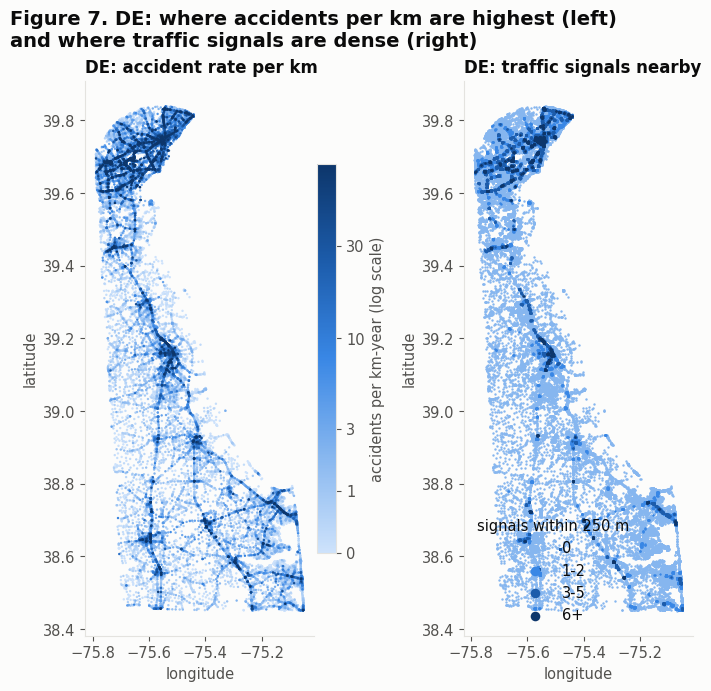

In [61]:
def plot_risk_map(state, info, analysis, max_points=60000):
    """Figure 7: a map of the state's roads. Left: accident rate per km-year. Right: traffic signals within 250 m."""
    apply_chart_style()
    levels, years = analysis["levels"], analysis["years"]
    nodes = pd.read_csv(next((info["filepath"] / "Nodes").glob("node_features_*.csv")))[["lat", "lon"]]
    nodes = nodes.rename(columns={"lat": "lon", "lon": "lat"})  # the release has the two columns swapped
    road_u = levels.index.get_level_values("road_u").to_numpy()
    road_v = levels.index.get_level_values("road_v").to_numpy()
    lat = (nodes["lat"].to_numpy()[road_u] + nodes["lat"].to_numpy()[road_v]) / 2
    lon = (nodes["lon"].to_numpy()[road_u] + nodes["lon"].to_numpy()[road_v]) / 2
    rate = levels["accidents"].to_numpy() / (levels["length_m"].to_numpy() / 1000 * years)
    value = np.log10(1 + rate)

    keep = np.arange(len(levels))
    if len(keep) > max_points:
        keep = np.random.default_rng(RANDOM_SEED).choice(keep, size=max_points, replace=False)
    keep = keep[np.argsort(value[keep])]  # low first, high last

    # Size each panel to the state's shape so a tall, narrow state does not leave empty space beside it.
    shape_ratio = (np.ptp(lon) * np.cos(np.radians(lat.mean()))) / max(np.ptp(lat), 1e-9)
    panel_width = float(np.clip(6.5 * shape_ratio, 3.0, 8.0))
    fig, (ax_rate, ax_signals) = plt.subplots(1, 2, figsize=(2 * panel_width + 1.2, 6.8), layout="constrained")
    drawn = ax_rate.scatter(lon[keep], lat[keep], c=value[keep], cmap=SEQ_CMAP, vmin=0, vmax=np.percentile(value, 99), s=3, linewidths=0, rasterized=True)
    colorbar = fig.colorbar(drawn, ax=ax_rate, shrink=0.7, pad=0.01)
    ticks = np.array([t for t in (0, 1, 3, 10, 30, 100, 300) if np.log10(1 + t) <= np.percentile(value, 99)])
    colorbar.set_ticks(np.log10(1 + ticks))
    colorbar.set_ticklabels([str(t) for t in ticks])
    colorbar.set_label("accidents per km-year (log scale)")
    ax_rate.set_title(f"{state}: accident rate per km")

    order = LEVEL_ORDER["signals_within_250m"]
    signal_level = levels["signals_within_250m"].to_numpy()
    for level, colour in zip(order, [BLUE_RAMP[1], BLUE_RAMP[2], BLUE_RAMP[3], BLUE_RAMP[4]]):
        mask = np.zeros(len(levels), dtype=bool)
        mask[keep] = signal_level[keep] == level
        ax_signals.scatter(lon[mask], lat[mask], color=colour, s=3, linewidths=0, rasterized=True, label=level)
    ax_signals.legend(title="signals within 250 m", markerscale=4, loc="lower left")
    ax_signals.set_title(f"{state}: traffic signals nearby")
    for ax in (ax_rate, ax_signals):
        ax.set_aspect(1 / np.cos(np.radians(lat.mean())))
        ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
    fig.suptitle(f"Figure 7. {state}: where accidents per km are highest (left)\nand where traffic signals are dense (right)", x=0.01, ha="left")
    save_figure(fig, f"fig10_map_{state}")
    plt.show()


for state in STATES:
    plot_risk_map(state, data[state], analyses[state][HEADLINE])

## Appendix B. Accident rate against each feature's value (Figure 8)
Each panel is one feature (from Stage 12.1). Dots are levels in order of value; the vertical line is the robust 95% interval; **filled** means the level clearly differs from comparable roads.
Only levels with enough accidents are drawn. The small text under each title is the share of roads where the value is known.

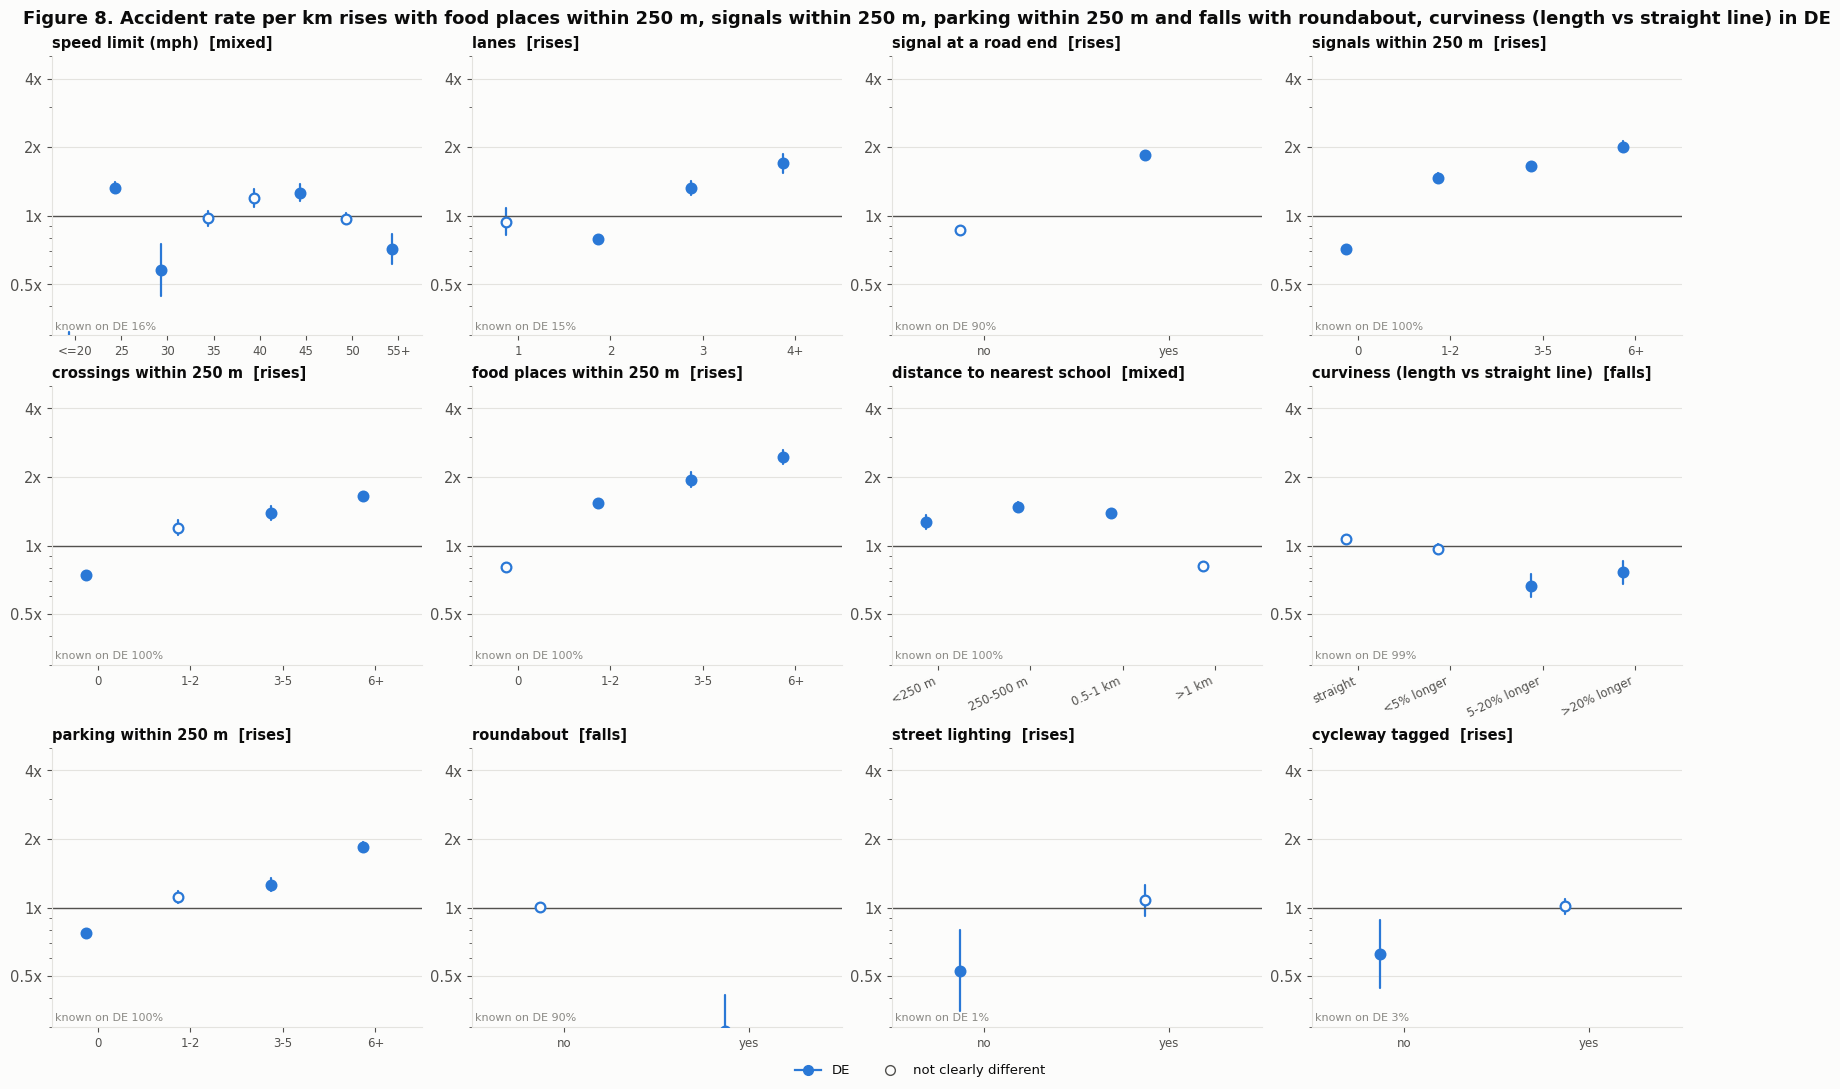

In [62]:
TREND_PANELS = ["speed_limit", "lanes", "signal_at_end", "signals_within_250m", "crossings_within_250m", "food_within_250m",
                "nearest_school", "sinuosity", "parking_within_250m", "roundabout", "lit", "cycleway"]


def trend_headline(analyses_window, panels):
    """A plain-language title from the data: the strongest trends that point the same way in both states."""
    states = list(analyses_window)
    rising, falling = [], []
    for variable in panels:
        trends = [analyses_window[s]["verdict"].get(("trend"), pd.Series(dtype=object)).get(variable) for s in states]
        if all(t == "rises" for t in trends):
            rising.append((variable, np.mean([np.log(analyses_window[s]["verdict"].loc[variable, "to_ratio"] / analyses_window[s]["verdict"].loc[variable, "from_ratio"]) for s in states])))
        elif all(t == "falls" for t in trends):
            falling.append((variable, np.mean([np.log(analyses_window[s]["verdict"].loc[variable, "to_ratio"] / analyses_window[s]["verdict"].loc[variable, "from_ratio"]) for s in states])))
    rising = [VARIABLE_LABELS[v] for v, _ in sorted(rising, key=lambda t: -abs(t[1]))[:3]]
    falling = [VARIABLE_LABELS[v] for v, _ in sorted(falling, key=lambda t: -abs(t[1]))[:3]]
    parts = []
    if rising:
        parts.append("rises with " + ", ".join(rising))
    if falling:
        parts.append("falls with " + ", ".join(falling))
    where = "in both states" if len(states) > 1 else f"in {states[0]}"
    return "Accident rate per km " + " and ".join(parts) + " " + where if parts else f"Few feature trends are clear {where}"


def plot_value_trends(analyses_window, panels, name, title_prefix):
    """Figure 8: small multiples of controlled rate ratio against feature value, both states."""
    apply_chart_style()
    states = list(analyses_window)

    def has_values(variable):   # drop panels where no state has any known value (an empty panel says nothing)
        return any(variable in analyses_window[s]["verdict"].index and analyses_window[s]["verdict"].loc[variable, "known_share_of_roads"] > 0 for s in states)
    dropped = [v for v in panels if not has_values(v)]
    panels = [v for v in panels if has_values(v)]
    if dropped:
        print("Not drawn (no known values in any state): " + ", ".join(VARIABLE_LABELS[v] for v in dropped))
    columns = 4
    rows = int(np.ceil(len(panels) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4.2 * columns, 3.4 * rows + 0.6), layout="constrained")
    for ax, variable in zip(np.ravel(axes), panels):
        order = LEVEL_ORDER[variable]
        for offset, state in zip((-0.13, 0.13), states):
            table = analyses_window[state]["controlled"]
            rows_v = table[table["variable"] == variable].set_index("level")
            for position, level in enumerate(order):
                if level not in rows_v.index or rows_v.loc[level, "accidents"] < MIN_ACCIDENTS_FOR_VERDICT:
                    continue
                r = rows_v.loc[level]
                colour = STATE_COLORS[state]
                ax.plot([position + offset] * 2, [max(r["low_used"], 0.05), r["high_used"]], color=colour, lw=1.6, solid_capstyle="round")
                ax.plot(position + offset, r["ratio_used"], "o", ms=7, mfc=colour if r["differs"] else SURFACE, mec=colour, mew=1.6, zorder=3)
        ax.axhline(1, color=INK_SECONDARY, lw=1)
        ax.set_yscale("log")
        ax.set_yticks([0.5, 1, 2, 4]); ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}x")); ax.get_yaxis().set_minor_formatter(plt.NullFormatter())
        ax.set_ylim(0.3, 5)
        ax.set_xticks(range(len(order))); ax.set_xticklabels(order, fontsize=8.5, rotation=0 if max(len(o) for o in order) <= 4 else 25, ha="center" if max(len(o) for o in order) <= 4 else "right")
        ax.set_xlim(-0.5, len(order) - 0.5)
        ax.yaxis.grid(True)
        directions = [analyses_window[s]["verdict"].loc[variable, "trend"] if variable in analyses_window[s]["verdict"].index else "n/a" for s in states]
        known = " / ".join("{} {:.0%}".format(s, analyses_window[s]["verdict"].loc[variable, "known_share_of_roads"]) if variable in analyses_window[s]["verdict"].index else s + " n/a" for s in states)
        ax.set_title(VARIABLE_LABELS[variable] + "  [" + " / ".join(directions) + "]", fontsize=10.5)
        ax.text(0.01, 0.02, "known on " + known, transform=ax.transAxes, fontsize=8, color=INK_MUTED)
    for ax in np.ravel(axes)[len(panels):]:
        ax.axis("off")
    handles = [Line2D([], [], color=STATE_COLORS[s], marker="o", ms=7, lw=1.6, label=s) for s in states]
    handles.append(Line2D([], [], color=INK_SECONDARY, marker="o", ms=7, mfc=SURFACE, lw=0, label="not clearly different"))
    fig.legend(handles=handles, loc="outside lower center", ncol=3, fontsize=9.5)
    fig.suptitle(title_prefix + ". " + trend_headline(analyses_window, panels), x=0.01, ha="left", fontsize=13)
    save_figure(fig, name)
    plt.show()


plot_value_trends(headline_analyses, TREND_PANELS, "fig5_value_trends", "Figure 8")